# Formula 1 Podium Prediction — Milestone 1

**Task:** binary classification — will a driver finish on the podium (`positionOrder <= 3`) in a given race?
**Unit of analysis:** one row per (raceId, driverId).
**Prediction cutoff:** after qualifying, before the race starts. Anything produced by the race itself
(results, status, points, laps, pit stops, lap times, post-race standings) is **not allowed as a feature**.

### Notebook structure
1. Setup & raw data audit
2. Data cleaning + EDA after cleaning
3. Data-engineering questions (Q1–Q3)
4. Feature engineering & justification
5. Train / validation / test split & preprocessing experiments
6. Modeling (baseline, statistical models, shallow NN)
7. Feature-group ablation
7B. Robustness experiments (rolling CV, seeds, era, race-relative features, refit)
8. Explainability (XAI)
9. Inference function
10. Limitations
### Executive summary
- **Data:** 14 Ergast tables, audited and cleaned into one row per (race, driver): 24,677 rows. Modeling uses 2003–2024
  (8,935 rows), the seasons with complete qualifying data. Split by season: train 2003–2019, validation 2020–2021,
  test 2022–2024.
- **Data-engineering answers:** Q1 front-row → podium conversion rose from 68.3% (2003–13) to 76.0% (2014–24), but the
  circuit ranking is unstable (ρ = 0.30). Q2 no detectable home advantage after controlling for grid (Mantel–Haenszel
  OR 0.95, 95% CI 0.79–1.12). Q3 mechanical retirements fell from 9.8% to 6.1% of starts; the constructor ranking is
  robust to how ambiguous statuses are classed (ρ = 0.97 / 0.69).
- **Features (8, all known before the race):** grid position, recent finishing percentile (15 races), finish rate
  (10 races), qualifying gap to pole, team podium rate (15 races), driver age, constructor standings rank, first-round flag.
  Leakage tested with a time-travel test (0 changed values at every cutoff).
- **Final model:** logistic regression (C = 10, median imputation + scaling), decision threshold 0.356.
- **Test result (2022–2024, 68 races):** PR-AUC 0.713, ROC-AUC 0.931, precision 0.605 / recall 0.721 / F1 0.658.
  It beats the no-ML grid rule by **+0.064 PR-AUC (95% CI +0.018 to +0.110)**. Random forest, gradient boosting and a
  shallow NN were not significantly different.
- **Robustness (Section 7B):** over 10 rolling seasons every learned model beats the grid rule in every season; the NN
  and random forest average ~0.01 PR-AUC higher than logistic regression, which is small next to the ~0.08
  season-to-season spread. C = 10 is confirmed, the 2003 training start beats both later starts (2010, 2014) and earlier ones (1980, 1994),
  race-relative features were not adopted, and refitting on 2003–2021 changes test PR-AUC by only +0.0006.
- **Main limitations:** the model is not better than the grid rule at naming the exact top 3; it covers 2003+ only;
  evaluation sets are small; feature importance is not causation (Section 10).


# 1. Setup & Raw Data Audit
All 14 tables are loaded **as raw strings** (`dtype=str, keep_default_na=False`) so that nothing is silently
converted. This lets us count placeholder values exactly as they appear in the files. The `RAW` dictionary is
never modified; all cleaning in Section 2 happens on copies, as the brief requires.

In [1]:
import os, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings('ignore')
SEED = 42; np.random.seed(SEED)
sns.set_theme(style='whitegrid'); plt.rcParams['figure.figsize'] = (11, 4)

DATA_DIR = os.path.dirname(glob.glob('/kaggle/input/**/results.csv', recursive=True)[0])
TABLES = ['circuits','constructors','constructor_results','constructor_standings','drivers',
          'driver_standings','races','results','qualifying','lap_times','pit_stops',
          'sprint_results','seasons','status']

# RAW = immutable copies (read as strings so nothing is silently coerced)
RAW = {t: pd.read_csv(f'{DATA_DIR}/{t}.csv', dtype=str, keep_default_na=False) for t in TABLES}
display(pd.DataFrame({t: [len(d), d.shape[1]] for t, d in RAW.items()}, index=['rows','cols']).T)

# Fingerprint of every raw table: re-checked at the end of Section 2 to prove RAW was never modified
RAW_FINGERPRINT = {t: pd.util.hash_pandas_object(d, index=True).sum() for t, d in RAW.items()}

def save(name):
    os.makedirs('figs', exist_ok=True)
    plt.savefig(f'figs/{name}.png', dpi=150, bbox_inches='tight'); plt.show()

,rows,cols
circuits,77,9
constructors,212,5
constructor_results,12625,5
constructor_standings,13391,7
drivers,861,9
driver_standings,34863,7
races,1125,18
results,26759,18
qualifying,10494,9
lap_times,589081,6


,table,column,token,count,pct
0,constructor_results,status,'\\N',12608,99.87
13,races,sprint_time,'\\N',1110,98.67
12,races,sprint_date,'\\N',1107,98.40
9,races,fp3_time,'\\N',1072,95.29
11,races,quali_time,'\\N',1057,93.96
5,races,fp1_time,'\\N',1057,93.96
7,races,fp2_time,'\\N',1057,93.96
8,races,fp3_date,'\\N',1053,93.60
1,drivers,number,'\\N',802,93.15
10,races,quali_date,'\\N',1035,92.00


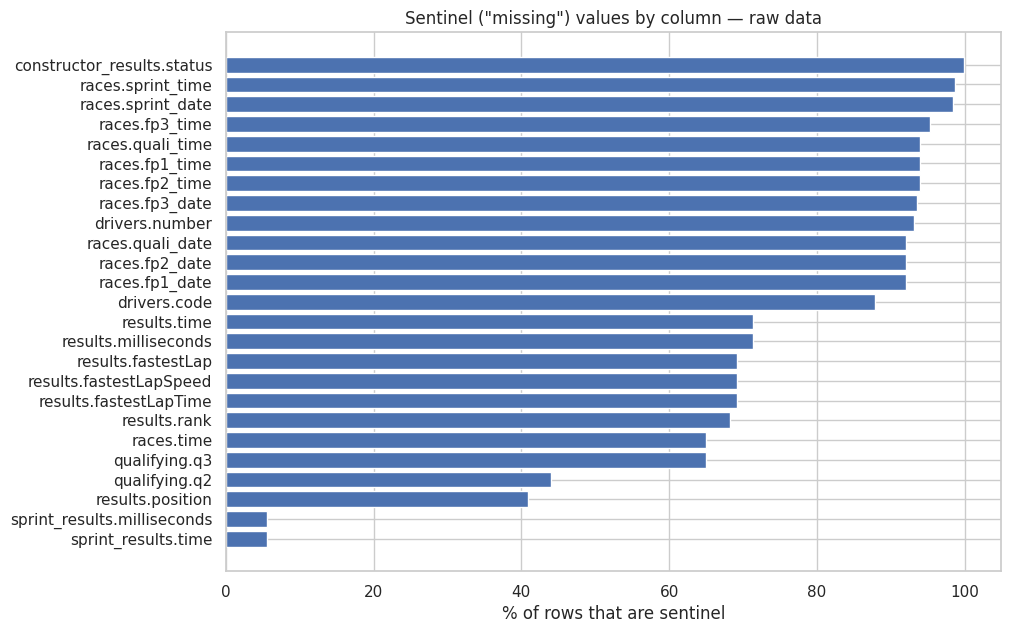

{"''": 68, "'\\\\N'": 160076} | distinct columns with a sentinel: 30


In [2]:
SENTINELS = ['\\N', '', 'NA', 'NaN', 'null', 'None']
rows = []
for t, df in RAW.items():
    for c in df.columns:
        for tok in SENTINELS:
            n = (df[c] == tok).sum()
            if n: rows.append((t, c, repr(tok), n, round(100*n/len(df), 2)))
sent = pd.DataFrame(rows, columns=['table','column','token','count','pct']).sort_values('pct', ascending=False)
display(sent)

top = sent.head(25)
plt.figure(figsize=(10, 7))
plt.barh(top.table + '.' + top.column, top.pct); plt.gca().invert_yaxis()
plt.xlabel('% of rows that are sentinel'); plt.title('Sentinel ("missing") values by column — raw data')
save('sentinels_raw')
print(sent.groupby('token')['count'].sum().to_dict(), '| distinct columns with a sentinel:',
      sent[['table', 'column']].drop_duplicates().shape[0])

In [3]:
# Is missingness structural? Check each high-missing column against what explains it
t = RAW['results'].merge(RAW['status'], on='statusId')
t['outcome'] = np.where(t.status == 'Finished', 'Finished',
               np.where(t.status.str.startswith('+'), '+N Laps', 'Other (retired, DNQ, ...)'))
display(t.groupby('outcome').time.apply(lambda s: (s != '\\N').mean()).rename('share with a race time').to_frame())

t['position_missing'] = t.position == '\\N'
display(pd.crosstab(t.position_missing, t.positionText.str.isdigit(), rownames=['position missing'], colnames=['positionText is a number']))
display(t[t.position_missing].positionText.value_counts().to_frame('rows'))

q_chk = RAW['qualifying'].merge(RAW['races'][['raceId', 'year']], on='raceId')
q_chk = q_chk[q_chk.year.astype(int) >= 2006]
q_chk['quali_bucket'] = pd.cut(q_chk.position.astype(int), [0, 10, 15, 16, 99], labels=['P1–10', 'P11–15', 'P16', 'P17+'])
display(q_chk.groupby('quali_bucket', observed=True).agg(
    q2_missing=('q2', lambda s: s.isin(SENTINELS).mean()),
    q3_missing=('q3', lambda s: s.isin(SENTINELS).mean())).round(3))
print(sent.groupby('token')['count'].sum().to_dict(), '| distinct columns with a sentinel:',
      sent[['table', 'column']].drop_duplicates().shape[0])

,share with a race time
outcome,
+N Laps,0.000134
Finished,0.999870
"Other (retired, DNQ, ...)",0.000517


positionText is a number,False,True
position missing,,
False,0,15806
True,10951,2


,rows
positionText,
R,8897
F,1368
W,336
N,190
D,151
E,9
11,1
14,1


,q2_missing,q3_missing
quali_bucket,,
P1–10,0.000,0.033
P11–15,0.039,0.999
P16,0.648,0.997
P17+,0.970,1.000


{"''": 68, "'\\\\N'": 160076} | distinct columns with a sentinel: 30


### Findings — sentinel values
- The dataset uses the literal string `\N` as its missing-value placeholder (~160k occurrences across 30 columns).
  A second sentinel, the empty string `''`, appears 68 times, all in `qualifying.q2/q3`. Both mean "no value".
  No `NA`/`null`/`NaN` tokens exist.
- Missingness is **structural, not random** (verified in the cell above):
  - `results.time`: present for 99.99% of "Finished" rows and ~0% of all others, so it records the race time of
    lead-lap finishers only.
  - `results.position`: missing in 10,951 rows, and in almost all of them `positionText` is a letter code
    (R 8,897, F 1,368, W 336, N 190, D 151, E 9), meaning the driver was not classified.
  - `qualifying.q2/q3` (2006+): q3 is missing for ~100% of drivers who qualified P11+ but only 3% of P1–10.
    The missing value means "did not reach that session", not an error.
- **Decision:** convert `\N` → `NaN` in Section 2, and treat q2/q3 missingness as information
  ("did not reach Q2/Q3"), not as an error to impute.

In [4]:
PK = {'circuits':['circuitId'], 'constructors':['constructorId'], 'drivers':['driverId'],
      'races':['raceId'], 'results':['resultId'], 'qualifying':['qualifyId'], 'status':['statusId'],
      'seasons':['year'], 'constructor_results':['constructorResultsId'],
      'constructor_standings':['constructorStandingsId'], 'driver_standings':['driverStandingsId'],
      'sprint_results':['resultId'], 'lap_times':['raceId','driverId','lap'],
      'pit_stops':['raceId','driverId','stop']}

def check_pk(t, cols):
    k = RAW[t][cols]
    return dict(table=t, pk='+'.join(cols), rows=len(k),
                null_keys=int(k.isin(SENTINELS).any(axis=1).sum()),
                duplicate_keys=int(k.duplicated().sum()))
pk_report = pd.DataFrame([check_pk(t, c) for t, c in PK.items()])
display(pk_report)

,table,pk,rows,null_keys,duplicate_keys
0,circuits,circuitId,77,0,0
1,constructors,constructorId,212,0,0
2,drivers,driverId,861,0,0
3,races,raceId,1125,0,0
4,results,resultId,26759,0,0
5,qualifying,qualifyId,10494,0,0
6,status,statusId,139,0,0
7,seasons,year,75,0,0
8,constructor_results,constructorResultsId,12625,0,0
9,constructor_standings,constructorStandingsId,13391,0,0


In [5]:
FK = [('results','raceId','races','raceId'), ('results','driverId','drivers','driverId'),
      ('results','constructorId','constructors','constructorId'), ('results','statusId','status','statusId'),
      ('qualifying','raceId','races','raceId'), ('qualifying','driverId','drivers','driverId'),
      ('qualifying','constructorId','constructors','constructorId'),
      ('races','circuitId','circuits','circuitId'), ('races','year','seasons','year'),
      ('driver_standings','raceId','races','raceId'), ('driver_standings','driverId','drivers','driverId'),
      ('constructor_standings','raceId','races','raceId'),
      ('constructor_standings','constructorId','constructors','constructorId'),
      ('constructor_results','raceId','races','raceId'),
      ('lap_times','raceId','races','raceId'), ('lap_times','driverId','drivers','driverId'),
      ('pit_stops','raceId','races','raceId'), ('pit_stops','driverId','drivers','driverId'),
      ('sprint_results','raceId','races','raceId'), ('sprint_results','driverId','drivers','driverId'),
      ('sprint_results','statusId','status','statusId'),
      ('constructor_results','constructorId','constructors','constructorId'),
      ('sprint_results','constructorId','constructors','constructorId')]

def check_fk(child, ccol, parent, pcol):
    v = RAW[child][ccol]; v = v[~v.isin(SENTINELS)]
    orphan = ~v.isin(set(RAW[parent][pcol]))
    return dict(fk=f'{child}.{ccol} → {parent}.{pcol}', checked=len(v),
                orphans=int(orphan.sum()), examples=list(v[orphan].unique()[:5]))
fk_report = pd.DataFrame([check_fk(*f) for f in FK])
display(fk_report)

# Composite foreign keys: (raceId, driverId) in child tables must exist in results
res_pairs = set(zip(RAW['results'].raceId, RAW['results'].driverId))
comp = []
for child in ['lap_times', 'pit_stops', 'sprint_results', 'qualifying', 'driver_standings']:
    pairs = list(zip(RAW[child].raceId, RAW[child].driverId))
    orphan = [p for p in pairs if p not in res_pairs]
    comp.append({'fk': f'{child}.(raceId, driverId) → results', 'checked': len(pairs),
                 'orphans': len(orphan), 'examples': orphan[:3]})
display(pd.DataFrame(comp))

# Why do some driver_standings rows have no results row? Check: had that driver already raced earlier in the season?
ds = RAW['driver_standings'][['raceId', 'driverId']].copy()
ds['orphan'] = [p not in res_pairs for p in zip(ds.raceId, ds.driverId)]
rr = RAW['races'][['raceId', 'year', 'round']].astype({'year': int, 'round': int})
ds = ds.merge(rr, on='raceId')
first_raced = (RAW['results'][['raceId', 'driverId']].merge(rr, on='raceId')
               .groupby(['driverId', 'year'])['round'].min().rename('first_round_raced'))
o = ds[ds.orphan].join(first_raced, on=['driverId', 'year'])
print(f"Orphan driver_standings rows: {len(o)} ({len(o) / len(ds):.1%}) | seasons {o.year.min()}–{o.year.max()} | "
      f"driver had already raced earlier that season: {(o.first_round_raced < o['round']).mean():.1%}")


,fk,checked,orphans,examples
0,results.raceId → races.raceId,26759,0,[]
1,results.driverId → drivers.driverId,26759,0,[]
2,results.constructorId → constructors.construct...,26759,0,[]
3,results.statusId → status.statusId,26759,0,[]
4,qualifying.raceId → races.raceId,10494,0,[]
5,qualifying.driverId → drivers.driverId,10494,0,[]
6,qualifying.constructorId → constructors.constr...,10494,0,[]
7,races.circuitId → circuits.circuitId,1125,0,[]
8,races.year → seasons.year,1125,0,[]
9,driver_standings.raceId → races.raceId,34863,0,[]


,fk,checked,orphans,examples
0,"lap_times.(raceId, driverId) → results",589081,0,[]
1,"pit_stops.(raceId, driverId) → results",11371,0,[]
2,"sprint_results.(raceId, driverId) → results",360,0,[]
3,"qualifying.(raceId, driverId) → results",10494,0,[]
4,"driver_standings.(raceId, driverId) → results",34863,8664,"[(22, 19), (22, 11), (23, 19)]"


Orphan driver_standings rows: 8664 (24.9%) | seasons 1950–2024 | driver had already raced earlier that season: 100.0%


### Findings — primary & foreign keys
- **Primary keys:** all 14 tables have unique, non-null primary keys (0 nulls, 0 duplicates), including
  the composite keys of `lap_times` (raceId, driverId, lap) and `pit_stops` (raceId, driverId, stop).
- **Foreign keys:** all 23 single-column relationships between the 14 tables were checked (tables above), plus 5
  composite (raceId, driverId) links from lap_times, pit_stops, sprint_results, qualifying and driver_standings to
  results. All 23 single-column links and 4 of the 5 composite links have **0 orphans**.
  The exception is `driver_standings`: **8,664 rows (24.9%) have no results row for that race**. The check above shows
  that in every one of them the driver had already raced earlier that season: the standings table keeps listing a
  driver's season position after races he did not enter. These rows are expected, not errors, and they never reach the
  model, because the base table is built from `results` and standings are only joined onto existing results rows.
- **Conclusion:** the joins we need later are safe; no rows will be lost or duplicated by a broken key.
  Note that `resultId` being unique does **not** guarantee our modeling grain (raceId, driverId), which
  is checked separately below.

Rows involved in duplicates: 176 | races affected: 42


,year,name,raceId,driverId,constructorId,number,grid,positionOrder,points,laps,statusId
0,1978,Italian Grand Prix,540,229,54,10,0,26,0,0,81
1,1978,Italian Grand Prix,540,229,57,23,0,29,0,0,97
2,1964,United States Grand Prix,717,373,172,1,1,7,0,102,60
175,1964,United States Grand Prix,717,373,172,2,1,12,0,54,98
3,1962,British Grand Prix,733,465,172,48,0,22,0,0,54
4,1962,British Grand Prix,733,465,97,50,0,25,0,0,54
5,1961,British Grand Prix,742,475,102,26,20,19,0,56,2
6,1961,British Grand Prix,742,475,172,28,5,21,0,44,23
7,1961,United States Grand Prix,745,418,172,22,11,17,0,23,6
174,1961,United States Grand Prix,745,418,172,21,15,11,0,92,18


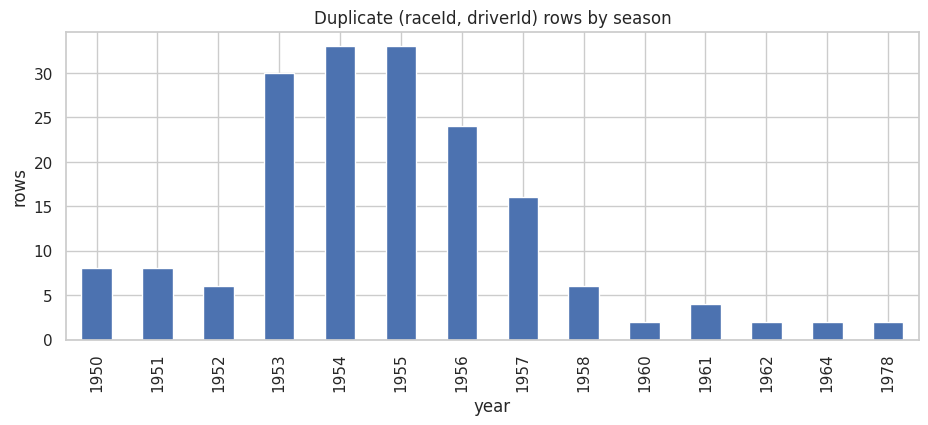

Duplicate rows in 1953–1956: 120 of 176
Pairs where the rows have different car numbers: 85 of 85


In [6]:
res, races = RAW['results'], RAW['races']
dup_mask = res.duplicated(['raceId','driverId'], keep=False)
dups = res[dup_mask].merge(races[['raceId','year','name']], on='raceId')
print(f'Rows involved in duplicates: {dup_mask.sum()} | races affected: {dups.raceId.nunique()}')
display(dups.sort_values(['raceId','driverId'])[['year','name','raceId','driverId','constructorId',
        'number','grid','positionOrder','points','laps','statusId']].head(20))

dups.year.astype(int).value_counts().sort_index().plot(kind='bar', title='Duplicate (raceId, driverId) rows by season')
plt.ylabel('rows'); save('duplicates_by_season')
print('Duplicate rows in 1953–1956:', dups.year.astype(int).between(1953, 1956).sum(), 'of', len(dups))
pair_diff = dups.groupby(['raceId', 'driverId']).agg(n_numbers=('number', 'nunique'), n_constructors=('constructorId', 'nunique'))
print('Pairs where the rows have different car numbers:', (pair_diff.n_numbers > 1).sum(), 'of', len(pair_diff))

### Findings — grain violation (raceId, driverId)
- **176 rows / 85 driver-race pairs / 42 races** violate the one-row-per-driver-per-race grain
  (a few pairs appear 3 times).
- They are concentrated in **1953–1956** (120 of 176 rows) and the last one is in 1978.
- In **all 85 pairs the two rows have different car numbers** (printed above), so each duplicate is a second car for
  the same driver in the same race, consistent with the shared drives described in the course F1 primer.
- A simple rule like "keep the row with a non-zero grid" **would not work**: see the pair table in Section 2.3.
  The keep-rule is chosen and justified there.

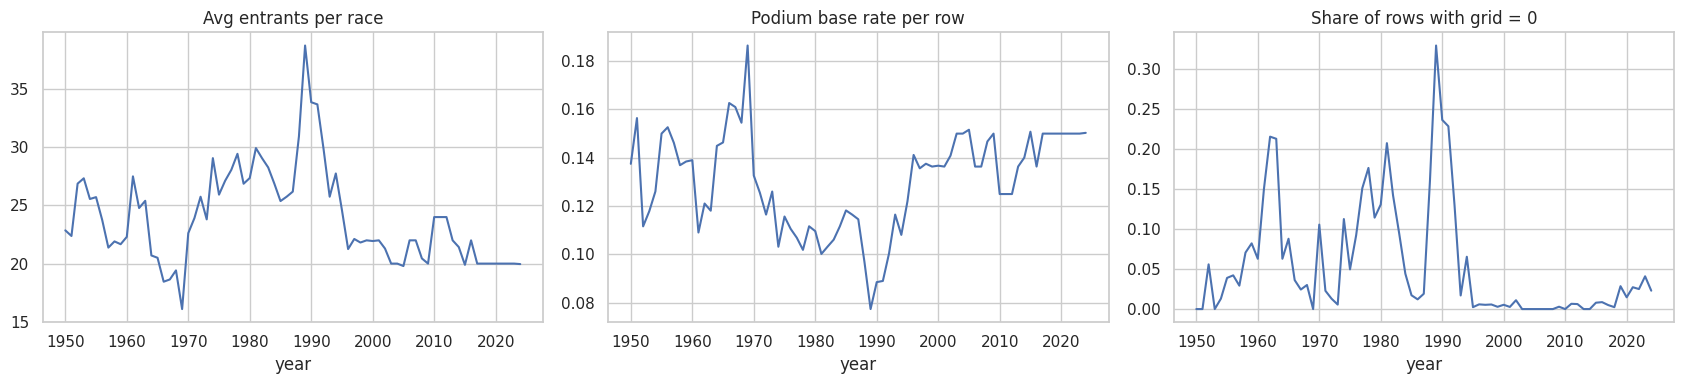

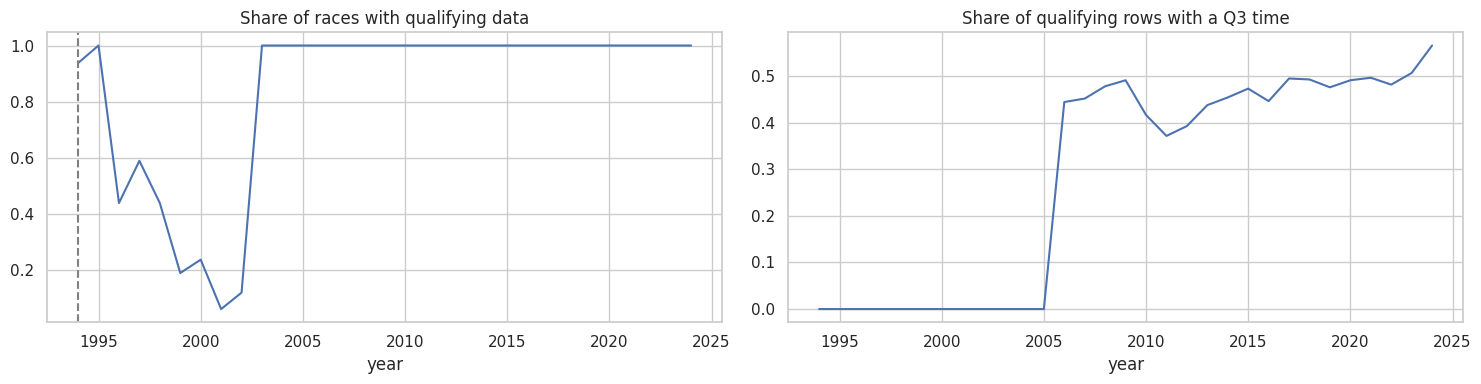

Indy 500 races: 11 | rows: 405 | years: 1950–1960


,avg entrants per race,podium rate,grid=0 share
year,,,
1950,22.857,0.138,0.000
1989,38.750,0.077,0.329
2024,19.958,0.150,0.023


grid=0 share, mean from 1995: 0.008


,share of races with qualifying
year,
1994,0.94
1995,1.00
1996,0.44
1997,0.59
1998,0.44
1999,0.19
2000,0.24
2001,0.06
2002,0.12


In [7]:
r = res.merge(races[['raceId','year','name']], on='raceId')
r['year'] = r.year.astype(int); r['positionOrder'] = r.positionOrder.astype(int); r['grid'] = r.grid.astype(int)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
r.groupby(['year','raceId']).size().groupby('year').mean().plot(ax=ax[0], title='Avg entrants per race')
(r.positionOrder <= 3).groupby(r.year).mean().plot(ax=ax[1], title='Podium base rate per row')
(r.grid == 0).groupby(r.year).mean().plot(ax=ax[2], title='Share of rows with grid = 0')
plt.tight_layout(); save('eda_before')

# Qualifying coverage drift (the "known limitation" the brief mentions)
q = RAW['qualifying'].merge(races[['raceId','year']], on='raceId'); q['year'] = q.year.astype(int)
all_years = sorted(races.year.astype(int).unique())
cov = (q.groupby('year').raceId.nunique() / races.assign(year=races.year.astype(int)).groupby('year').raceId.nunique()).reindex(all_years, fill_value=0)
q3_share = (q.q3 != '\\N').groupby(q.year).mean().reindex(all_years)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
cov.plot(ax=ax[0], title='Share of races with qualifying data'); ax[0].axvline(1994, ls='--', c='grey')
q3_share.plot(ax=ax[1], title='Share of qualifying rows with a Q3 time')
plt.tight_layout(); save('quali_coverage')

# Indianapolis 500 rows (1950–1960 oddity)
indy = r[r.name.str.contains('Indianapolis', case=False)]
print(f'Indy 500 races: {indy.raceId.nunique()} | rows: {len(indy)} | years: {indy.year.min()}–{indy.year.max()}')
yrs = [1950, 1989, 2024]
display(pd.DataFrame({
    'avg entrants per race': r.groupby(['year', 'raceId']).size().groupby('year').mean().loc[yrs],
    'podium rate': (r.positionOrder <= 3).groupby(r.year).mean().loc[yrs],
    'grid=0 share': (r.grid == 0).groupby(r.year).mean().loc[yrs]}).round(3))
print('grid=0 share, mean from 1995:', round((r.grid == 0).groupby(r.year).mean().loc[1995:].mean(), 3))
display(cov.loc[1994:2003].round(2).to_frame('share of races with qualifying'))

### Findings — EDA before cleaning
- **Field size changed a lot:** 22.9 entrants per race in 1950, peaking at 38.8 in 1989, down to 20.0 in 2024 (table above).
- **Podium base rate depends on field size:** 7.7% of rows in 1989 vs 15.0% in 2024. Classes are imbalanced
  in every era, so accuracy is a misleading metric → we use PR-AUC as the primary metric.
- **grid = 0 is an era artefact:** 32.9% of rows in 1989, but 0.8% on average from 1995 onward.
- **Qualifying-coverage drift:** `qualifying.csv` starts in 1994, is patchy from 1996 to 2002 (6–59% of
  races), and is **complete from 2003 onward**. Q3 times only exist from 2006 onward (plot above).
- **Indianapolis 500:** 11 races / 405 rows (1950–1960), examined in Section 2.4.
- **Implications for later sections:** qualifying features are only reliable from 2003, so the modeling
  window and the grid-vs-qualifying choice are decided from this evidence (Section 4). The Indy 500 and
  non-starters are handled in Section 2.


# 2. Data Cleaning
All cleaning is done on copies (`CLEAN`); the `RAW` dictionary from Section 1 is never modified.
Order of operations: sentinels → semantic typing → outlier check → grain fix → scope filters → joined base table → EDA after cleaning.

In [8]:
def save(name):
    os.makedirs('figs', exist_ok=True)
    plt.savefig(f'figs/{name}.png', dpi=150, bbox_inches='tight'); plt.show()

NA_TOKENS = ['\\N', '']                                   # both sentinels found in Section 1
CLEAN = {t: d.replace(NA_TOKENS, np.nan) for t, d in RAW.items()}   # copies, RAW untouched

def auto_numeric(df):
    """Convert a column to numeric only if EVERY non-missing value parses (so 'R', 'HAM', '1:26.5' stay text)."""
    for c in df.columns:
        conv = pd.to_numeric(df[c], errors='coerce')
        if conv.notna().sum() == df[c].notna().sum():
            df[c] = conv
    return df
CLEAN = {t: auto_numeric(d) for t, d in CLEAN.items()}

def to_seconds(s):
    """'23.4' -> 23.4 ; '1:26.572' -> 86.572 ; '2:05:05.152' -> 7505.152 (handles h:mm:ss)"""
    s = s.astype('string')
    p = s.str.split(':', expand=True).reindex(columns=[0, 1, 2]).apply(pd.to_numeric, errors='coerce')
    n = s.str.count(':').astype(float)
    return pd.Series(np.where(n == 0, p[0], np.where(n == 1, p[0] * 60 + p[1], p[0] * 3600 + p[1] * 60 + p[2])),
                     index=s.index, dtype=float)

DURATIONS = {'qualifying': ['q1','q2','q3'], 'results': ['fastestLapTime'],
             'sprint_results': ['fastestLapTime'], 'pit_stops': ['duration'], 'lap_times': ['time']}
DATES = {'races': ['date','fp1_date','fp2_date','fp3_date','quali_date','sprint_date'], 'drivers': ['dob']}

parse_log = []
for t, cols in DURATIONS.items():
    for c in cols:
        before = CLEAN[t][c].notna().sum()
        CLEAN[t][c + '_s'] = to_seconds(CLEAN[t][c])
        parse_log.append(dict(column=f'{t}.{c}', non_missing=before, parsed=CLEAN[t][c+'_s'].notna().sum()))
for t, cols in DATES.items():
    for c in cols:
        before = CLEAN[t][c].notna().sum()
        CLEAN[t][c] = pd.to_datetime(CLEAN[t][c], errors='coerce')
        parse_log.append(dict(column=f'{t}.{c}', non_missing=before, parsed=CLEAN[t][c].notna().sum()))
parse_log = pd.DataFrame(parse_log); parse_log['lost'] = parse_log.non_missing - parse_log.parsed
display(parse_log)

display(pd.DataFrame({t: [RAW[t].dtypes.astype(str).value_counts().to_dict(),
                          CLEAN[t].dtypes.astype(str).value_counts().to_dict()] for t in TABLES},
                     index=['raw dtypes', 'clean dtypes']).T)
print('Sentinels left in CLEAN:', sum(d.isin(NA_TOKENS).sum().sum() for d in CLEAN.values()))

# Parser validation: lap_times and pit_stops store each time twice (text + milliseconds)
for t, sec_col in [('lap_times', 'time_s'), ('pit_stops', 'duration_s')]:
    diff_ms = (CLEAN[t][sec_col] * 1000 - CLEAN[t]['milliseconds']).abs()
    print(f'{t}: {CLEAN[t][sec_col].notna().sum():,} parsed | max difference vs milliseconds column = {diff_ms.max():.6f} ms')

,column,non_missing,parsed,lost
0,qualifying.q1,10338,10338,0
1,qualifying.q2,5847,5847,0
2,qualifying.q3,3629,3629,0
3,results.fastestLapTime,8252,8252,0
4,sprint_results.fastestLapTime,351,351,0
5,pit_stops.duration,11371,11371,0
6,lap_times.time,589081,589081,0
7,races.date,1125,1125,0
8,races.fp1_date,90,90,0
9,races.fp2_date,90,90,0


,raw dtypes,clean dtypes
circuits,{'object': 9},"{'object': 5, 'int64': 2, 'float64': 2}"
constructors,{'object': 5},"{'object': 4, 'int64': 1}"
constructor_results,{'object': 5},"{'int64': 3, 'float64': 1, 'object': 1}"
constructor_standings,{'object': 7},"{'int64': 5, 'float64': 1, 'object': 1}"
drivers,{'object': 9},"{'object': 6, 'int64': 1, 'float64': 1, 'datet..."
driver_standings,{'object': 7},"{'int64': 5, 'float64': 1, 'object': 1}"
races,{'object': 18},"{'object': 8, 'datetime64[ns]': 6, 'int64': 4}"
results,{'object': 18},"{'int64': 8, 'float64': 8, 'object': 3}"
qualifying,{'object': 9},"{'int64': 6, 'object': 3, 'float64': 3}"
lap_times,{'object': 6},"{'int64': 5, 'object': 1, 'float64': 1}"


Sentinels left in CLEAN: 0
lap_times: 589,081 parsed | max difference vs milliseconds column = 0.000000 ms
pit_stops: 11,371 parsed | max difference vs milliseconds column = 0.000000 ms


### Sentinels & semantic typing
- Both sentinels (`\N` and `''`) are replaced by `NaN`; **0 sentinels remain** after cleaning.
- A column is converted to numeric **only if every non-missing value parses**. This prevents silently destroying
  text columns such as `positionText` ("R", "D") or driver codes ("HAM").
- **Durations** (`q1/q2/q3`, `fastestLapTime`, pit-stop `duration`, `lap_times.time`) are converted from `"m:ss.sss"` strings into
  numeric seconds (`*_s` columns); **dates** (`races.date`, session dates, `drivers.dob`) into datetimes.
- **Validation:** for every converted column, `lost = 0`, so every non-missing value parsed successfully.
- **Parser check:** `lap_times` and `pit_stops` store each time twice (text and milliseconds). Our parsed seconds match
  the millisecond columns to within floating-point error (printed above), including laps longer than one hour
  stored as `h:mm:ss`.

,lap time / session median
0.500,1.000
0.990,1.047
0.999,1.140


Values above 1.2x: 12 | above 1.3x: 5 | above 1.5x: 2


,column,raceId,value_s,x_race_median,year,circuitId,circuitRef
0,q1_s,255,1002.640,9.88,1995,22,suzuka
1,q2_s,1107,126.688,1.94,2023,70,red_bull_ring


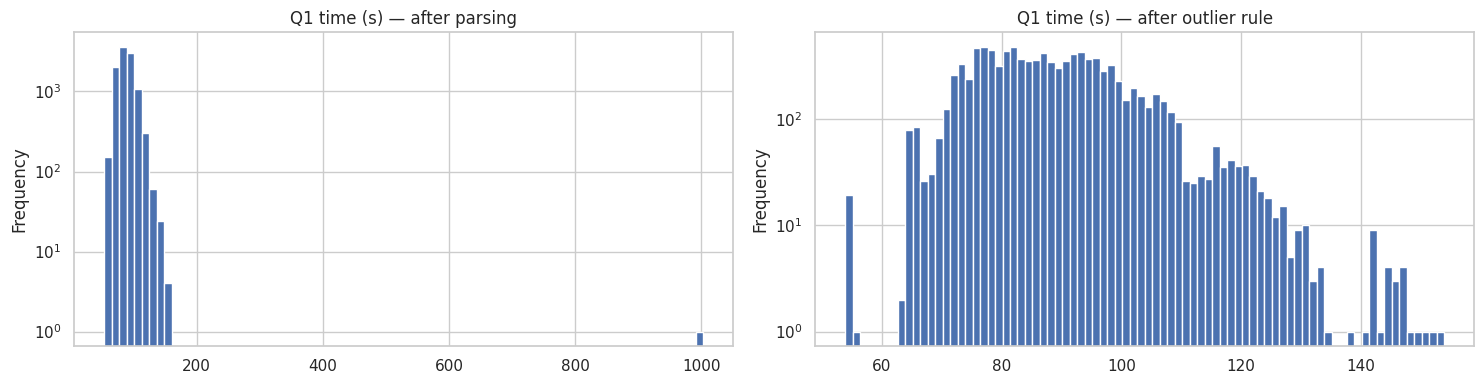

In [9]:
q = CLEAN['qualifying']
for c in ['q1', 'q2', 'q3']:                       # rebuild from the text times -> cell is safe to re-run
    q[c + '_s'] = to_seconds(q[c])

# How far from the session median do real qualifying times go?
rel_all = pd.concat([q[c] / q.groupby('raceId')[c].transform('median') for c in ['q1_s', 'q2_s', 'q3_s']]).dropna()
display(rel_all.quantile([0.5, 0.99, 0.999]).round(3).to_frame('lap time / session median'))
print('Values above 1.2x:', (rel_all > 1.2).sum(), '| above 1.3x:', (rel_all > 1.3).sum(), '| above 1.5x:', (rel_all > 1.5).sum())

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
q['q1_s'].plot(kind='hist', bins=80, ax=ax[0], title='Q1 time (s) — after parsing', logy=True)

outlier_log = []
for c in ['q1_s', 'q2_s', 'q3_s']:
    rel = q[c] / q.groupby('raceId')[c].transform('median')
    bad = rel > 1.5
    outlier_log += [dict(column=c, raceId=r, value_s=v, x_race_median=round(x, 2))
                    for r, v, x in zip(q.loc[bad, 'raceId'], q.loc[bad, c], rel[bad])]
    q.loc[bad, c] = np.nan

outliers = pd.DataFrame(outlier_log, columns=['column', 'raceId', 'value_s', 'x_race_median'])
display(outliers.merge(CLEAN['races'][['raceId', 'year', 'circuitId']], on='raceId')
                .merge(CLEAN['circuits'][['circuitId', 'circuitRef']], on='circuitId'))

q['q1_s'].plot(kind='hist', bins=80, ax=ax[1], title='Q1 time (s) — after outlier rule', logy=True)
plt.tight_layout(); save('quali_times_outliers')

### Qualifying-time outliers
- Lap times differ by circuit, so each time is compared to the **median of its own session**.
- Rule: 99.9% of all qualifying times are within **1.14×** their session median (table above). A threshold of
  **1.5×** is far outside normal variation and only flags values that cannot be real flying laps.
  It removes 2 values, versus 12 at 1.2×, so the rule is deliberately conservative.
- Only **2 values** were affected: a Q1 time of 1002.6 s (16:42, 9.9× median, Suzuka 1995) and a Q2 time of
  126.7 s (1.9× median, Austria 2023). The histogram's right tail disappears after the rule.

In [10]:
res = CLEAN['results'].merge(CLEAN['races'][['raceId', 'year', 'name']], on='raceId')
KEY = ['raceId', 'driverId']
dup = res[res.duplicated(KEY, keep=False)]

# Two candidate rules, compared before choosing
rule_best = dup.sort_values('positionOrder').drop_duplicates(KEY)                                      # best finish
rule_laps = dup.sort_values(['laps', 'positionOrder'], ascending=[False, True]).drop_duplicates(KEY)   # car driven longest
cmp = rule_best.merge(rule_laps, on=KEY, suffixes=('_best', '_laps'))
print(f"Duplicate pairs: {len(cmp)}")
print(f"Pairs where the two rules keep a different row: {(cmp.resultId_best != cmp.resultId_laps).sum()}")
print(f"Pairs where the podium label would differ: {((cmp.positionOrder_best <= 3) != (cmp.positionOrder_laps <= 3)).sum()}")
print(f"Latest season with a duplicate: {dup.year.max()}")

res_dedup = res.sort_values(KEY + ['positionOrder']).drop_duplicates(KEY, keep='first')
assert not res_dedup.duplicated(KEY).any()
print(f"Rows: {len(res)} -> {len(res_dedup)} (removed {len(res) - len(res_dedup)})")
both = dup.assign(nonzero=dup.grid > 0).groupby(KEY).nonzero.sum().value_counts().sort_index()
display(both.rename_axis('rows with grid > 0 in the pair').to_frame('pairs'))

Duplicate pairs: 85
Pairs where the two rules keep a different row: 0
Pairs where the podium label would differ: 0
Latest season with a duplicate: 1978
Rows: 26759 -> 26668 (removed 91)


,pairs
rows with grid > 0 in the pair,
0,3
2,76
3,6


### Grain fix — duplicate handling rule
**Rule chosen: for each (raceId, driverId), keep the row with the best (lowest) `positionOrder`.**

Why:
1. **It preserves the label.** Keeping the best `positionOrder` means a driver is labelled podium if any car he drove
   in that race finished on the podium. No podium recorded in the data is lost.
2. **It is robust.** We compared it to an alternative rule (keep the car the driver drove the most laps in).
   Both rules keep **the same row in all 85 pairs**, so **0 podium labels change**. The choice does not drive any result.
3. **"Keep the row with non-zero grid" was rejected.** The table above shows both rows have a non-zero grid in 76 of 85 pairs (and all three rows in 6 triples).
4. **No impact on the modeling era.** The last duplicate is in 1978, so it only affects the historical analysis.

Result: 26,759 → **26,668 rows** (91 removed); (raceId, driverId) is now unique (asserted).

status,107% Rule,Did not prequalify,Did not qualify,Withdrew
year,,,,
"(1949, 1970]",0,3,148,154
"(1970, 1980]",0,31,319,33
"(1980, 1995]",0,296,541,27
"(1995, 2024]",9,0,16,33


,rows
raw results,26759
after grain fix,26668
minus non-starters,25058
minus Indy 500 (final),24677


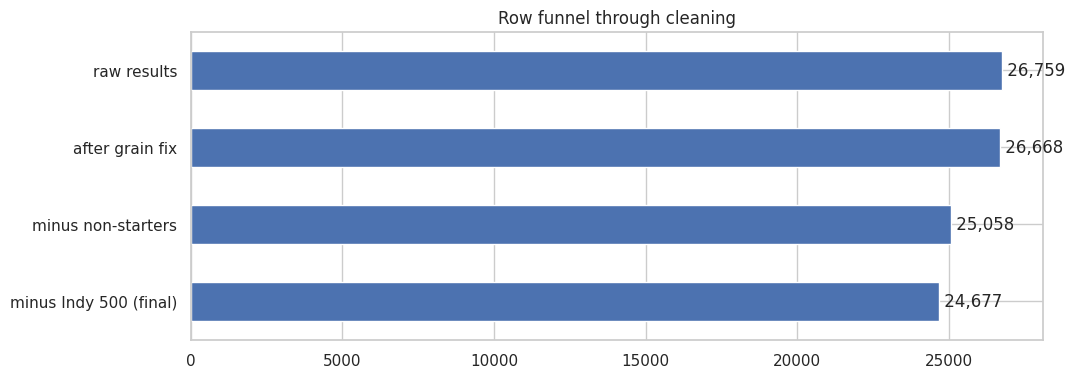

,rows,share_laps_0,share_grid_0
non_starter,,,
False,25058,0.038,0.005
True,1610,0.985,0.936


Indy 500 drivers: 107 | share who raced ONLY the Indy 500 (1950–60): 0.972


,avg entrants per race (1950–60)
indy,
False,21.2
True,34.6


,statusId,status,rows,removed
1,2,Disqualified,147,False
53,54,Withdrew,247,True
76,77,107% Rule,9,True
80,81,Did not qualify,1024,True
89,90,Not restarted,1,False
96,97,Did not prequalify,330,True


In [11]:
status = CLEAN['status']
NON_START = ['Did not qualify', 'Did not prequalify', '107% Rule', 'Withdrew']
ns_ids = set(status.loc[status.status.isin(NON_START), 'statusId'])
is_nonstart = res_dedup.statusId.isin(ns_ids)
is_indy = res_dedup.name.str.contains('Indianapolis', case=False)

ns_status = res_dedup.loc[is_nonstart].merge(status, on='statusId')
display(ns_status.groupby([pd.cut(ns_status.year, [1949, 1970, 1980, 1995, 2024]), 'status']).size().unstack(fill_value=0))

model_rows = res_dedup[~is_nonstart & ~is_indy].copy()
funnel = pd.Series({'raw results': len(res), 'after grain fix': len(res_dedup),
                    'minus non-starters': len(res_dedup[~is_nonstart]),
                    'minus Indy 500 (final)': len(model_rows)})
display(funnel.to_frame('rows'))
funnel.plot(kind='barh', title='Row funnel through cleaning'); plt.gca().invert_yaxis()
for i, v in enumerate(funnel): plt.text(v, i, f' {v:,}', va='center')
save('row_funnel')

# Evidence 1: non-starters really did not start
chk = res_dedup.assign(non_starter=is_nonstart)
display(chk.groupby('non_starter').agg(rows=('laps', 'size'), share_laps_0=('laps', lambda s: (s == 0).mean()),
                                       share_grid_0=('grid', lambda s: (s == 0).mean())).round(3))
# Evidence 2: the Indy 500 had its own pool of drivers and a different field size
indy_drivers = res_dedup.loc[is_indy, 'driverId'].unique()
era = res_dedup[res_dedup.year <= 1960].assign(indy=lambda d: d.name.str.contains('Indianapolis', case=False))
share = era[era.driverId.isin(indy_drivers)].groupby('driverId').indy.mean()
print(f'Indy 500 drivers: {len(indy_drivers)} | share who raced ONLY the Indy 500 (1950–60): {(share == 1).mean():.3f}')
display(era.groupby(['indy', 'raceId']).size().groupby('indy').mean().round(1).to_frame('avg entrants per race (1950–60)'))

# Verify every start-related status: which exist, how many rows, and which ones we remove
start_like = status[status.status.str.contains('start|qualif|withdr|107', case=False)]
counts = res_dedup.statusId.value_counts().rename('rows')
display(start_like.merge(counts, left_on='statusId', right_index=True, how='left').fillna({'rows': 0})
        .assign(removed=lambda d: d.status.isin(NON_START)))

### Scope filters
**Non-starters removed (1,610 rows).** Rows with status *Did not qualify*, *Did not prequalify*, *107% Rule* or
*Withdrew* are drivers who **never started the race**: the first table above shows that almost all of these rows have
0 laps and grid 0, unlike starters. Our prediction is made after qualifying, when it is already known that these
drivers won't race, so they are not real prediction cases. 864 of them fall in 1981–1995, which explains the grid=0
spike seen in Section 1.
*Leakage note:* these statuses are known **at the cutoff** (after qualifying), unlike crash or engine statuses, so
using them as a filter does not leak race information.

**Indianapolis 500 removed (381 rows after the earlier filters).** The cell above shows that almost all Indy 500
drivers never entered any other championship race in 1950–1960, and Indy fields were much larger than other races.
It is effectively a separate competition, and would distort driver form and the home-race analysis (Q2).

**Start-related statuses (last table above):** every status containing "start", "qualif", "withdr" or "107" is listed
with its row count and whether it is removed. The search finds 6 statuses. **No "Did not start" status exists in
this dataset**, so the 4 removed statuses cover every non-start. The two kept matches are false hits of the text
search: *Disqualified* (147 rows, matched by "qualif") is decided after the race, and *Not restarted* (1 row, matched by
"start") describes a driver who started but did not take the restart. Both are real starters.

**Final: 24,677 rows** (from 26,759).


In [12]:
races_c = CLEAN['races'][['raceId', 'year', 'round', 'circuitId', 'date']]
circuits_c = CLEAN['circuits'][['circuitId', 'circuitRef', 'country']].rename(columns={'country': 'circuit_country'})
drivers_c = CLEAN['drivers'][['driverId', 'driverRef', 'dob', 'nationality']].rename(columns={'nationality': 'driver_nationality'})
constructors_c = CLEAN['constructors'][['constructorId', 'constructorRef', 'nationality']].rename(columns={'nationality': 'constructor_nationality'})
quali_c = CLEAN['qualifying'][['raceId', 'driverId', 'position', 'q1_s', 'q2_s', 'q3_s']].rename(columns={'position': 'quali_pos'})

base = (model_rows.drop(columns=['year'])
        .merge(races_c, on='raceId', how='left')
        .merge(circuits_c, on='circuitId', how='left')
        .merge(drivers_c, on='driverId', how='left')
        .merge(constructors_c, on='constructorId', how='left')
        .merge(status, on='statusId', how='left')
        .merge(quali_c, on=KEY, how='left'))
assert len(base) == len(model_rows) and not base.duplicated(KEY).any()   # joins did not add/lose rows

base['podium'] = (base.positionOrder <= 3).astype(int)

# Columns produced by the race itself: allowed for DE questions / the target, NEVER as model features
POST_RACE = ['position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds',
             'fastestLap', 'rank', 'fastestLapTime', 'fastestLapTime_s', 'fastestLapSpeed', 'statusId', 'status']

print(base.shape, '| podium rate:', round(base.podium.mean(), 3))
print('Podium rows per race:\n', base.groupby('raceId').podium.sum().value_counts())
base.to_csv('base_table.csv', index=False)

extra = base.groupby(['raceId', 'year']).podium.sum().reset_index().query('podium > 3')
print('Races with more than 3 podium rows — seasons:', extra.year.min(), '–', extra.year.max())
display(base[base.raceId == extra.raceId.iloc[0]].query('podium == 1')[['year', 'driverRef', 'constructorRef', 'positionOrder']])

(24677, 37) | podium rate: 0.136
Podium rows per race:
 podium
3    1099
4      13
5       2
Name: count, dtype: int64
Races with more than 3 podium rows — seasons: 1950 – 1960


,year,driverRef,constructorRef,positionOrder
17045,1960,mclaren,cooper-climax,1
17049,1960,trintignant,cooper-climax,3
17051,1960,moss,cooper-climax,3
17053,1960,allison,ferrari,2


### Base table
- One row per (raceId, driverId), **24,677 rows × 37 columns**, built with left joins to races, circuits,
  drivers, constructors, status and qualifying. An `assert` proves the joins neither added nor dropped rows.
- **Target:** `podium = 1 if positionOrder <= 3`. `positionOrder` is used because it is filled for every row,
  unlike `position`, which is empty for 41% of rows.
- **Leakage guard:** every race-generated column is listed in `POST_RACE`. These columns are kept only for the
  data-engineering questions and are excluded from all feature sets.
- **Sanity check:** 1,099 races have exactly 3 podium rows. 15 races have 4–5; all of them fall in the seasons printed
  above, and the example table shows **two drivers credited with the same finishing position**, consistent with the
  shared drives found in Section 1 (each duplicate is a different car). This is a property of the data, not a bug.

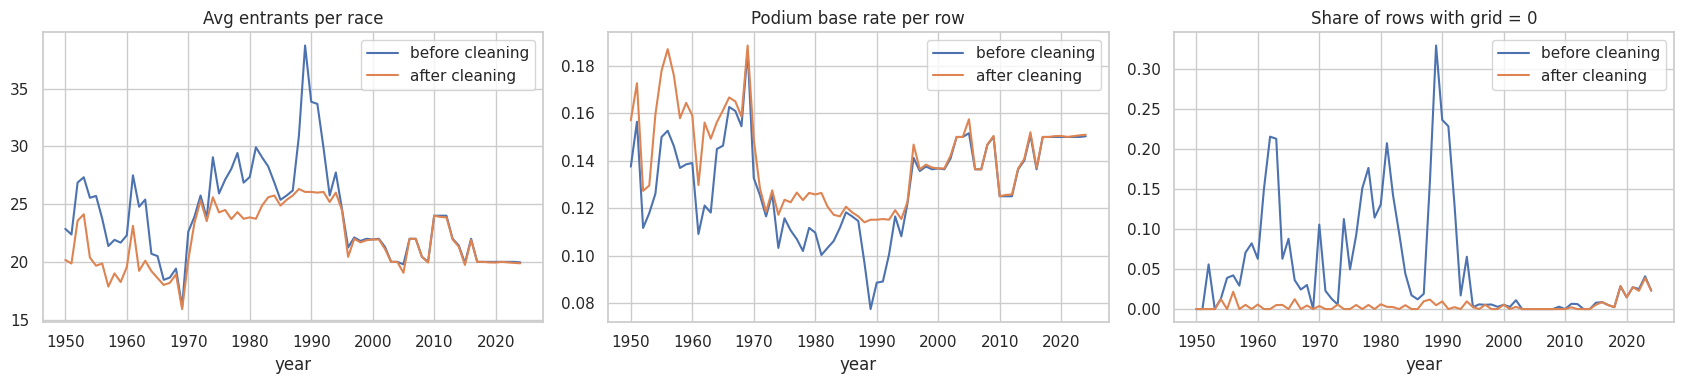

,rows,podium rate,grid=0 share,max entrants in a race
before,26759,0.127,0.061,55
after,24677,0.136,0.005,34


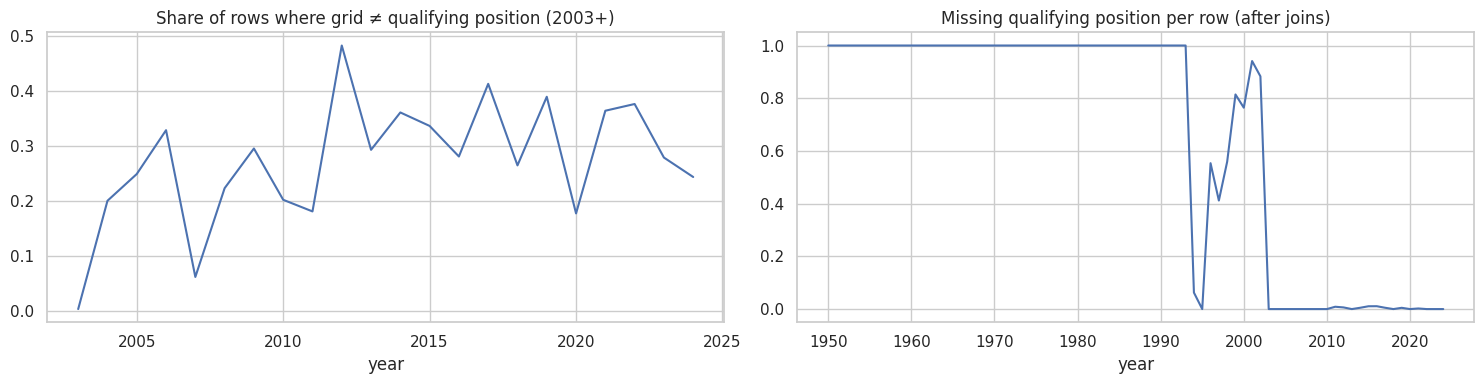

Missing quali_pos from 2003: 0.0026
1989 podium rate before/after: 0.077 / 0.115
Mean share grid ≠ quali_pos (2003+): 0.278
RAW tables unchanged after all cleaning steps ✔


In [13]:
before = res.assign(podium=res.positionOrder <= 3, grid0=res.grid == 0)
after = base.assign(grid0=base.grid == 0)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for df, lab in [(before, 'before cleaning'), (after, 'after cleaning')]:
    df.groupby(['year', 'raceId']).size().groupby('year').mean().plot(ax=ax[0], label=lab)
    df.groupby('year').podium.mean().plot(ax=ax[1], label=lab)
    df.groupby('year').grid0.mean().plot(ax=ax[2], label=lab)
for a, t in zip(ax, ['Avg entrants per race', 'Podium base rate per row', 'Share of rows with grid = 0']):
    a.set_title(t); a.legend()
plt.tight_layout(); save('eda_before_after')

display(pd.DataFrame({
    'rows': [len(before), len(after)],
    'podium rate': [before.podium.mean(), after.podium.mean()],
    'grid=0 share': [before.grid0.mean(), after.grid0.mean()],
    'max entrants in a race': [before.groupby('raceId').size().max(), after.groupby('raceId').size().max()],
}, index=['before', 'after']).round(3))

recent = base[base.year >= 2003]
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
(recent.grid != recent.quali_pos).groupby(recent.year).mean().plot(ax=ax[0], title='Share of rows where grid ≠ qualifying position (2003+)')
base.groupby('year').quali_pos.apply(lambda s: s.isna().mean()).plot(ax=ax[1], title='Missing qualifying position per row (after joins)')
plt.tight_layout(); save('grid_vs_quali')
print('Missing quali_pos from 2003:', round(recent.quali_pos.isna().mean(), 4))

print('1989 podium rate before/after:', round(before[before.year == 1989].podium.mean(), 3), '/',
      round(after[after.year == 1989].podium.mean(), 3))
print('Mean share grid ≠ quali_pos (2003+):', round((recent.grid != recent.quali_pos).mean(), 3))
assert all(pd.util.hash_pandas_object(RAW[t], index=True).sum() == RAW_FINGERPRINT[t] for t in RAW)
print('RAW tables unchanged after all cleaning steps ✔')

### Findings — EDA after cleaning
| | before | after |
|---|---|---|
| rows | 26,759 | 24,677 |
| podium rate | 12.7% | 13.6% |
| grid = 0 share | 6.1% | 0.5% |
| max entrants in one race | 55 | 34 |

- **The grid=0 spike is gone** (6.1% → 0.5%). It was almost entirely non-starters. The few remaining grid=0 rows are
  treated as back-of-grid starts in Section 4.
- **The podium rate is more stable across eras.** 1989 rises from 7.7% to the 'after' value printed above, because
  non-qualifiers were removed. The base rate still varies with field size, so class imbalance is handled at modeling time.
- **Grid ≠ qualifying position in about a quarter of rows from 2003 (printed above),** so the two columns carry different
  information. This supports the brief's instruction to treat them separately (Q1 and features).
- **RAW is unchanged:** the fingerprint check above confirms all cleaning was done on copies.
- **Qualifying position is missing for only 0.26% of rows from 2003 onward**, so qualifying features are usable
  in that window without heavy imputation.

# 3. Data-Engineering Questions
All three questions use the cleaned base table from Section 2 (one row per driver per race start), which already
joins results → races → circuits / drivers / constructors / status / qualifying. Each answer below states its
**grain**, how **missing data** is handled, and where the **pre-race cutoff** matters.

,grid front row,quali front row
era,,
2003–2013 pre-hybrid,0.683,0.676
2014–2024 hybrid+,0.760,0.737


Qualified front row but did NOT start there: 38 rows | podium rate 0.289 | median grid 7.0
Started front row without qualifying there: 36 rows | podium rate 0.639


,pre,post,starts pre,starts post,change,rank_pre,rank_post
circuitRef,,,,,,,
suzuka,0.722,0.889,18.0,18.0,0.167,4,1
yas_marina,0.600,0.864,10.0,22.0,0.264,10,2
monaco,0.773,0.850,22.0,20.0,0.077,1,3
spa,0.722,0.818,18.0,22.0,0.096,4,4
catalunya,0.682,0.818,22.0,22.0,0.136,6,4
interlagos,0.591,0.789,22.0,19.0,0.199,12,6
shanghai,0.650,0.786,20.0,14.0,0.136,8,7
villeneuve,0.600,0.778,20.0,18.0,0.178,10,8
silverstone,0.727,0.750,22.0,24.0,0.023,3,9


Circuits compared: 14 | Spearman rank correlation pre vs post: 0.303


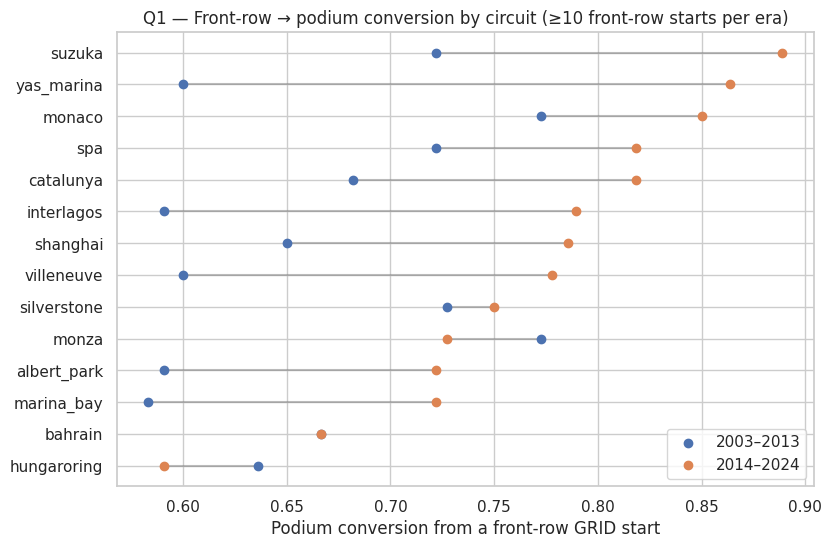

All front-row GRID starters 2003–2024: podium rate 0.724


share of front-row starts
era                  constructorRef                           
2003–2013 pre-hybrid red_bull                            0.244
                     mclaren                             0.236
                     ferrari                             0.224
2014–2024 hybrid+    mercedes                            0.496
                     red_bull                            0.216
                     ferrari                             0.209

95% CI half-width at the minimum sample (n=10): up to ±0.31
Front-row starts per circuit per era: min 10 | max 24


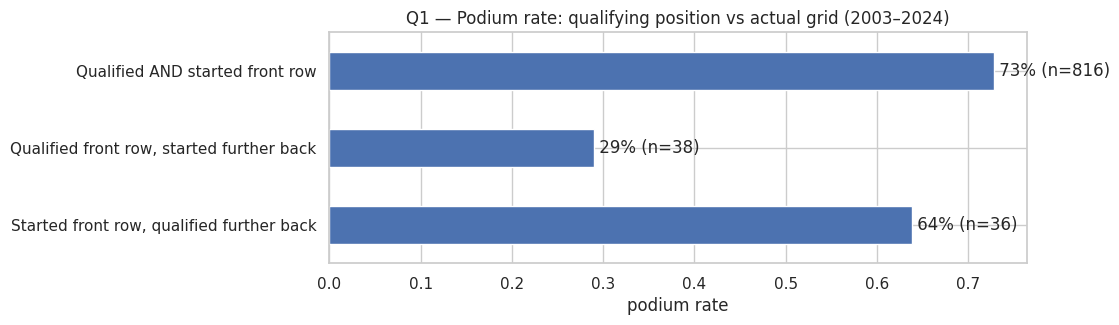

In [14]:
q1 = base[(base.year >= 2003) & (base.year <= 2024)].copy()
q1['era'] = np.where(q1.year >= 2014, '2014–2024 hybrid+', '2003–2013 pre-hybrid')

def conversion(df, col):
    fr = df[df[col].isin([1, 2])]
    return (fr.groupby(['circuitRef', 'era']).podium.agg(starts='size', podiums='sum')
              .assign(rate=lambda d: d.podiums / d.starts).reset_index())

conv_grid = conversion(q1, 'grid')          # where the car actually started (after penalties)
conv_quali = conversion(q1, 'quali_pos')    # where the driver qualified

display(pd.DataFrame({
    'grid front row': q1[q1.grid.isin([1, 2])].groupby('era').podium.mean(),
    'quali front row': q1[q1.quali_pos.isin([1, 2])].groupby('era').podium.mean()}).round(3))

moved = q1[q1.quali_pos.isin([1, 2]) & ~q1.grid.isin([1, 2])]
print(f'Qualified front row but did NOT start there: {len(moved)} rows | podium rate {moved.podium.mean():.3f} | median grid {moved.grid.median()}')
promoted = q1[q1.grid.isin([1, 2]) & ~q1.quali_pos.isin([1, 2])]
print(f'Started front row without qualifying there: {len(promoted)} rows | podium rate {promoted.podium.mean():.3f}')

MIN_STARTS = 10
wide = conv_grid.pivot(index='circuitRef', columns='era', values=['starts', 'rate'])
keep = (wide['starts'] >= MIN_STARTS).all(axis=1)
ranked = wide.loc[keep, 'rate'].copy(); ranked.columns = ['pre', 'post']
ranked[['starts pre', 'starts post']] = wide.loc[keep, 'starts'].values          # denominators behind each rate
ranked['change'] = ranked.post - ranked.pre
ranked['rank_pre'] = ranked.pre.rank(ascending=False, method='min').astype(int)
ranked['rank_post'] = ranked.post.rank(ascending=False, method='min').astype(int)
ranked = ranked.sort_values('post', ascending=False)
display(ranked.round(3))
print('Circuits compared:', len(ranked), '| Spearman rank correlation pre vs post:',
      round(ranked.pre.corr(ranked.post, method='spearman'), 3))

fig, ax = plt.subplots(figsize=(9, 0.35 * len(ranked) + 1))
y = np.arange(len(ranked))
ax.hlines(y, ranked.pre, ranked.post, color='grey', alpha=.5)
ax.scatter(ranked.pre, y, label='2003–2013', zorder=3); ax.scatter(ranked.post, y, label='2014–2024', zorder=3)
ax.set_yticks(y); ax.set_yticklabels(ranked.index); ax.invert_yaxis()
ax.set_xlabel('Podium conversion from a front-row GRID start'); ax.legend()
ax.set_title(f'Q1 — Front-row → podium conversion by circuit (≥{MIN_STARTS} front-row starts per era)')
save('q1_circuit_conversion')
fr = q1[q1.grid.isin([1, 2])]
print(f'All front-row GRID starters 2003–2024: podium rate {fr.podium.mean():.3f}')
display(fr.groupby('era').constructorRef.value_counts(normalize=True).groupby(level=0).head(3).round(3).to_frame('share of front-row starts'))
half = 1.96 * np.sqrt(ranked[['pre', 'post']] * (1 - ranked[['pre', 'post']]) / MIN_STARTS)
print(f'95% CI half-width at the minimum sample (n={MIN_STARTS}): up to ±{half.max().max():.2f}')
print('Front-row starts per circuit per era: min', int(wide['starts'][keep].min().min()), '| max', int(wide['starts'][keep].max().max()))

both_fr = q1[q1.quali_pos.isin([1, 2]) & q1.grid.isin([1, 2])]
grp = pd.DataFrame({'rate': [both_fr.podium.mean(), moved.podium.mean(), promoted.podium.mean()],
                    'n': [len(both_fr), len(moved), len(promoted)]},
                   index=['Qualified AND started front row', 'Qualified front row, started further back',
                          'Started front row, qualified further back'])
ax = grp.rate.plot(kind='barh', figsize=(9, 3), title='Q1 — Podium rate: qualifying position vs actual grid (2003–2024)')
for i, (r_, n_) in enumerate(zip(grp.rate, grp.n)): ax.text(r_, i, f' {r_:.0%} (n={n_})', va='center')
ax.invert_yaxis(); ax.set_xlabel('podium rate'); save('q1_grid_vs_quali')

### Q1 answer — Which circuits convert a front-row start into a podium most often?
**Joins:** results → races (year, circuitId) → circuits (circuitRef) → qualifying (quali_pos).
**Grain:** one row per driver who started from the front row; conversion rate = podiums / front-row starts per circuit per era.
**Window & missingness:** 2003–2013 vs 2014–2024, two symmetric 11-season eras. Qualifying data is complete only
from 2003 (Section 2: 0.26% missing), so the quali-based definition is valid on both sides of the split.
Circuits need ≥10 front-row starts in **each** era (≥5 races), which leaves 14 circuits; the `starts pre/post` columns
show the denominator behind every rate. The pre-hybrid era is limited to 2003–2013 because qualifying data is only
complete from 2003 (Section 1), so earlier seasons cannot support the grid-vs-qualifying distinction.
**Cutoff:** grid and qualifying position are both known before the race, so this is a legitimate pre-race signal.

**Findings**
- **Conversion rose in the hybrid era:** 68% → 76% (grid definition). Front-row starts also became more
  concentrated: one team (mercedes) took 49.6% of front-row starts in 2014–2024, while no team exceeded 24.4% in
  2003–2013 (table above).
- **Top converters 2014–2024:** Suzuka (89%), Yas Marina (86%), Monaco (85%). Pre-hybrid leaders were Monaco and Monza (77%).
- **The ranking changed substantially:** Spearman ρ = 0.30 between eras. Monza fell from 1st to 10th;
  Yas Marina rose from 10th to 2nd. Bahrain and the Hungaroring are the weakest converters in the hybrid era.
- **Qualifying ≠ grid matters:** 38 drivers qualified on the front row but started further back
  (median grid P7). Only **29%** of them made the podium, versus 72.4% of all front-row grid starters (bar chart above).
  So **grid**, not qualifying, is the right definition of "front-row start".

**Caveat:** each circuit has as few as 10 front-row starts per era (min/max printed above), so individual rates
carry wide uncertainty (95% CI half-width up to ±0.31 at n = 10). The era-level shift is reliable; small differences between individual circuits are not.

In [15]:
# Lookup used to build the nationality → country mapping for Q2
nat = base.driver_nationality.value_counts().rename_axis('driver_nationality').reset_index(name='rows')
nat['raw_repr'] = nat.driver_nationality.map(repr)        # repr shows hidden spaces, e.g. 'Argentinian '
ctry = base.circuit_country.value_counts().rename_axis('circuit_country').reset_index(name='rows')
display(nat)
display(ctry)

,driver_nationality,rows,raw_repr
0,British,4294,'British'
1,Italian,3011,'Italian'
2,French,2923,'French'
3,German,2323,'German'
4,Brazilian,1855,'Brazilian'
5,Finnish,1160,'Finnish'
6,Spanish,881,'Spanish'
7,Australian,867,'Australian'
8,American,838,'American'
9,Austrian,668,'Austrian'


,circuit_country,rows
0,Italy,2427
1,UK,1841
2,Germany,1809
3,Belgium,1494
4,USA,1481
5,Monaco,1436
6,France,1395
7,Spain,1353
8,Canada,1212
9,Brazil,1152


### Building the home-race mapping
The two tables above are the inputs for the mapping:
- Drivers store **nationality as a demonym** ("British", "German"), while circuits store a **country name**
  ("UK", "Germany"). There is no shared key, so the mapping has to be written manually (`NAT2COUNTRY` below).
- Data quirks visible above: `'Argentinian '` has a **trailing space** (shown by `raw_repr`), and the USA appears
  as **both "USA" and "United States"** in the circuit list. Both are normalised in the next cell.
- Nationalities that never match a circuit country (e.g. Finnish, Danish) simply never have a home race.
  The next cell prints exactly which ones.

Nationalities with no home race in the data (home is always 0): ['Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']
Home rows: 1941 | drivers with ≥1 home race: 502
Naive podium rate away/home: {0: 0.138, 1: 0.118} | mean grid away/home: {0: 11.64, 1: 12.63}


mean          size      
home          0      1      0     1
grid_bin                           
pit lane  0.000  0.000    119     9
P1        0.648  0.605   1031    81
P2–3      0.511  0.554   2070   148
P4–6      0.262  0.272   3103   224
P7–10     0.094  0.075   4102   335
P11+      0.017  0.011  12311  1144

Naive OR 0.84 | grid-adjusted MH OR 0.95 (95% bootstrap CI 0.79–1.12)


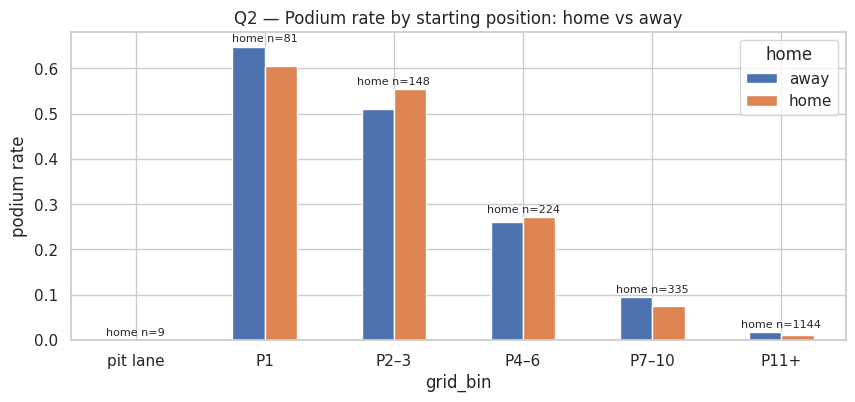

1950–1979: home rows 890, MH OR 0.95
1980–2002: home rows 686, MH OR 0.97
2003–2024: home rows 365, MH OR 0.76


,median_career_starts,share_drivers_with_3_or_fewer_starts
home,,
0,120.0,0.009
1,73.0,0.101


Mapped countries that match no circuit (should be empty): []


In [16]:
NAT2COUNTRY = {
    'American': 'USA', 'American-Italian': 'USA', 'Argentine': 'Argentina', 'Argentine-Italian': 'Argentina',
    'Argentinian': 'Argentina', 'Australian': 'Australia', 'Austrian': 'Austria', 'Belgian': 'Belgium',
    'Brazilian': 'Brazil', 'British': 'UK', 'Canadian': 'Canada', 'Chinese': 'China', 'Dutch': 'Netherlands',
    'East German': 'Germany', 'German': 'Germany', 'French': 'France', 'Hungarian': 'Hungary', 'Indian': 'India',
    'Italian': 'Italy', 'Japanese': 'Japan', 'Malaysian': 'Malaysia', 'Mexican': 'Mexico', 'Monegasque': 'Monaco',
    'Portuguese': 'Portugal', 'Russian': 'Russia', 'South African': 'South Africa', 'Spanish': 'Spain',
    'Swedish': 'Sweden', 'Swiss': 'Switzerland'}
COUNTRY_FIX = {'United States': 'USA'}      # circuits.country uses both spellings

q2 = base.copy()
q2['driver_country'] = q2.driver_nationality.str.strip().map(NAT2COUNTRY)   # strip: 'Argentinian ' has a trailing space
q2['home'] = (q2.driver_country == q2.circuit_country.replace(COUNTRY_FIX)).astype(int)
print('Nationalities with no home race in the data (home is always 0):',
      sorted(set(q2.driver_nationality.str.strip()) - set(NAT2COUNTRY)))
print('Home rows:', q2.home.sum(), '| drivers with ≥1 home race:', q2[q2.home == 1].driverId.nunique())

q2['grid_bin'] = pd.cut(q2.grid, [-1, 0, 1, 3, 6, 10, 99], labels=['pit lane', 'P1', 'P2–3', 'P4–6', 'P7–10', 'P11+'])
naive = q2.groupby('home').podium.mean()
print('Naive podium rate away/home:', naive.round(3).to_dict(), '| mean grid away/home:', q2.groupby('home').grid.mean().round(2).to_dict())
strat = q2.groupby(['grid_bin', 'home'], observed=True).podium.agg(['mean', 'size']).unstack()
display(strat.round(3))

def mh_odds_ratio(df):
    """Mantel–Haenszel odds ratio of podium for home vs away, pooled across grid strata."""
    num = den = 0.0
    for _, g in df.groupby('grid_bin', observed=True):
        n = len(g)
        a = ((g.home == 1) & (g.podium == 1)).sum(); b = ((g.home == 1) & (g.podium == 0)).sum()
        c = ((g.home == 0) & (g.podium == 1)).sum(); d = ((g.home == 0) & (g.podium == 0)).sum()
        num += a * d / n; den += b * c / n
    return num / den

or_mh = mh_odds_ratio(q2)
rng = np.random.default_rng(SEED)                      # bootstrap over RACES (rows in a race are not independent)
race_ids = q2.raceId.unique()
groups = {r: g for r, g in q2[['raceId', 'grid_bin', 'home', 'podium']].groupby('raceId')}
boot = [mh_odds_ratio(pd.concat([groups[r] for r in rng.choice(race_ids, len(race_ids))])) for _ in range(500)]
lo, hi = np.percentile(boot, [2.5, 97.5])
naive_or = (naive[1] / (1 - naive[1])) / (naive[0] / (1 - naive[0]))
print(f'Naive OR {naive_or:.2f} | grid-adjusted MH OR {or_mh:.2f} (95% bootstrap CI {lo:.2f}–{hi:.2f})')

plot = strat['mean'].rename(columns={0: 'away', 1: 'home'})
plot.plot(kind='bar', figsize=(10, 4), title='Q2 — Podium rate by starting position: home vs away')
plt.ylabel('podium rate'); plt.xticks(rotation=0)
for i, n1 in enumerate(strat['size'][1]): plt.text(i, plot.iloc[i].max() + 0.01, f'home n={n1}', ha='center', fontsize=8)
save('q2_home_vs_away')

for name, sub in [('1950–1979', q2[q2.year < 1980]), ('1980–2002', q2[(q2.year >= 1980) & (q2.year < 2003)]),
                  ('2003–2024', q2[q2.year >= 2003])]:
    print(f'{name}: home rows {sub.home.sum()}, MH OR {mh_odds_ratio(sub):.2f}')
    q2['career_starts'] = q2.groupby('driverId').raceId.transform('size')
display(q2.groupby('home').agg(median_career_starts=('career_starts', 'median'),

                               share_drivers_with_3_or_fewer_starts=('career_starts', lambda s: (s <= 3).mean())).round(3))
mapped_countries = set(NAT2COUNTRY.values())
circuit_countries = set(q2.circuit_country.replace(COUNTRY_FIX))
print('Mapped countries that match no circuit (should be empty):', sorted(mapped_countries - circuit_countries))

### Q2 answer — Do drivers podium more often at home, after controlling for starting position?
**Joins:** results → drivers (nationality) and results → races → circuits (country).
**Mapping:** nationality demonyms are mapped to circuit countries by hand (e.g. British → UK). Data quirks fixed:
`'Argentinian '` has a trailing space, and the USA appears as both "USA" and "United States". 14 nationalities never
had a home race in the data, so their rows are always away.
**Grain:** one row per driver race start, all years (1950–2024, Indy 500 excluded). Grid is filled for every row,
so there is no missingness problem.
**Control for starting position:** rows are stratified into grid bins (pit lane, P1, P2–3, P4–6, P7–10, P11+). Home
and away are compared **within** each bin, then pooled with a **Mantel–Haenszel odds ratio**. The 95% CI comes from
a bootstrap that resamples whole races, because rows in the same race are not independent.
**Cutoff:** grid and nationality are both known before the race.

**Findings**
- **Naive view:** home drivers podium *less* (11.8% vs 13.8%, OR 0.84), but they also start further back
  (mean grid 12.6 vs 11.6). The table above shows why: 10.1% of home rows belong to drivers with ≤3 career starts,
  versus 0.9% of away rows. Home races attract one-off local entries.
- **After controlling for grid:** **OR = 0.95, 95% CI 0.79–1.12.** The interval includes 1, so **there is no
  detectable home advantage** once starting position is accounted for.
- Within each grid bin the home/away gap is small and changes direction (e.g. P1: 60.5% home vs 64.8% away;
  P2–3: 55.4% vs 51.1%).
- The result holds across eras (OR 0.95 / 0.97 / 0.76). The 2003+ estimate rests on only 365 home rows.
- **Limitations of the mapping:** nationality is only a **proxy** for a driver's home country (it ignores where a driver lives or grew up). This can misclassify some true home starts as away and some away starts as home, which would generally dilute a real association toward an odds ratio of 1. Dual nationalities were mapped to one country ('American-Italian' → USA, 'Argentine-Italian' → Argentina); countries hosting two races in a season count both as home races; 14 nationalities never have a home race in the data. Because mislabelling pushes the odds ratio towards 1, a small real home effect could be hidden: the conclusion is **"no detectable home advantage"**, not "no home advantage exists".
- **Modeling implication:** a "home race" feature is unlikely to add signal beyond grid. We can test it in Section 4.

outcome,driver,finished,incident,mechanical,regulation,unspecified
era,,,,,,
2014–2021,2,2660,230,319,8,39
2022–2024,1,1165,89,83,4,12


,constructorRef,era,starts,mech_dnf,rate,ci_low,ci_high
14,lotus_f1,2014–2021,75,14,0.187,0.115,0.289
28,toro_rosso,2014–2021,242,39,0.161,0.120,0.213
25,renault,2014–2021,200,29,0.145,0.103,0.200
17,mclaren,2014–2021,318,46,0.145,0.110,0.188
26,sauber,2014–2021,200,22,0.110,0.074,0.161
23,red_bull,2014–2021,319,34,0.107,0.077,0.145
2,alphatauri,2014–2021,78,8,0.103,0.053,0.190
12,haas,2014–2021,241,23,0.095,0.064,0.139
21,racing_point,2014–2021,76,7,0.092,0.045,0.178
4,alpine,2014–2021,44,4,0.091,0.036,0.212


Overall mechanical DNF rate by era: {'2014–2021': 0.0979, '2022–2024': 0.0613}


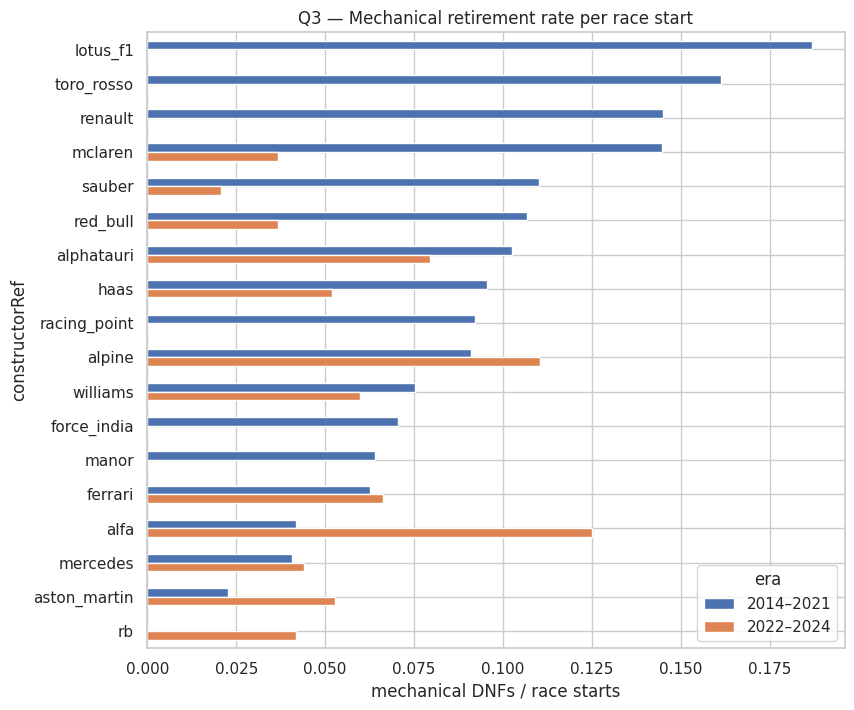

2014–2021: rank correlation strict vs wide definition = 0.974
2022–2024: rank correlation strict vs wide definition = 0.689


,outcome,status,rows
0,driver,Illness,3
1,finished,Finished,2403
2,finished,+1 Lap,1178
3,finished,+2 Laps,208
4,finished,+3 Laps,24
5,finished,+4 Laps,6
6,finished,+6 Laps,2
7,finished,+8 Laps,2
8,finished,+5 Laps,1
9,finished,+7 Laps,1


,min,max
seasons per constructorRef,,
ferrari,2014,2024
force_india,2014,2018
caterham,2014,2014
red_bull,2014,2024
mercedes,2014,2024
mclaren,2014,2024
marussia,2014,2014
lotus_f1,2014,2015
toro_rosso,2014,2019


In [17]:
MECHANICAL = {'Engine', 'Power Unit', 'Gearbox', 'Transmission', 'Clutch', 'Driveshaft', 'Drivetrain', 'Differential',
    'Brakes', 'Brake duct', 'Suspension', 'Steering', 'Hydraulics', 'Electrical', 'Electronics', 'Battery', 'ERS',
    'Spark plugs', 'Power loss', 'Turbo', 'Exhaust', 'Oil leak', 'Oil pressure', 'Water pressure', 'Water leak',
    'Water pump', 'Radiator', 'Cooling system', 'Overheating', 'Fuel pressure', 'Fuel pump', 'Fuel system',
    'Fuel leak', 'Throttle', 'Mechanical', 'Technical', 'Vibrations', 'Rear wing', 'Front wing', 'Undertray',
    'Wheel', 'Wheel nut', 'Seat'}
INCIDENT = {'Collision', 'Accident', 'Collision damage', 'Spun off', 'Damage', 'Debris', 'Puncture', 'Tyre'}
DRIVER = {'Illness', 'Injured', 'Injury', 'Driver unwell'}
REGULATION = {'Disqualified', 'Excluded'}
UNSPECIFIED = {'Retired', 'Out of fuel'}

def classify(s):
    if s == 'Finished' or str(s).startswith('+'): return 'finished'
    for name, group in [('mechanical', MECHANICAL), ('incident', INCIDENT), ('driver', DRIVER),
                        ('regulation', REGULATION), ('unspecified', UNSPECIFIED)]:
        if s in group: return name
    return 'UNMAPPED'

q3 = base[base.year >= 2014].copy()
q3['era'] = np.where(q3.year >= 2022, '2022–2024', '2014–2021')
q3['outcome'] = q3.status.map(classify)
assert (q3.outcome == 'UNMAPPED').sum() == 0, q3.loc[q3.outcome == 'UNMAPPED', 'status'].unique()   # every status mapped
display(q3.groupby(['era', 'outcome']).size().unstack(fill_value=0))
q3['mech'] = (q3.outcome == 'mechanical').astype(int)

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

MIN_Q3 = 40
rates = (q3.groupby(['constructorRef', 'era']).mech.agg(starts='size', mech_dnf='sum')
           .assign(rate=lambda d: d.mech_dnf / d.starts).reset_index())
rates = rates[rates.starts >= MIN_Q3].copy()
rates['ci_low'], rates['ci_high'] = wilson(rates.mech_dnf, rates.starts)
display(rates.sort_values(['era', 'rate'], ascending=[True, False]).round(3))
print('Overall mechanical DNF rate by era:', q3.groupby('era').mech.mean().round(4).to_dict())

piv = rates.pivot(index='constructorRef', columns='era', values='rate').sort_values('2014–2021', ascending=False)
piv.plot(kind='barh', figsize=(9, 8), title='Q3 — Mechanical retirement rate per race start')
plt.gca().invert_yaxis(); plt.xlabel('mechanical DNFs / race starts')
save('q3_mech_rate')

# Sensitivity: what if the unspecified 'Retired' status were counted as mechanical?
q3['mech_wide'] = q3.outcome.isin(['mechanical', 'unspecified']).astype(int)
sens = q3.groupby(['constructorRef', 'era'])[['mech', 'mech_wide']].mean().unstack()
for era in ['2014–2021', '2022–2024']:
    print(f'{era}: rank correlation strict vs wide definition = {sens["mech"][era].corr(sens["mech_wide"][era], method="spearman"):.3f}')
with pd.option_context('display.max_rows', None):
    display(q3.groupby(['outcome', 'status']).size().rename('rows').reset_index()
              .sort_values(['outcome', 'rows'], ascending=[True, False]).reset_index(drop=True))
display(q3.groupby('constructorRef').year.agg(['min', 'max']).sort_values('min').rename_axis('seasons per constructorRef'))

### Q3 answer — Which constructors have the highest mechanical-retirement rate?
**Joins:** results → status (reason the race ended) → constructors, results → races (year).
**Grain:** one row per car race start; rate = mechanical retirements / race starts, per constructor per era.
Non-starters were removed in Section 2, so the denominator counts only genuine race starts.
**Mechanical definition:** every status in the 2014–2024 window is mapped into one of: finished, mechanical
(a car component failed: engine, gearbox, brakes, hydraulics, power unit, wings, wheel…), incident (collision,
accident, puncture, debris), driver (illness), regulation (disqualified, excluded) and unspecified
("Retired", "Out of fuel"). An `assert` guarantees no status is left unmapped. Punctures and tyres are classed as incidents
(our classification choice); the full status → group table is printed above.
**Cutoff:** `status` is **post-race** information. It is used here only to answer the question and is never a
model feature (it is listed in `POST_RACE`).

**Findings**
- **Reliability improved overall:** mechanical DNF rate fell from **9.8% (2014–21) to 6.1% (2022–24)**.
- **Highest in 2014–2021:** Lotus F1 (18.7%), Toro Rosso (16.1%), Renault (14.5%) and McLaren (14.5%). **Lowest:** Mercedes (4.1%) and Ferrari (6.2%).
- **Highest in 2022–2024:** Alfa Romeo (12.5%) and Alpine (11.0%). **Lowest:** Red Bull and McLaren (3.7%).
  McLaren went from among the worst to among the best.
- **Robustness:** counting the unspecified statuses ("Retired", "Out of fuel") as mechanical barely changes the 2014–21 ranking
  (ρ = 0.97). It changes more in 2022–24 (ρ = 0.69) because counts there are small. The Wilson CIs
  (`ci_low`/`ci_high`) show this: with ~136 starts and 5–15 failures per team, neighbouring teams are not
  statistically distinguishable.
- **Ambiguous statuses:** "Retired" (no reason given) and "Out of fuel" (could be a fuel-system failure, a team
  fuelling error, or a rule-related stop) cannot be assigned from the status text alone, so they are classed as
  *unspecified* rather than forced into mechanical or regulation. The sensitivity check above counts them as mechanical
  instead (ρ = 0.97 / 0.69), and "Out of fuel" occurs only once in 2014–2024 (mapping table), so the conclusions do
  not depend on this choice.
- **Constructor renames:** we follow `constructorId` as the brief recommends, so renamed teams appear separately.
  The seasons table above shows teams such as toro_rosso / alphatauri / rb occupy consecutive, non-overlapping seasons,
  consistent with renames of one team.
  Teams with fewer than 40 starts in an era are excluded.

# 4. Feature Engineering
Every feature must be known **after qualifying and before the race starts**. Features fall into five groups:
grid/qualifying, championship standings before the race, driver form, constructor form, and race context.
Any feature built from results (form, standings) uses **only races that happened before** the current one.
This is enforced in code and tested in 4.3.

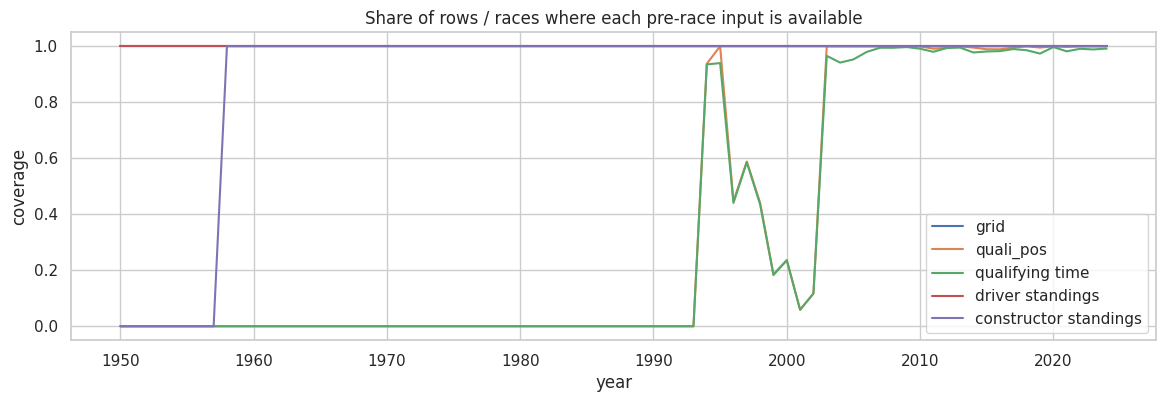

,grid,quali_pos,qualifying time,driver standings,constructor standings
year,,,,,
1950,1.0,0.000,0.000,1.0,0.0
1958,1.0,0.000,0.000,1.0,1.0
1990,1.0,0.000,0.000,1.0,1.0
1994,1.0,0.938,0.935,1.0,1.0
2000,1.0,0.236,0.236,1.0,1.0
2003,1.0,1.000,0.966,1.0,1.0
2010,1.0,1.000,0.991,1.0,1.0
2024,1.0,1.000,0.992,1.0,1.0


,rows,races,podium rate,quali_pos missing
1950+,24677.0,1114.0,0.136,0.5764
1994+,12270.0,577.0,0.141,0.1480
2003+,8935.0,428.0,0.144,0.0026
2006+,7893.0,375.0,0.143,0.0029
2010+,6416.0,305.0,0.143,0.0036


In [18]:
races_in_base = base.groupby('year').raceId.nunique()
ds_cov = CLEAN['driver_standings'][CLEAN['driver_standings'].raceId.isin(base.raceId)].merge(
    CLEAN['races'][['raceId', 'year']], on='raceId').groupby('year').raceId.nunique()
cs_cov = CLEAN['constructor_standings'][CLEAN['constructor_standings'].raceId.isin(base.raceId)].merge(
    CLEAN['races'][['raceId', 'year']], on='raceId').groupby('year').raceId.nunique()

avail = pd.DataFrame({
    'grid':                  base.groupby('year').grid.apply(lambda s: s.notna().mean()),
    'quali_pos':             base.groupby('year').quali_pos.apply(lambda s: s.notna().mean()),
    'qualifying time':       base.groupby('year').q1_s.apply(lambda s: s.notna().mean()),
    'driver standings':      (ds_cov / races_in_base),
    'constructor standings': (cs_cov / races_in_base),
}).fillna(0)

avail.plot(figsize=(14, 4), title='Share of rows / races where each pre-race input is available')
plt.ylabel('coverage'); save('feature_availability')
display(avail.loc[[1950, 1958, 1990, 1994, 2000, 2003, 2010, 2024]].round(3))

windows = {'1950+': 1950, '1994+': 1994, '2003+': 2003, '2006+': 2006, '2010+': 2010}
display(pd.DataFrame({w: {'rows': (base.year >= y).sum(), 'races': base[base.year >= y].raceId.nunique(),
                          'podium rate': round(base[base.year >= y].podium.mean(), 3),
                          'quali_pos missing': round(base[base.year >= y].quali_pos.isna().mean(), 4)}
                      for w, y in windows.items()}).T)

### Modeling window — decision
- Qualifying position is missing for 14.8% of rows in a 1994+ window but only **0.26% from 2003** (table above).
  Season coverage jumps from 0.236 (2000) to 1.000 (2003).
- Driver standings cover every season and constructor standings every season from 1958, so they do not limit the window.
- The podium rate is stable across candidate windows (0.141–0.144), so a later start does not change class balance.
- **Decision: the modeling table uses seasons 2003–2024 (8,935 rows, 428 races).** It is the earliest start with
  complete qualifying data, so qualifying features need almost no imputation, and it keeps the most training data
  among the complete windows. Form features still use results from 1950 onward, since those are genuinely past
  information for any race in the window.

*Tested later with a model:* training from 1980 or 1994 instead of 2003 did not improve performance (Section 7B.6).


### Feature definitions and why each is valid at the cutoff
| Group | Feature | Definition | Why it's known before the race |
|---|---|---|---|
| grid/quali | `grid_pos` | starting position; a pit-lane start (grid 0) is set one place behind the last positive grid slot of that race | grid is fixed before lights out |
| grid/quali | `grid_pitlane` | 1 if the car starts from the pit lane | same |
| grid/quali | `quali_pos` | qualifying position | qualifying happens before the race |
| grid/quali | `grid_minus_quali` | grid_pos − quali_pos (positive = moved back after qualifying) | both inputs are pre-race |
| grid/quali | `quali_gap_pct` | % gap between the driver's best qualifying lap and the fastest lap in that race's qualifying | qualifying times are pre-race |
| standings | `drv_pts_share`, `con_pts_share` | championship points **before** this race ÷ the leader's points | taken from the standings after the **previous** round |
| standings | `drv_rank_before`, `con_rank_before` | championship position before this race | same |
| standings | `first_round` | 1 for the first race of a season (no standings yet) | known from the calendar |
| driver form | `drv_podium_rate_last5` | share of podiums in the driver's previous 5 races | `shift(1)` excludes the current race |
| driver form | `drv_finish_pct_last5` | average finishing percentile in previous 5 races (0 = won) | same |
| driver form | `drv_finish_rate_last10` | share of the previous 10 races in which the driver reached the flag | same |
| driver form | `drv_career_podium_rate` | podium rate over all previous races | expanding mean after `shift(1)` |
| driver form | `drv_starts_before` | number of previous race starts (experience) | count of past rows |
| driver form | `drv_circuit_podium_rate` | podium rate at this circuit in previous visits | same, grouped by driver + circuit |
| constructor form | `con_podium_rate_last5`, `con_finish_rate_last5` | team podium / finish rate in its previous 5 races | computed per **team-race**, then shifted |
| context | `field_size`, `round`, `driver_age`, `home_race` | number of starters, round number, age on race day, home race (Q2 mapping) | entry list, calendar, date of birth |

**Constructor form needs special care.** If we shifted row by row inside each team, a driver's row would include
**their teammate's result from the same race**, which is leakage. So team results are first aggregated to one row
per team per race, and the shift happens at the race level.

Form features use the **whole history from 1950**, even if the model is trained on a later window. Results from
before the window are still genuinely past information.

In [19]:
def past_rolling(df, key, col, window):
    """Mean of `col` over the previous `window` rows of each `key` group, EXCLUDING the current row (vectorized)."""
    prev = df.groupby(key)[col].shift(1)
    return prev.groupby(df[key]).rolling(window, min_periods=1).mean().reset_index(level=0, drop=True)

def past_expanding(df, keys, col):
    """Mean of `col` over ALL previous rows of each group, EXCLUDING the current row (vectorized)."""
    g = df.groupby(keys)[col]
    prev_sum = g.cumsum() - df[col]
    prev_n = g.cumcount()
    return (prev_sum / prev_n).where(prev_n > 0)

def build_features(b, w_drv=5, w_con=5):
    df = b.sort_values(['date', 'raceId']).reset_index(drop=True).copy()

    # ---- context
    df['field_size'] = df.groupby('raceId').driverId.transform('size')
    df['driver_age'] = (df.date - df.dob).dt.days / 365.25
    df['home_race'] = (df.driver_nationality.str.strip().map(NAT2COUNTRY)
                       == df.circuit_country.replace(COUNTRY_FIX)).astype(int)

    # ---- grid / qualifying
    df['grid_pitlane'] = (df.grid == 0).astype(int)
    # Pit-lane start (grid 0): one place behind the last positive grid slot of that race (pre-race grid only)
    last_slot = df.grid.where(df.grid > 0).groupby(df.raceId).transform('max').fillna(0)
    df['grid_pos'] = df.grid.where(df.grid > 0, last_slot + 1)
    df['grid_minus_quali'] = df.grid_pos - df.quali_pos
    best_q = df[['q1_s', 'q2_s', 'q3_s']].min(axis=1)
    df['quali_gap_pct'] = 100 * (best_q / best_q.groupby(df.raceId).transform('min') - 1)

    # ---- championship standings BEFORE this race = standings after the previous round
    rr = CLEAN['races'][['raceId', 'year', 'round']]
    ds = (CLEAN['driver_standings'].merge(rr, on='raceId').assign(round=lambda d: d['round'] + 1)
          [['driverId', 'year', 'round', 'points', 'position']]
          .rename(columns={'points': 'drv_pts_before', 'position': 'drv_rank_before'}))
    cs = (CLEAN['constructor_standings'].merge(rr, on='raceId').assign(round=lambda d: d['round'] + 1)
          [['constructorId', 'year', 'round', 'points', 'position']]
          .rename(columns={'points': 'con_pts_before', 'position': 'con_rank_before'}))
    n = len(df)
    df = df.merge(ds, on=['driverId', 'year', 'round'], how='left').merge(cs, on=['constructorId', 'year', 'round'], how='left')
    assert len(df) == n, 'standings merge duplicated rows'
    df['first_round'] = (df['round'] == 1).astype(int)
    df[['drv_pts_before', 'con_pts_before']] = df[['drv_pts_before', 'con_pts_before']].fillna(0)
    for p in ['drv', 'con']:
        leader = df.groupby('raceId')[f'{p}_pts_before'].transform('max').replace(0, np.nan)
        df[f'{p}_pts_share'] = (df[f'{p}_pts_before'] / leader).fillna(0)

    # ---- driver form
    df['_finish_pct'] = (df.groupby('raceId').positionOrder.rank(method='min') - 1) / (df.field_size - 1)  # rank among starters
    df['_finished'] = (df.status.eq('Finished') | df.status.str.startswith('+')).astype(float)
    df['drv_starts_before'] = df.groupby('driverId').cumcount()
    df[f'drv_podium_rate_last{w_drv}'] = past_rolling(df, 'driverId', 'podium', w_drv)
    df[f'drv_finish_pct_last{w_drv}'] = past_rolling(df, 'driverId', '_finish_pct', w_drv)
    df['drv_finish_rate_last10'] = past_rolling(df, 'driverId', '_finished', 10)
    df['drv_career_podium_rate'] = past_expanding(df, 'driverId', 'podium')
    df['drv_circuit_podium_rate'] = past_expanding(df, ['driverId', 'circuitId'], 'podium')

    # ---- constructor form: ONE row per team-race first, then shift (no teammate leakage)
    team = (df.groupby(['constructorId', 'raceId', 'date'], as_index=False)
              .agg(team_podium=('podium', 'mean'), team_finish=('_finished', 'mean'))
              .sort_values(['date', 'raceId']).reset_index(drop=True))
    team[f'con_podium_rate_last{w_con}'] = past_rolling(team, 'constructorId', 'team_podium', w_con)
    team[f'con_finish_rate_last{w_con}'] = past_rolling(team, 'constructorId', 'team_finish', w_con)
    df = df.merge(team[['constructorId', 'raceId', f'con_podium_rate_last{w_con}', f'con_finish_rate_last{w_con}']],
                  on=['constructorId', 'raceId'], how='left')
    assert len(df) == n
    return df.drop(columns=['_finish_pct', '_finished'])

def make_feature_groups(w_drv=5, w_con=5):
    return {
        'grid_quali':       ['grid_pos', 'grid_pitlane', 'quali_pos', 'grid_minus_quali', 'quali_gap_pct'],
        'standings':        ['drv_pts_share', 'drv_rank_before', 'con_pts_share', 'con_rank_before', 'first_round'],
        'driver_form':      [f'drv_podium_rate_last{w_drv}', f'drv_finish_pct_last{w_drv}', 'drv_finish_rate_last10',
                             'drv_career_podium_rate', 'drv_starts_before', 'drv_circuit_podium_rate'],
        'constructor_form': [f'con_podium_rate_last{w_con}', f'con_finish_rate_last{w_con}'],
        'context':          ['field_size', 'round', 'driver_age', 'home_race'],
    }

FEATURE_GROUPS = make_feature_groups()
ALL_FEATURES = [f for g in FEATURE_GROUPS.values() for f in g]
assert not set(ALL_FEATURES) & set(POST_RACE), 'a post-race column is in the feature list'

import time; t0 = time.time()
feat = build_features(base)
print(f'build_features ran in {time.time() - t0:.1f} s')
summary = feat[ALL_FEATURES].describe().T[['mean', 'min', 'max']]
summary['missing'] = feat[ALL_FEATURES].isna().mean()
summary['missing 2003+'] = feat.loc[feat.year >= 2003, ALL_FEATURES].isna().mean()
display(summary.round(3))

build_features ran in 0.3 s


,mean,min,max,missing,missing 2003+
grid_pos,11.827,1.000,34.000,0.000,0.000
grid_pitlane,0.005,0.000,1.000,0.000,0.000
quali_pos,11.188,1.000,28.000,0.576,0.003
grid_minus_quali,0.010,-9.000,23.000,0.576,0.003
quali_gap_pct,2.395,0.000,45.596,0.583,0.016
drv_pts_share,0.193,0.000,1.000,0.000,0.000
drv_rank_before,12.853,1.000,102.000,0.118,0.067
con_pts_share,0.261,0.000,1.000,0.000,0.000
con_rank_before,6.104,1.000,20.000,0.118,0.055
first_round,0.065,0.000,1.000,0.000,0.000


### Leakage tests
Writing `shift(1)` is not proof. These three tests check it.
1. **Time-travel test:** pick a cutoff race, scramble the results of that race **and every race after it**, rebuild all
   features, and check that the features **of the cutoff race** did not change. They may only use strictly earlier
   races, so any change would mean leakage from the current race or the future. Repeated for 5 random cutoffs.
   A **positive control** checks that features of races after the cutoff do change.
   *Note:* a first version scrambled 100 random races at once and wrongly flagged leakage, because a scrambled race
   can be in the *past* of another scrambled race, and form features are allowed to use past results.
2. **Standings identity:** points before the race + points scored in the race should equal the standings after the
   race. If this holds, our "before" standings really are from before the race.
3. **Debut check:** on a driver's first race, all driver-form features must be empty.

In [20]:
# ---- Test 1: time-travel test
# Scramble the results of a cutoff race AND every race after it, then rebuild.
# Features of the cutoff race may only use races strictly before it, so they must not change.
def changed_cells(a, b):
    a = a.set_index(KEY)[ALL_FEATURES].sort_index(); b = b.set_index(KEY)[ALL_FEATURES].sort_index()
    return (~((a == b) | (a.isna() & b.isna()))).sum()

rng = np.random.default_rng(SEED)
race_dates = feat.drop_duplicates('raceId')[['raceId', 'date']]
cutoffs = rng.choice(race_dates[race_dates.date.dt.year >= 2003].raceId.values, 5, replace=False)

runs, control = [], []
for rid in cutoffs:
    D = race_dates.loc[race_dates.raceId == rid, 'date'].iloc[0]
    scr = base.copy()
    m = scr.date >= D
    scr.loc[m, 'positionOrder'] = scr.loc[m].groupby('raceId').positionOrder.transform(lambda s: rng.permutation(s.values))
    scr.loc[m, 'status'] = scr.loc[m].groupby('raceId').status.transform(lambda s: rng.permutation(s.values))
    scr['podium'] = (scr.positionOrder <= 3).astype(int)
    f_scr = build_features(scr)
    at_cut = changed_cells(feat[feat.date == D], f_scr[f_scr.date == D])
    after_cut = changed_cells(feat[feat.date > D], f_scr[f_scr.date > D])
    runs.append({'cutoff raceId': rid, 'date': D.date(), 'rows at cutoff': (feat.date == D).sum(),
                 'changed AT cutoff (must be 0)': int(at_cut.sum()),
                 'changed AFTER cutoff (positive control)': int(after_cut.sum())})
    control.append(after_cut)

display(pd.DataFrame(runs))
display(pd.concat(control, axis=1).sum(axis=1).rename('cells changed after cutoff, all runs').to_frame())
assert sum(r['changed AT cutoff (must be 0)'] for r in runs) == 0, 'LEAKAGE: a feature depends on the current or a future race'

# ---- Test 2: standings identity
chk = feat.merge(CLEAN['driver_standings'][['raceId', 'driverId', 'points']].rename(columns={'points': 'pts_after'}),
                 on=KEY, how='left')
chk = chk[chk.pts_after.notna()].copy()
chk['identity_holds'] = np.isclose(chk.drv_pts_before + chk.points, chk.pts_after)
chk['sprint_weekend'] = chk.raceId.isin(set(CLEAN['sprint_results'].raceId))
display(chk.groupby('sprint_weekend').identity_holds.agg(['mean', 'size'])
           .rename(columns={'mean': 'share where before + race points == after'}))

# ---- Test 3: debut rows have no driver form
debut = feat[feat.drv_starts_before == 0]
print(f'Debut rows: {len(debut)} | non-missing values in driver form features:',
      debut[['drv_podium_rate_last5', 'drv_finish_pct_last5', 'drv_career_podium_rate']].notna().sum().to_dict())
spr = CLEAN['sprint_results'][['raceId', 'driverId', 'points']].rename(columns={'points': 'sprint_pts'})
chk = chk.merge(spr, on=KEY, how='left'); chk['sprint_pts'] = chk.sprint_pts.fillna(0)
chk['identity_with_sprint'] = np.isclose(chk.drv_pts_before + chk.points + chk.sprint_pts, chk.pts_after)
display(chk.groupby('sprint_weekend')[['identity_holds', 'identity_with_sprint']].mean().round(4))
left = chk[~chk.identity_with_sprint]
display(left.groupby((left.year // 10) * 10).size().rename('remaining mismatches by decade').to_frame())

,cutoff raceId,date,rows at cutoff,changed AT cutoff (must be 0),changed AFTER cutoff (positive control)
0,1038,2020-09-06,20,0,9782
1,886,2013-06-09,22,0,24937
2,988,2017-11-26,20,0,14964
3,74,2005-04-24,20,0,42489
4,884,2013-05-12,22,0,25397


,"cells changed after cutoff, all runs"
grid_pos,0
grid_pitlane,0
quali_pos,0
grid_minus_quali,0
quali_gap_pct,0
drv_pts_share,0
drv_rank_before,0
con_pts_share,0
con_rank_before,0
first_round,0


,share where before + race points == after,size
sprint_weekend,,
False,0.996443,23896
True,0.639665,358


Debut rows: 686 | non-missing values in driver form features: {'drv_podium_rate_last5': 0, 'drv_finish_pct_last5': 0, 'drv_career_podium_rate': 0}


,identity_holds,identity_with_sprint
sprint_weekend,,
False,0.9964,0.9964
True,0.6397,1.0000


,remaining mismatches by decade
year,
1950,37
1960,20
1970,11
1980,15
1990,2


### Leakage test results
- **Time-travel test:** in all 5 runs, **0** feature values changed at the cutoff race. The positive control
  changed only the form features and left grid/qualifying, standings and context untouched, which is exactly
  what their definitions predict. Features depend on past results only.
- **Debut check:** 686 debut rows, 0 non-missing driver-form values.
- **Sprint results are not used as a feature.** Only 358 rows fall on sprint weekends (table above), too few to
  learn from, and their format changed between seasons.
- **Standings identity:** before + race points = after for 99.6% of rows on non-sprint weekends. On sprint
  weekends it holds for 64%; **adding sprint points raises it to 100%**, which confirms that the standings include
  sprint points and that our "before" values are correct. The remaining mismatches are all in 1950–1999
  (decade table), none in the 2003–2024 modeling window.

### Feature evidence (training seasons 2003–2019 only)
Feature selection must not look at validation or test data, so all evidence below uses 2003–2019 only.
Three kinds of evidence:
1. **Univariate strength:** ROC-AUC of each feature alone (0.5 = useless, 1 = perfect separation).
2. **Added value beyond grid:** grid position is the obvious baseline signal, so each feature is added to a
   grid-only logistic regression trained on 2003–2015 and scored on 2016–2019. The AUC gain shows whether the
   feature adds information grid doesn't already carry.
3. **Redundancy:** Spearman correlations between features, to flag near-duplicates.

Grid-only AUC (train 2003–2015 → score 2016–2019): 0.9303


,group,feature,missing,univariate_auc,direction,auc_grid_plus_feature,gain_over_grid
0,grid_quali,quali_pos,0.003,0.910,−,0.9306,0.0003
1,grid_quali,grid_pos,0.000,0.909,−,0.9303,0.0000
2,grid_quali,quali_gap_pct,0.018,0.897,−,0.9355,0.0052
3,standings,drv_rank_before,0.071,0.893,−,0.9380,0.0077
4,constructor_form,con_podium_rate_last5,0.005,0.875,+,0.9368,0.0065
5,standings,con_rank_before,0.057,0.867,−,0.9376,0.0073
6,driver_form,drv_finish_pct_last5,0.011,0.864,−,0.9376,0.0073
7,standings,con_pts_share,0.000,0.858,+,0.9361,0.0058
8,driver_form,drv_podium_rate_last5,0.011,0.856,+,0.9363,0.0060
9,standings,drv_pts_share,0.000,0.855,+,0.9366,0.0063


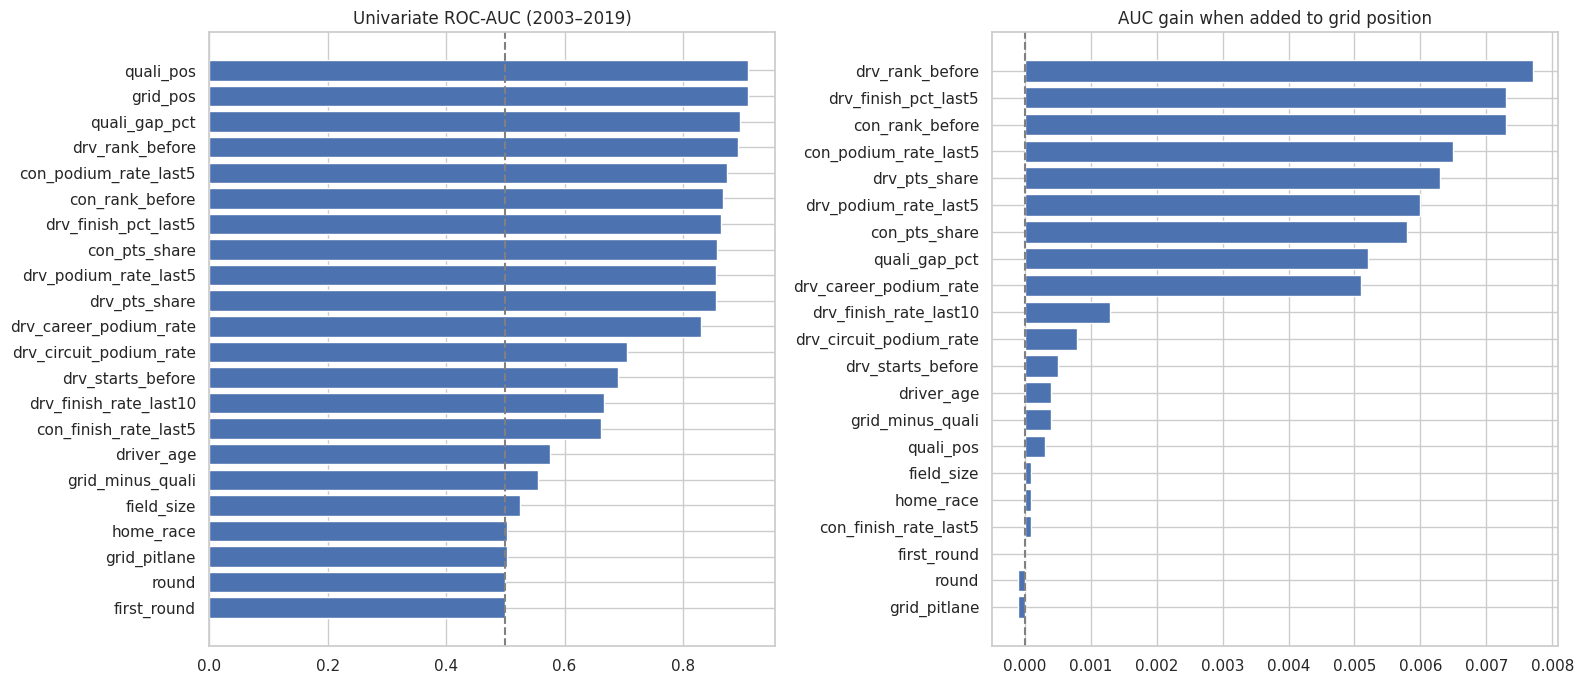

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

dev = feat[(feat.year >= 2003) & (feat.year <= 2019)].copy()

def screen_auc(cols, data=None):
    d = dev if data is None else data
    tr, va = d[d.year <= 2015], d[d.year >= 2016]
    m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000))
    m.fit(tr[cols], tr.podium)
    return roc_auc_score(va.podium, m.predict_proba(va[cols])[:, 1])

grid_auc = screen_auc(['grid_pos'])
rows = []
for g, cols in FEATURE_GROUPS.items():
    for f in cols:
        x = dev[f]; ok = x.notna()
        uni = roc_auc_score(dev.podium[ok], x[ok])
        rows.append(dict(group=g, feature=f, missing=round(x.isna().mean(), 3),
                         univariate_auc=round(max(uni, 1 - uni), 3), direction='+' if uni >= 0.5 else '−',
                         auc_grid_plus_feature=round(grid_auc if f == 'grid_pos' else screen_auc(['grid_pos', f]), 4)))
screen = pd.DataFrame(rows)
screen['gain_over_grid'] = (screen.auc_grid_plus_feature - grid_auc).round(4)
print(f'Grid-only AUC (train 2003–2015 → score 2016–2019): {grid_auc:.4f}')
display(screen.sort_values('univariate_auc', ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
s = screen.sort_values('univariate_auc')
ax[0].barh(s.feature, s.univariate_auc); ax[0].axvline(0.5, ls='--', c='grey'); ax[0].set_title('Univariate ROC-AUC (2003–2019)')
s = screen[screen.feature != 'grid_pos'].sort_values('gain_over_grid')
ax[1].barh(s.feature, s.gain_over_grid); ax[1].axvline(0, ls='--', c='grey'); ax[1].set_title('AUC gain when added to grid position')
plt.tight_layout(); save('feature_screening')

### Screening findings
- **Grid alone is a strong baseline:** AUC 0.9303 (train 2003–2015 → score 2016–2019).
- **Largest gains over grid:** standings (`drv_rank_before` +0.0077, `con_rank_before` +0.0073, `drv_pts_share` +0.0063,
  `con_pts_share` +0.0058), recent form (`drv_finish_pct_last5` +0.0073, `con_podium_rate_last5` +0.0065,
  `drv_podium_rate_last5` +0.0060), `quali_gap_pct` (+0.0052) and `drv_career_podium_rate` (+0.0051).
  These carry information that grid position does not: car and driver strength, and qualifying pace rather than just order.
- **No signal:** `home_race` (0.503), `grid_pitlane` (0.502), `first_round` (0.500) and `round` (0.500) have univariate
  AUC ≈ 0.5 and gain ≤ 0.0001. For `home_race` this matches Q2, which found no home effect after controlling for grid.
- `quali_pos` has a strong univariate AUC (0.910) but adds only 0.0003 over grid, because it carries the same information.

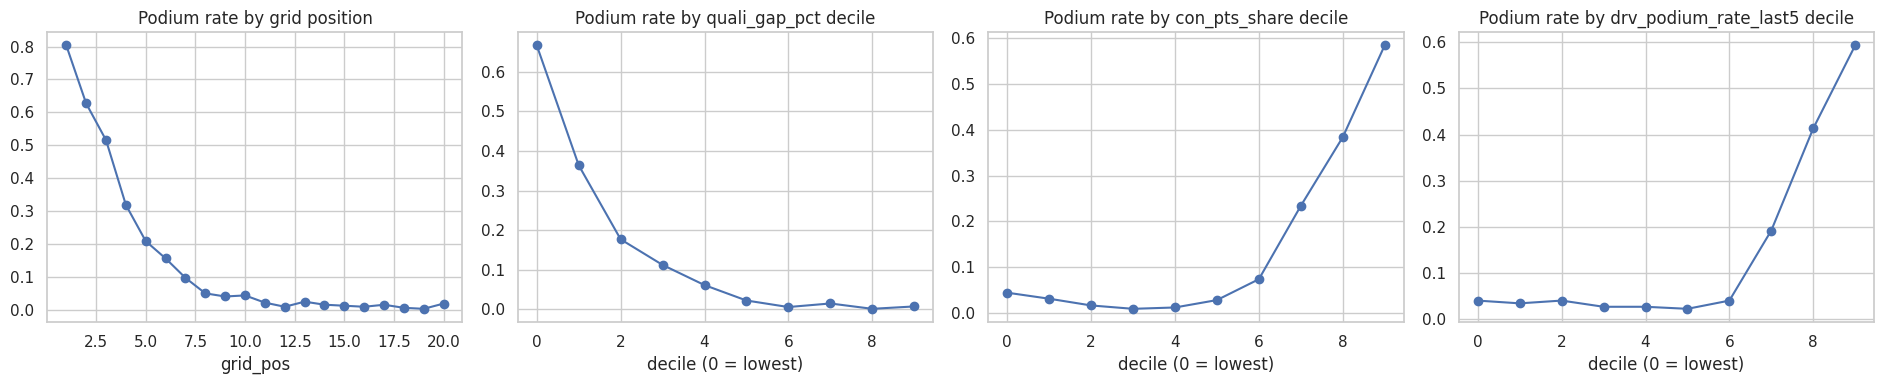

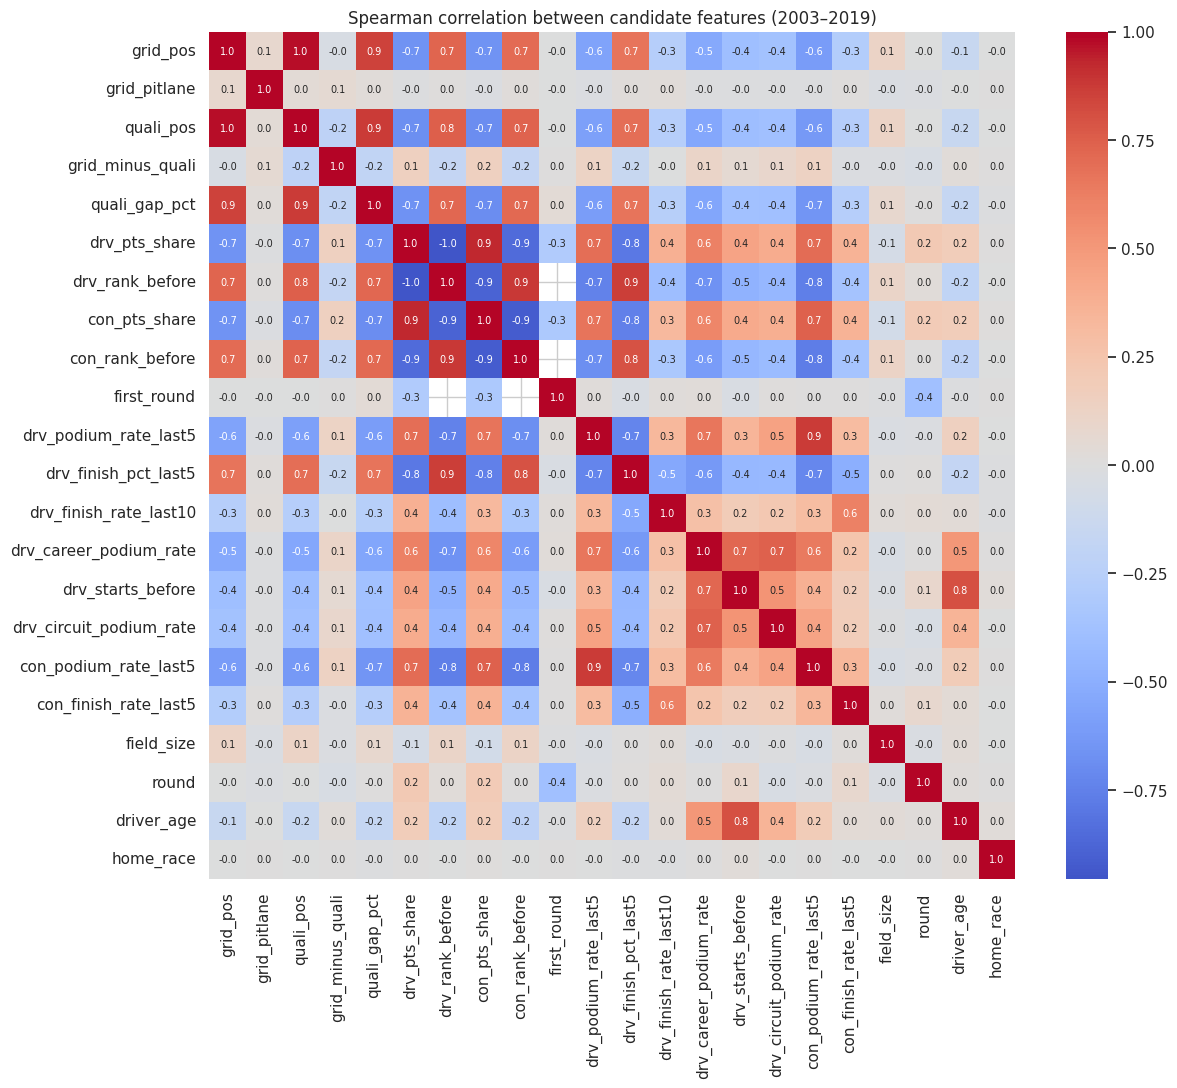

,level_0,level_1,rho
1,grid_pos,quali_pos,0.970
95,drv_pts_share,drv_rank_before,-0.954
96,drv_pts_share,con_pts_share,0.926
125,con_pts_share,con_rank_before,-0.924
111,drv_rank_before,con_pts_share,-0.890
112,drv_rank_before,con_rank_before,0.884
42,quali_pos,quali_gap_pct,0.878
168,drv_podium_rate_last5,con_podium_rate_last5,0.872
114,drv_rank_before,drv_finish_pct_last5,0.868
97,drv_pts_share,con_rank_before,-0.853


In [22]:
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
dev[dev.grid_pos <= 20].groupby('grid_pos').podium.mean().plot(ax=ax[0], marker='o', title='Podium rate by grid position')
for a, f in zip(ax[1:], ['quali_gap_pct', 'con_pts_share', 'drv_podium_rate_last5']):
    dev.groupby(pd.qcut(dev[f].rank(method='first'), 10, labels=False)).podium.mean().plot(ax=a, marker='o')
    a.set_title(f'Podium rate by {f} decile'); a.set_xlabel('decile (0 = lowest)')
plt.tight_layout(); save('feature_shapes')

corr = dev[ALL_FEATURES].corr(method='spearman')
plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Spearman correlation between candidate features (2003–2019)'); save('feature_correlation')
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .rename('rho').reset_index().query('abs(rho) >= 0.8').sort_values('rho', key=abs, ascending=False))
display(pairs.round(3))

### Shapes and redundancy
- **Strongly non-linear relationships:** podium rate falls steeply over the first ~8 grid positions and is near 0
  beyond P10. For `con_pts_share` and `drv_podium_rate_last5`, the bottom ~6 deciles are near 0 and the top deciles
  rise sharply. A purely linear model will struggle with these thresholds, which motivates comparing it against
  tree-based models and a neural network (Section 6).
- **Near-duplicate pairs (|ρ| ≥ 0.9):** `grid_pos`/`quali_pos` (0.970), `drv_pts_share`/`drv_rank_before` (−0.954),
  `drv_pts_share`/`con_pts_share` (0.926), `con_pts_share`/`con_rank_before` (−0.924). Keeping both features of a pair
  adds little information and splits importance between them in the XAI section, so we choose between them
  empirically below.

,window (races),driver form: AUC grid + feature,constructor form: AUC grid + feature
0,3,0.9350,0.9368
1,5,0.9363,0.9368
2,10,0.9395,0.9389
3,15,0.9409,0.9407
4,20,0.9403,0.9407


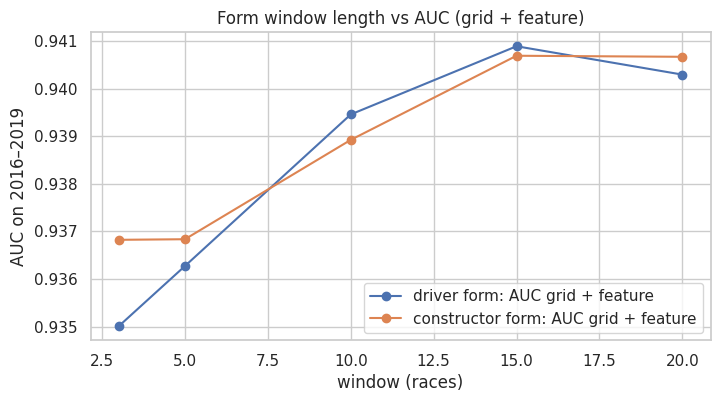

Chosen windows -> driver form: 15 races | constructor form: 15 races


In [23]:
wt = feat.copy()
team = (wt.groupby(['constructorId', 'raceId', 'date'], as_index=False).agg(team_podium=('podium', 'mean'))
          .sort_values(['date', 'raceId']).reset_index(drop=True))
WINDOWS = [3, 5, 10, 15, 20]
for w in WINDOWS:
    wt[f'drv_pod_{w}'] = past_rolling(wt, 'driverId', 'podium', w)
    team[f'con_pod_{w}'] = past_rolling(team, 'constructorId', 'team_podium', w)
wt = wt.merge(team.drop(columns=['date', 'team_podium']), on=['constructorId', 'raceId'], how='left')
dev_w = wt[(wt.year >= 2003) & (wt.year <= 2019)]
trial = pd.DataFrame([{'window (races)': w,
                       'driver form: AUC grid + feature': screen_auc(['grid_pos', f'drv_pod_{w}'], dev_w),
                       'constructor form: AUC grid + feature': screen_auc(['grid_pos', f'con_pod_{w}'], dev_w)}
                      for w in WINDOWS])
display(trial.round(4))
trial.set_index('window (races)').plot(marker='o', figsize=(8, 4), title='Form window length vs AUC (grid + feature)')
plt.ylabel('AUC on 2016–2019'); save('form_window_trial')

W_DRV = int(trial.loc[trial['driver form: AUC grid + feature'].idxmax(), 'window (races)'])
W_CON = int(trial.loc[trial['constructor form: AUC grid + feature'].idxmax(), 'window (races)'])
print(f'Chosen windows -> driver form: {W_DRV} races | constructor form: {W_CON} races')

### Form window — decision
Driver form peaks at a **15-race** window (AUC 0.9409, vs 0.9363 for 5 and 0.9403 for 20). Constructor form is equal
at 15 and 20 (0.9407), and we take the shorter one. Both form windows are therefore **15 races**. Shorter windows react
faster but are noisier; on this data the longer window is the better predictor.
The time-travel test was re-run on the final definitions (cell 4.7): 0 changes at all 3 cutoffs, and the maximum
`drv_finish_pct_last15` is 1.0 after the finish-percentile fix.

In [24]:
FEATURE_GROUPS = make_feature_groups(W_DRV, W_CON)
ALL_FEATURES = [f for g in FEATURE_GROUPS.values() for f in g]
feat = build_features(base, W_DRV, W_CON)
pl = feat[feat.grid == 0]
print(f'Pit-lane starts: {len(pl)} | all placed behind every grid slot of their race:',
      bool((pl.grid_pos > feat.grid.where(feat.grid > 0).groupby(feat.raceId).transform('max')[pl.index]).all()))
dev = feat[(feat.year >= 2003) & (feat.year <= 2019)].copy()

# Re-run the time-travel test on the FINAL feature definitions (3 cutoffs)
rng = np.random.default_rng(SEED)
race_dates = feat.drop_duplicates('raceId')[['raceId', 'date']]
recheck = []
for rid in rng.choice(race_dates[race_dates.date.dt.year >= 2003].raceId.values, 3, replace=False):
    D = race_dates.loc[race_dates.raceId == rid, 'date'].iloc[0]
    scr = base.copy(); m = scr.date >= D
    scr.loc[m, 'positionOrder'] = scr.loc[m].groupby('raceId').positionOrder.transform(lambda s: rng.permutation(s.values))
    scr.loc[m, 'status'] = scr.loc[m].groupby('raceId').status.transform(lambda s: rng.permutation(s.values))
    scr['podium'] = (scr.positionOrder <= 3).astype(int)
    f_scr = build_features(scr, W_DRV, W_CON)
    recheck.append({'cutoff date': D.date(), 'changed AT cutoff (must be 0)':
                    int(changed_cells(feat[feat.date == D], f_scr[f_scr.date == D]).sum())})
display(pd.DataFrame(recheck))
assert all(r['changed AT cutoff (must be 0)'] == 0 for r in recheck)
print('Max drv_finish_pct:', round(feat[f'drv_finish_pct_last{W_DRV}'].max(), 3), '(must be ≤ 1)')

Pit-lane starts: 128 | all placed behind every grid slot of their race: True


,cutoff date,changed AT cutoff (must be 0)
0,2018-04-08,0
1,2005-05-08,0
2,2020-09-27,0


Max drv_finish_pct: 1.0 (must be ≤ 1)


### Feature selection by forward selection
Instead of hand-picking from near-duplicate pairs, we let the data decide. Starting from grid position, each step adds
the single feature that most improves AUC (logistic regression, train 2003–2015 → score 2016–2019), until every
candidate is added. The resulting curve shows where adding features stops helping, and the final set is taken at that
plateau. Validation (2020–2021) and test (2022–2024) seasons are never used here.
*Limitation:* the screen uses a linear model, so it may undervalue features that only help non-linear models.
Section 7's ablation re-checks every feature group with the final models.

,step,added,auc,gain
0,0,grid_pos,0.9303,NaN
1,1,drv_finish_pct_last15,0.9435,0.0133
2,2,drv_finish_rate_last10,0.9452,0.0017
3,3,quali_gap_pct,0.9464,0.0012
4,4,con_podium_rate_last15,0.9468,0.0004
5,5,driver_age,0.9474,0.0006
6,6,con_rank_before,0.9477,0.0003
7,7,first_round,0.9480,0.0003
8,8,con_finish_rate_last15,0.9481,0.0000
9,9,grid_pitlane,0.9481,0.0000


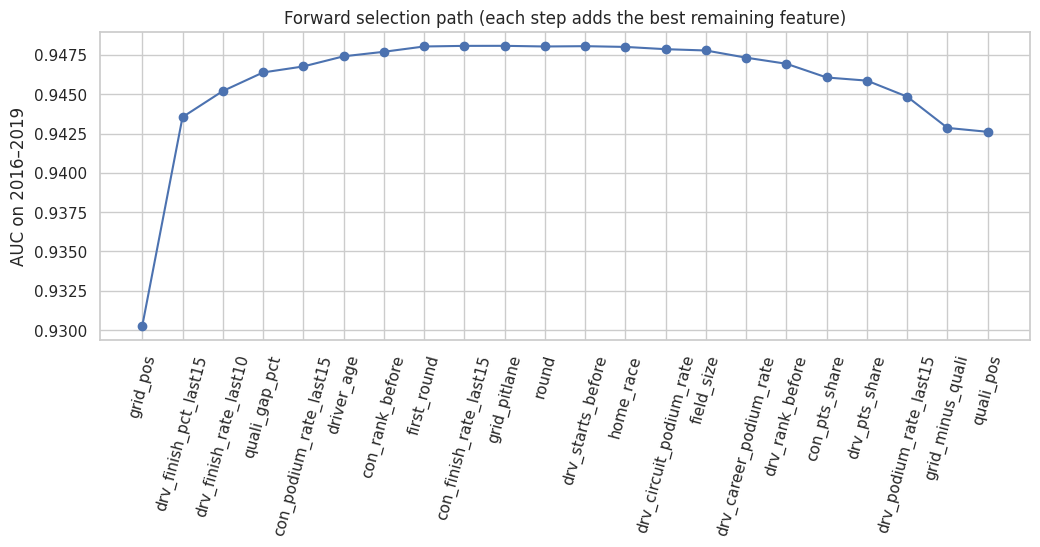

In [25]:
pool = [f for f in ALL_FEATURES if f != 'grid_pos']
selected = ['grid_pos']
path = [{'step': 0, 'added': 'grid_pos', 'auc': screen_auc(selected)}]
while pool:
    scores = {f: screen_auc(selected + [f]) for f in pool}
    best = max(scores, key=scores.get)
    selected.append(best); pool.remove(best)
    path.append({'step': len(selected) - 1, 'added': best, 'auc': scores[best]})
path = pd.DataFrame(path)
path['gain'] = path.auc.diff()
display(path.round(4))

plt.figure(figsize=(12, 4))
plt.plot(path.step, path.auc, marker='o')
plt.xticks(path.step, path.added, rotation=75); plt.ylabel('AUC on 2016–2019')
plt.title('Forward selection path (each step adds the best remaining feature)')
save('forward_selection')

### Final feature set — decision
**Stopping rule:** keep every feature added before the first step that no longer improves AUC.
The curve rises until step 7 (AUC 0.9480), adds 0.0000 at step 8, plateaus, and then **declines** to 0.9426 with all
22 candidates. Extra features beyond this point only add noise for the model.

| Group (for ablation) | Feature | Forward-selection step | AUC gain |
|---|---|---|---|
| grid | `grid_pos` | start | AUC 0.9303 alone |
| driver form | `drv_finish_pct_last15` | 1 | +0.0133 |
| driver form | `drv_finish_rate_last10` | 2 | +0.0017 |
| qualifying | `quali_gap_pct` | 3 | +0.0012 |
| constructor form | `con_podium_rate_last15` | 4 | +0.0004 |
| context | `driver_age` | 5 | +0.0006 |
| standings | `con_rank_before` | 6 | +0.0003 |
| standings | `first_round` | 7 | +0.0003 |

**Dropped, with evidence:**
- `quali_pos`: ρ = 0.970 with `grid_pos`, added last (step 21).
- `drv_pts_share`, `con_pts_share`, `drv_rank_before`: near-duplicates of the chosen standings feature (|ρ| ≥ 0.89);
  each lowered AUC when added (steps 16–18).
- `home_race`: gain −0.0000 (step 12), consistent with Q2 (no home effect after controlling for grid).
- `grid_pitlane`, `round`, `field_size`, `drv_starts_before`, `con_finish_rate_last15`: gain ≤ 0.0000.
- `drv_podium_rate_last15`, `drv_career_podium_rate`, `drv_circuit_podium_rate`, `grid_minus_quali`: each lowered AUC
  when added after the selected features.

**Caveat:** the screen uses logistic regression and the 2016–2019 seasons, so the selection is tuned to a linear model
and that window. The validation and test seasons were never used. Section 7's ablation re-checks every group with the
final models.

In [26]:
stop = path.index[(path.step > 0) & (path.gain < 0.00005)][0] - 1      # last step before the first non-improving addition
FEATURES = path.added[:stop + 1].tolist()
GROUP_OF = {'grid_pos': 'grid', 'quali_pos': 'qualifying', 'quali_gap_pct': 'qualifying', 'grid_minus_quali': 'qualifying',
            'grid_pitlane': 'grid'}
for g, cols in FEATURE_GROUPS.items():
    for c in cols:
        GROUP_OF.setdefault(c, g)
FINAL_GROUPS = {}
for f in FEATURES:
    FINAL_GROUPS.setdefault(GROUP_OF[f], []).append(f)
print('Final features:', FEATURES)
display(pd.Series(FINAL_GROUPS).to_frame('features'))

# Why does first_round help? Hypothesis: it marks rows where standings rank is missing because no race has been run yet
r = feat[feat.year >= 2003]
display(pd.crosstab(r.first_round, r.con_rank_before.isna(), margins=True,
                    rownames=['first_round'], colnames=['con_rank_before missing']))

model_df = feat[feat.year >= 2003][KEY + ['year', 'round', 'date', 'circuitRef', 'driverRef', 'constructorRef', 'podium']
                                   + FEATURES].reset_index(drop=True)
assert not model_df.duplicated(KEY).any()
model_df.to_csv('modeling_table.csv', index=False)
print('Modeling table:', model_df.shape)

Final features: ['grid_pos', 'drv_finish_pct_last15', 'drv_finish_rate_last10', 'quali_gap_pct', 'con_podium_rate_last15', 'driver_age', 'con_rank_before', 'first_round']


,features
grid,[grid_pos]
driver_form,"[drv_finish_pct_last15, drv_finish_rate_last10]"
qualifying,[quali_gap_pct]
constructor_form,[con_podium_rate_last15]
context,[driver_age]
standings,"[con_rank_before, first_round]"


con_rank_before missing,False,True,All
first_round,,,
0,8448,32,8480
1,0,455,455
All,8448,487,8935


Modeling table: (8935, 17)


**Why `first_round` helps:** all 455 first-round rows have no constructor rank (no race has been run yet), versus only
32 of 8,480 other rows (crosstab above). Without this flag, the imputed median rank would look like a real mid-table
team. With it, the model can tell "season not started" apart from "genuinely mid-table".
The final modeling table has 8,935 rows × 8 features (seasons 2003–2024).

# 5. Train / Validation / Test Split & Preprocessing
**Split by season:** train 2003–2019, validation 2020–2021, test 2022–2024 (the boundaries suggested in the course's
F1 primer). A time-based split mirrors real use: the model is trained on the past and evaluated on races it could
not have seen. Every race falls entirely inside one split, so drivers from the same race are never split between
training and evaluation. The test seasons are used **once**, at the very end.

In [27]:
model_df['split'] = np.select([model_df.year <= 2019, model_df.year <= 2021], ['train', 'validation'], 'test')
assert model_df.groupby('raceId').split.nunique().max() == 1          # no race is split across sets
display(model_df.groupby('split', sort=False).agg(
    seasons=('year', lambda s: f'{s.min()}–{s.max()}'), races=('raceId', 'nunique'),
    rows=('podium', 'size'), podium_rate=('podium', 'mean')).round(3))
display(model_df.groupby('split', sort=False)[FEATURES].apply(lambda d: d.isna().mean()).round(3)
        .T.rename_axis('missing share'))

TRAIN = model_df[model_df.split == 'train']; VAL = model_df[model_df.split == 'validation']; TEST = model_df[model_df.split == 'test']
X_tr, y_tr = TRAIN[FEATURES], TRAIN.podium
X_va, y_va = VAL[FEATURES], VAL.podium
X_te, y_te = TEST[FEATURES], TEST.podium

,seasons,races,rows,podium_rate
split,,,,
train,2003–2019,321,6802,0.142
validation,2020–2021,39,779,0.150
test,2022–2024,68,1354,0.151


split,train,validation,test
missing share,,,
grid_pos,0.000,0.000,0.000
drv_finish_pct_last15,0.011,0.008,0.006
drv_finish_rate_last10,0.011,0.008,0.006
quali_gap_pct,0.018,0.012,0.010
con_podium_rate_last15,0.005,0.005,0.001
driver_age,0.000,0.000,0.000
con_rank_before,0.057,0.051,0.044
first_round,0.000,0.000,0.000


In [28]:
# Empirical check of the split choice on train+validation seasons only (test untouched)
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score

def lr_pipe():
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=1000))

tv = model_df[model_df.split != 'test']
rows = []
for seed in range(5):
    a, b = train_test_split(tv, test_size=len(VAL) / len(tv), random_state=seed, stratify=tv.podium)
    p = lr_pipe().fit(a[FEATURES], a.podium).predict_proba(b[FEATURES])[:, 1]
    rows.append({'split': f'random rows (seed {seed})', 'ROC-AUC': roc_auc_score(b.podium, p), 'PR-AUC': average_precision_score(b.podium, p)})
p = lr_pipe().fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
rows.append({'split': 'time: 2003–2019 → 2020–2021', 'ROC-AUC': roc_auc_score(y_va, p), 'PR-AUC': average_precision_score(y_va, p)})
display(pd.DataFrame(rows).round(4))

,split,ROC-AUC,PR-AUC
0,random rows (seed 0),0.9317,0.6964
1,random rows (seed 1),0.9198,0.6904
2,random rows (seed 2),0.9187,0.6522
3,random rows (seed 3),0.9198,0.6365
4,random rows (seed 4),0.9427,0.7639
5,time: 2003–2019 → 2020–2021,0.9287,0.7271


### Split — findings
- Train: 321 races / 6,802 rows; validation: 39 / 779; test: 68 / 1,354. The podium rate is stable (0.142 / 0.150 / 0.151),
  so the class balance does not drift between splits. Missing shares are small in every split (≤ 5.7%).
- **Random vs time split (cell 5.2):** the time split gives PR-AUC 0.727, inside the range of five random splits
  (0.637–0.764). Random splitting does not inflate the score here, but it would still be the wrong design: it puts
  rows of the same race in both train and evaluation, and it trains on seasons that come after the ones it is tested
  on, which is impossible in real use. We keep the time split.
- **Important side finding:** just changing the random seed moves PR-AUC by up to **0.13** on an evaluation set of this
  size. Differences between models of a few thousandths are therefore not meaningful on their own, so all model
  comparisons below use a **paired race-level bootstrap** confidence interval.

### Preprocessing and preprocessing-order experiments
Pipeline: **median imputation → standardisation**, fitted on the training seasons only. Missing values come from
known structural causes (Sections 1–4: rookies have no form history, round-1 rows have no standings, a few drivers
have no qualifying time). Standardisation puts features on a common scale, which logistic regression and the neural
network need; tree models are unaffected by it.
Experiments (logistic regression baseline, evaluated on validation, test untouched):
1. **Where preprocessing is fitted:** train only (correct) vs train + validation + test (leaks information from
   future seasons into the scaling and imputation statistics).
2. **Order:** impute → scale vs scale → impute.
3. **Missing indicators:** median imputation alone vs median imputation + a 0/1 "was missing" column per feature.

before                        after              \
                          mean    std     min     max  mean  std    min   
grid_pos                11.197  6.238   1.000  24.000   0.0  1.0 -1.635   
drv_finish_pct_last15    0.498  0.198   0.017   1.000   0.0  1.0 -2.448   
drv_finish_rate_last10   0.772  0.176   0.000   1.000  -0.0  1.0 -4.405   
quali_gap_pct            2.379  2.605   0.000  37.797   0.0  1.0 -0.917   
con_podium_rate_last15   0.144  0.215   0.000   1.000  -0.0  1.0 -0.667   
driver_age              28.131  4.892  17.454  43.893   0.0  1.0 -2.183   
con_rank_before          5.834  3.109   1.000  12.000  -0.0  1.0 -1.604   
first_round              0.052  0.222   0.000   1.000  -0.0  1.0 -0.235   

                                
                           max  
grid_pos                 2.053  
drv_finish_pct_last15    2.555  
drv_finish_rate_last10   1.299  
quali_gap_pct           13.724  
con_podium_rate_last15   3.983  
driver_age               3.223  
con_rank_before          2.039  
first_round              4.262

Missing values before: 698 | after: 0


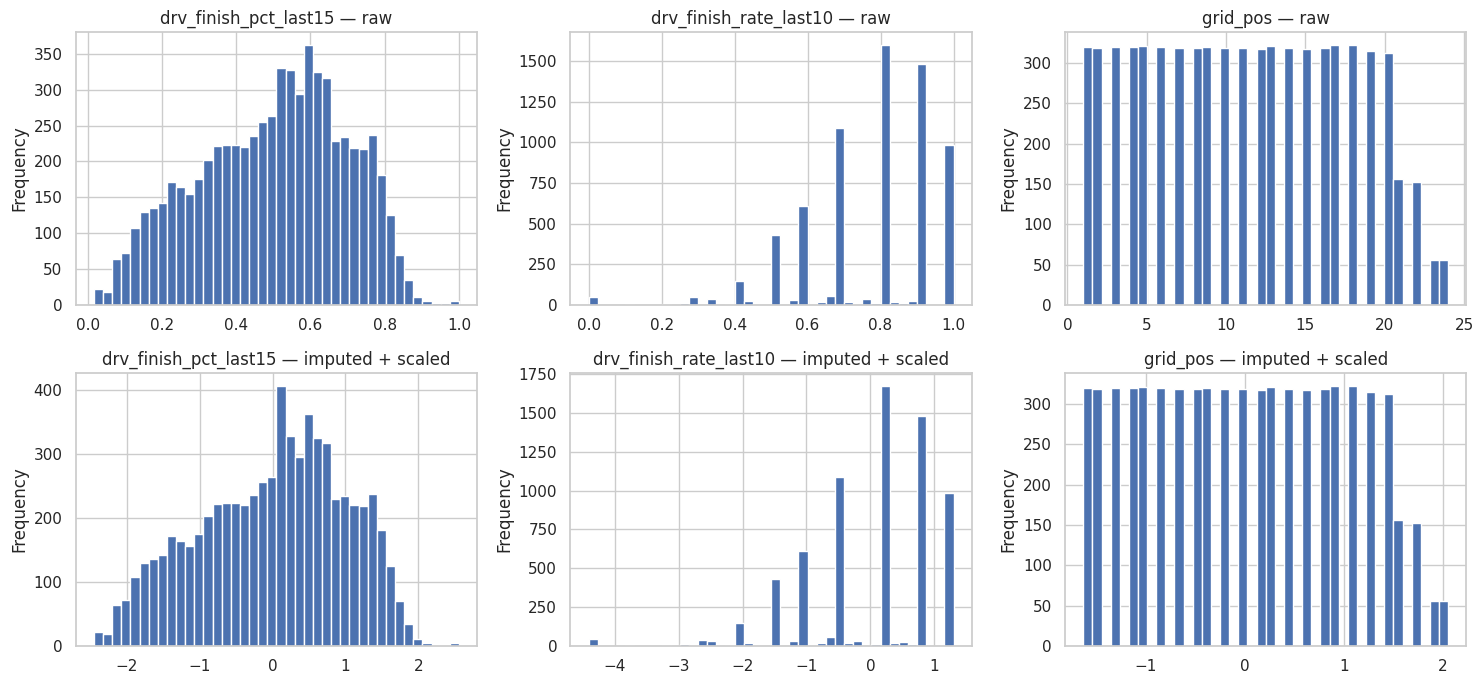

,ROC-AUC,PR-AUC
"E1a impute→scale, fitted on TRAIN only (correct)",0.9287,0.7271
E1b LEAKAGE CONTROL — fitted on ALL seasons (invalid),0.9287,0.7272
"E2 scale→impute, fitted on train",0.9287,0.7270
"E3 impute + missing indicators → scale, on train",0.9309,0.7300


In [29]:
pre = make_pipeline(SimpleImputer(strategy='median'), StandardScaler()).fit(X_tr)
X_tr_p = pd.DataFrame(pre.transform(X_tr), columns=FEATURES, index=X_tr.index)
display(pd.concat({'before': X_tr.describe().T[['mean', 'std', 'min', 'max']],
                   'after':  X_tr_p.describe().T[['mean', 'std', 'min', 'max']]}, axis=1).round(3))
print('Missing values before:', int(X_tr.isna().sum().sum()), '| after:', int(X_tr_p.isna().sum().sum()))

show = [f for f in FEATURES if X_tr[f].isna().any()][:2] + ['grid_pos']
fig, ax = plt.subplots(2, len(show), figsize=(5 * len(show), 7))
for i, f in enumerate(show):
    X_tr[f].plot(kind='hist', bins=40, ax=ax[0, i], title=f'{f} — raw')
    X_tr_p[f].plot(kind='hist', bins=40, ax=ax[1, i], title=f'{f} — imputed + scaled')
plt.tight_layout(); save('preprocessing_effect')

def run(pre_steps, fit_pre_on):
    pre = make_pipeline(*pre_steps).fit(fit_pre_on)
    m = LogisticRegression(max_iter=1000).fit(pre.transform(X_tr), y_tr)
    p = m.predict_proba(pre.transform(X_va))[:, 1]
    return {'ROC-AUC': roc_auc_score(y_va, p), 'PR-AUC': average_precision_score(y_va, p)}

X_all = model_df[FEATURES]
exp = pd.DataFrame({
    'E1a  impute→scale, fitted on TRAIN only (correct)':      run([SimpleImputer(strategy='median'), StandardScaler()], X_tr),
    'E1b  LEAKAGE CONTROL — fitted on ALL seasons (invalid)':      run([SimpleImputer(strategy='median'), StandardScaler()], X_all),
    'E2   scale→impute, fitted on train':                      run([StandardScaler(), SimpleImputer(strategy='median')], X_tr),
    'E3   impute + missing indicators → scale, on train':     run([SimpleImputer(strategy='median', add_indicator=True), StandardScaler()], X_tr),
}).T.round(4)
display(exp)

### Preprocessing — findings
- After imputation and scaling, every feature has mean 0 and standard deviation 1 (fitted on train), and missing values
  drop from 698 to 0. The histograms keep their shape; only the axis changes. Imputed values sit at the median.
- **E1b is a deliberate leakage control, not a candidate pipeline.** Fitting the imputer/scaler on all seasons uses
  statistics from future (validation/test) seasons. It scores the same as the correct train-only fit (PR-AUC 0.7271
  vs 0.7272), so leakage through preprocessing statistics is negligible with these 8 features, but E1b is never eligible.
- **E2 (impute→scale vs scale→impute):** practically identical (0.7271 vs 0.7270). Median imputation and standardisation
  almost commute when few values are missing (≤ 5.7%). We keep impute→scale, the standard order.
- **E3 (missing indicators):** +0.0022 ROC-AUC and +0.0029 PR-AUC. That is smaller than the seed-to-seed noise in 5.2,
  so it is tested with a paired bootstrap below before deciding.
- **Valid alternatives compared:** E1a impute→scale, E2 scale→impute, E3 with missing indicators. **Selected: E1a**
  (E2 is equivalent; E3 is tested below and not adopted).


In [30]:
def bootstrap_diff(y, p_a, p_b, races, metric=average_precision_score, n=1000):
    """Paired race-level bootstrap of metric(A) - metric(B) on the SAME evaluation rows."""
    rng = np.random.default_rng(SEED)
    y = np.asarray(y); p_a = np.asarray(p_a); p_b = np.asarray(p_b); races = np.asarray(races)
    ids = np.unique(races); rows_of = {r: np.where(races == r)[0] for r in ids}
    diffs = []
    for _ in range(n):
        s = np.concatenate([rows_of[r] for r in rng.choice(ids, len(ids))])
        diffs.append(metric(y[s], p_a[s]) - metric(y[s], p_b[s]))
    diffs = np.array(diffs)
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return {'mean diff': diffs.mean(), 'CI low': lo, 'CI high': hi, 'P(A > B)': (diffs > 0).mean()}

def lr_variant(indicators):
    pre = make_pipeline(SimpleImputer(strategy='median', add_indicator=indicators), StandardScaler()).fit(X_tr)
    m = LogisticRegression(max_iter=1000).fit(pre.transform(X_tr), y_tr)
    return m.predict_proba(pre.transform(X_va))[:, 1]

res = bootstrap_diff(y_va, lr_variant(True), lr_variant(False), VAL.raceId)
display(pd.Series(res, name='E3 (with indicators) − E1a (without), PR-AUC').round(4).to_frame())
USE_INDICATORS = res['CI low'] > 0
print('Use missing indicators in the final pipeline:', USE_INDICATORS)

,"E3 (with indicators) − E1a (without), PR-AUC"
mean diff,0.0028
CI low,-0.0030
CI high,0.0101
P(A > B),0.7830


Use missing indicators in the final pipeline: False


### E3 decision — missing indicators
A paired race-level bootstrap (1,000 resamples of the 39 validation races) gives a PR-AUC difference of **+0.0028**,
with a 95% CI of **−0.0030 to +0.0101**. The interval includes 0: indicators beat the plain pipeline in 78.3% of
resamples, which is not convincing. **We do not add missing indicators.** The final pipeline is median imputation →
standardisation, fitted on train. The indicator idea is also partly covered already: `first_round` explicitly flags
the main source of missing standings (cell 4.9).

The same bootstrap is used for every model comparison in Section 6, so a model is only called "better" when its
confidence interval vs the baseline excludes 0.

# 6. Modeling
### Metrics
- **Primary: PR-AUC (average precision).** Only ~15% of rows are podiums, so a model predicting "no podium" for everyone
  already scores ~85% accuracy. PR-AUC measures how well the model ranks the true podium finishers at the top,
  and it is not inflated by the large number of easy negatives.
- **Secondary:**
  - **ROC-AUC:** threshold-free and comparable with the feature screening in Section 4.
  - **Precision / recall / F1** at a decision threshold chosen on validation (the threshold that maximises F1).
  - **Top-3 precision per race:** in each race we predict the 3 drivers with the highest probability, and report the
    share of them who really finished on the podium. This matches how the prediction would be used: every race has
    exactly three podium places.

### Protocol
All models use the same 8 features and the same split. Hyperparameters and thresholds are chosen on **validation**
(2020–2021). The **test** seasons (2022–2024) are evaluated once, in Section 6C, after all choices are fixed.
Every attempt is shown in its own cell, and all results are collected in one comparison table.

In [31]:
from sklearn.metrics import precision_recall_fscore_support, precision_recall_curve

def top3_precision(y, p, races):
    d = pd.DataFrame({'y': np.asarray(y), 'p': np.asarray(p), 'r': np.asarray(races)})
    d['rank'] = d.groupby('r').p.rank(ascending=False, method='first')
    return d.loc[d['rank'] <= 3, 'y'].mean()

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return thr[np.nanargmax(f1[:-1])]

def evaluate(name, y, p, races, thr):
    pr, rc, f1, _ = precision_recall_fscore_support(y, (p >= thr).astype(int), average='binary', zero_division=0)
    return {'model': name, 'PR-AUC': average_precision_score(y, p), 'ROC-AUC': roc_auc_score(y, p),
            'precision': pr, 'recall': rc, 'F1': f1, 'top-3 precision': top3_precision(y, p, races), 'threshold': thr}

RESULTS, VAL_PRED, MODELS = [], {}, {}

# Attempt 0 — rule baseline (no learning): rank drivers by starting position
p_rule_va = -VAL.grid_pos.values                       # higher score = better grid
RESULTS.append(evaluate('Rule: grid position (no ML)', y_va, p_rule_va, VAL.raceId, thr=-3.5))   # thr -3.5 == grid ≤ 3
VAL_PRED['rule'] = p_rule_va
display(pd.DataFrame(RESULTS).round(4))

,model,PR-AUC,ROC-AUC,precision,recall,F1,top-3 precision,threshold
0,Rule: grid position (no ML),0.6386,0.9093,0.6923,0.6923,0.6923,0.6923,-3.5


### Attempt 1 — Logistic regression (official baseline)
The simplest learned model: a linear combination of the features. Tuned on validation: regularisation strength `C`
and class weighting (none vs `balanced`, which up-weights the rarer podium class).

In [32]:
def pre_steps(scale=True):
    steps = [SimpleImputer(strategy='median', add_indicator=USE_INDICATORS)]
    return steps + [StandardScaler()] if scale else steps

grid_lr = []
for C in [0.01, 0.1, 1, 10]:
    for cw in [None, 'balanced']:
        m = make_pipeline(*pre_steps(), LogisticRegression(C=C, class_weight=cw, max_iter=2000)).fit(X_tr, y_tr)
        p = m.predict_proba(X_va)[:, 1]
        grid_lr.append({'C': C, 'class_weight': cw, 'val PR-AUC': average_precision_score(y_va, p), 'val ROC-AUC': roc_auc_score(y_va, p), 'model': m})
grid_lr = pd.DataFrame(grid_lr)
display(grid_lr.drop(columns='model').round(4))
best = grid_lr.loc[grid_lr['val PR-AUC'].idxmax()]
MODELS['LogReg'] = best.model; p = best.model.predict_proba(X_va)[:, 1]; VAL_PRED['LogReg'] = p
RESULTS.append(evaluate(f'LogReg (C={best.C}, cw={best.class_weight})', y_va, p, VAL.raceId, best_f1_threshold(y_va, p)))
coef = pd.Series(best.model[-1].coef_[0][:len(FEATURES)], index=FEATURES).sort_values()
display(coef.round(3).to_frame('standardised coefficient'))

,C,class_weight,val PR-AUC,val ROC-AUC
0,0.01,None,0.7035,0.9262
1,0.01,balanced,0.7035,0.9257
2,0.10,None,0.7235,0.9283
3,0.10,balanced,0.7157,0.9267
4,1.00,None,0.7271,0.9287
5,1.00,balanced,0.7166,0.9268
6,10.00,None,0.7279,0.9287
7,10.00,balanced,0.7173,0.9268


,standardised coefficient
grid_pos,-1.480
drv_finish_pct_last15,-0.797
quali_gap_pct,-0.668
con_rank_before,-0.331
drv_finish_rate_last10,-0.280
driver_age,-0.142
first_round,0.111
con_podium_rate_last15,0.273


**Logistic regression — findings.** Best: C = 10, no class weighting (val PR-AUC 0.7279). Performance is flat from
C = 0.1 to 10, so regularisation strength barely matters with 8 features. `class_weight='balanced'` is worse at every
C: re-weighting shifts predicted probabilities but does not improve the ranking that PR-AUC measures, so imbalance is
handled by choosing the decision threshold instead.
Largest standardised coefficients: `grid_pos` (−1.48), `drv_finish_pct_last15` (−0.80), `quali_gap_pct` (−0.67),
so a better start, better recent finishes and a smaller qualifying gap all raise the podium probability.
`drv_finish_rate_last10` has a small negative coefficient (−0.28). Coefficients are conditional on the other features,
and this one overlaps with finishing percentile, so it should not be read on its own.

### Attempt 2 — Random forest
Section 4.5 showed strongly non-linear, threshold-like relationships (e.g. podium rate collapses after the first ~8 grid
slots). A random forest learns such thresholds directly. Scaling is not needed, only imputation. Tuned: tree depth and
minimum leaf size (both control overfitting).

In [33]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
grid_rf = []
for depth in [4, 6, 8, None]:
    for leaf in [5, 20, 50]:
        m = make_pipeline(*pre_steps(scale=False), RandomForestClassifier(n_estimators=400, max_depth=depth, min_samples_leaf=leaf,
                                                                          n_jobs=-1, random_state=SEED)).fit(X_tr, y_tr)
        p = m.predict_proba(X_va)[:, 1]
        grid_rf.append({'max_depth': depth, 'min_samples_leaf': leaf, 'val PR-AUC': average_precision_score(y_va, p),
                        'val ROC-AUC': roc_auc_score(y_va, p), 'train PR-AUC': average_precision_score(y_tr, m.predict_proba(X_tr)[:, 1]), 'model': m})
grid_rf = pd.DataFrame(grid_rf)
display(grid_rf.drop(columns='model').round(4))
best = grid_rf.loc[grid_rf['val PR-AUC'].idxmax()]
MODELS['RandomForest'] = best.model; p = best.model.predict_proba(X_va)[:, 1]; VAL_PRED['RandomForest'] = p
RESULTS.append(evaluate(f'RandomForest (depth={best.max_depth}, leaf={best.min_samples_leaf})', y_va, p, VAL.raceId, best_f1_threshold(y_va, p)))

,max_depth,min_samples_leaf,val PR-AUC,val ROC-AUC,train PR-AUC
0,4.0,5,0.7122,0.9316,0.7225
1,4.0,20,0.7260,0.9320,0.7212
2,4.0,50,0.7231,0.9320,0.7170
3,6.0,5,0.7247,0.9320,0.7708
4,6.0,20,0.7342,0.9334,0.7501
5,6.0,50,0.7332,0.9336,0.7272
6,8.0,5,0.7277,0.9300,0.8258
7,8.0,20,0.7317,0.9327,0.7657
8,8.0,50,0.7318,0.9332,0.7278
9,NaN,5,0.7216,0.9271,0.8921


**Random forest — findings.** Best: depth 6, min leaf 20 (val PR-AUC 0.7342, highest so far). The grid shows the
overfitting trade-off directly: with unlimited depth and leaf 5, train PR-AUC is 0.892 but validation drops to 0.722.
Larger leaves (20–50) keep train and validation close. Leaf size controls overfitting more than depth does.

### Attempt 3 — Gradient boosting (HistGradientBoosting)
Boosting builds trees sequentially, each one correcting the errors of the previous ones. It handles missing values
natively, so no imputation is used. Tuned: learning rate, tree size and L2 regularisation. Early stopping uses an
internal slice of the training data, never the validation seasons.

In [34]:
grid_gb = []
for lr in [0.03, 0.1]:
    for leaves in [7, 15, 31]:
        for l2 in [0.0, 1.0]:
            m = HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, l2_regularization=l2, max_iter=500,
                                               early_stopping=True, validation_fraction=0.15, random_state=SEED).fit(X_tr, y_tr)
            p = m.predict_proba(X_va)[:, 1]
            grid_gb.append({'learning_rate': lr, 'max_leaf_nodes': leaves, 'l2': l2, 'trees used': m.n_iter_,
                            'val PR-AUC': average_precision_score(y_va, p), 'val ROC-AUC': roc_auc_score(y_va, p),
                            'train PR-AUC': average_precision_score(y_tr, m.predict_proba(X_tr)[:, 1]), 'model': m})
grid_gb = pd.DataFrame(grid_gb)
display(grid_gb.drop(columns='model').round(4))
best = grid_gb.loc[grid_gb['val PR-AUC'].idxmax()]
MODELS['GradBoost'] = best.model; p = best.model.predict_proba(X_va)[:, 1]; VAL_PRED['GradBoost'] = p
RESULTS.append(evaluate(f'GradBoost (lr={best.learning_rate}, leaves={best.max_leaf_nodes}, l2={best.l2})', y_va, p, VAL.raceId, best_f1_threshold(y_va, p)))

,learning_rate,max_leaf_nodes,l2,trees used,val PR-AUC,val ROC-AUC,train PR-AUC
0,0.03,7,0.0,182,0.7218,0.9276,0.7452
1,0.03,7,1.0,193,0.7202,0.9280,0.7457
2,0.03,15,0.0,139,0.7183,0.9264,0.7766
3,0.03,15,1.0,154,0.7188,0.9272,0.7764
4,0.03,31,0.0,134,0.7163,0.9204,0.8379
5,0.03,31,1.0,130,0.7108,0.9225,0.8270
6,0.10,7,0.0,74,0.7140,0.9253,0.7633
7,0.10,7,1.0,68,0.7161,0.9271,0.7518
8,0.10,15,0.0,51,0.7195,0.9261,0.7866
9,0.10,15,1.0,54,0.7120,0.9242,0.7890


**Gradient boosting — findings.** Best: learning rate 0.03, 7 leaves, no L2 (val PR-AUC 0.7218), slightly below
logistic regression. Larger trees raise training PR-AUC (up to 0.856) while validation falls (down to 0.705): with
8 features and ~6,800 rows, boosting overfits quickly, and the simplest configuration generalises best.

### Attempt 4 — Shallow feed-forward neural network
A small fully connected network (one or two hidden layers, ReLU) can learn non-linear combinations of the features.
Inputs are imputed and standardised, which neural networks need. Tuned: hidden layer sizes and L2 penalty `alpha`.
Early stopping uses an internal 15% of the training data.

In [35]:
from sklearn.neural_network import MLPClassifier
grid_nn = []
for hidden in [(16,), (32,), (32, 16)]:
    for alpha in [1e-4, 1e-3, 1e-2]:
        m = make_pipeline(*pre_steps(), MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, early_stopping=True,
                                                      validation_fraction=0.15, max_iter=1000, random_state=SEED)).fit(X_tr, y_tr)
        p = m.predict_proba(X_va)[:, 1]
        grid_nn.append({'hidden': str(hidden), 'alpha': alpha, 'epochs': m[-1].n_iter_,
                        'val PR-AUC': average_precision_score(y_va, p), 'val ROC-AUC': roc_auc_score(y_va, p),
                        'train PR-AUC': average_precision_score(y_tr, m.predict_proba(X_tr)[:, 1]), 'model': m})
grid_nn = pd.DataFrame(grid_nn)
display(grid_nn.drop(columns='model').round(4))
best = grid_nn.loc[grid_nn['val PR-AUC'].idxmax()]
MODELS['ShallowNN'] = best.model; p = best.model.predict_proba(X_va)[:, 1]; VAL_PRED['ShallowNN'] = p
RESULTS.append(evaluate(f'ShallowNN (hidden={best.hidden}, alpha={best.alpha})', y_va, p, VAL.raceId, best_f1_threshold(y_va, p)))

,hidden,alpha,epochs,val PR-AUC,val ROC-AUC,train PR-AUC
0,"(16,)",0.0001,16,0.6785,0.9184,0.6371
1,"(16,)",0.0010,16,0.6785,0.9184,0.6372
2,"(16,)",0.0100,16,0.6785,0.9184,0.6370
3,"(32,)",0.0001,51,0.7180,0.9267,0.6820
4,"(32,)",0.0010,49,0.7139,0.9266,0.6808
5,"(32,)",0.0100,49,0.7130,0.9265,0.6815
6,"(32, 16)",0.0001,20,0.6800,0.9224,0.6586
7,"(32, 16)",0.0010,37,0.7061,0.9304,0.6935
8,"(32, 16)",0.0100,37,0.7075,0.9305,0.6928


**Shallow NN — findings.** Best: one hidden layer of 32 units (val PR-AUC 0.7180), the weakest learned model. Training
stopped after only 16–51 epochs, `alpha` had almost no effect, and training PR-AUC (0.64–0.69) is below validation,
which suggests underfitting rather than overfitting. Hypothesis: early stopping stops too soon. Tested in 6.7.

,model,PR-AUC,ROC-AUC,precision,recall,F1,top-3 precision,threshold
0,Rule: grid position (no ML),0.6386,0.9093,0.6923,0.6923,0.6923,0.6923,-3.5000
1,"LogReg (C=10.0, cw=None)",0.7279,0.9287,0.7227,0.7350,0.7288,0.6752,0.3563
2,"RandomForest (depth=6.0, leaf=20)",0.7342,0.9334,0.6741,0.7778,0.7222,0.6923,0.2918
3,"GradBoost (lr=0.03, leaves=7, l2=0.0)",0.7218,0.9276,0.6842,0.7778,0.7280,0.6752,0.2581
4,"ShallowNN (hidden=(32,), alpha=0.0001)",0.7180,0.9267,0.7059,0.7179,0.7119,0.6752,0.3559


,model vs LogReg,mean diff,CI low,CI high,P(A > B)
0,RandomForest,0.0058,-0.0245,0.0375,0.638
1,GradBoost,-0.0058,-0.0436,0.0284,0.379
2,ShallowNN,-0.0107,-0.0348,0.0108,0.171


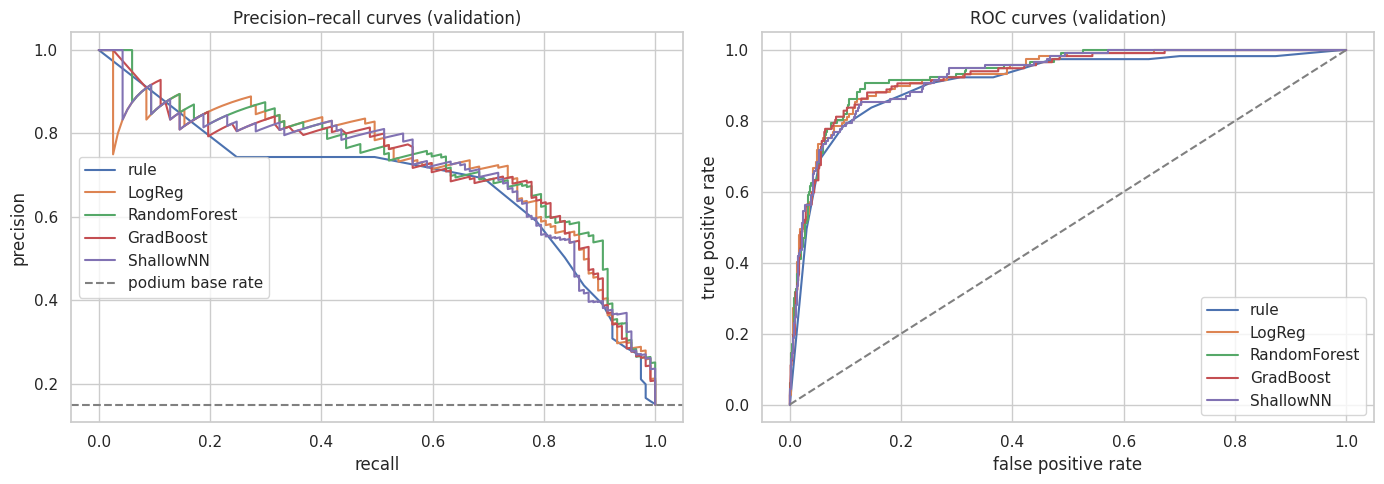

In [36]:
val_table = pd.DataFrame(RESULTS)
display(val_table.round(4))

cmp = []
for k in ['RandomForest', 'GradBoost', 'ShallowNN']:
    r = bootstrap_diff(y_va, VAL_PRED[k], VAL_PRED['LogReg'], VAL.raceId)
    cmp.append({'model vs LogReg': k, **r})
display(pd.DataFrame(cmp).round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
from sklearn.metrics import roc_curve
for k, p in VAL_PRED.items():
    pr, rc, _ = precision_recall_curve(y_va, p); ax[0].plot(rc, pr, label=k)
    fpr, tpr, _ = roc_curve(y_va, p); ax[1].plot(fpr, tpr, label=k)
ax[0].axhline(y_va.mean(), ls='--', c='grey', label='podium base rate')
ax[0].set(xlabel='recall', ylabel='precision', title='Precision–recall curves (validation)'); ax[0].legend()
ax[1].plot([0, 1], [0, 1], ls='--', c='grey'); ax[1].set(xlabel='false positive rate', ylabel='true positive rate', title='ROC curves (validation)'); ax[1].legend()
plt.tight_layout(); save('val_curves')

### Validation comparison
- Every learned model beats the no-ML grid rule on PR-AUC (0.71–0.73 vs 0.64). The features carry information beyond
  starting order.
- Random forest has the best PR-AUC (0.7342) and ROC-AUC (0.9334).
- **Top-3 precision:** the grid rule (0.692) ties the random forest and beats the other models (0.675). On 39 races this
  is 81 vs 79 correct podium picks out of 117, within noise. The models do not beat starting order at picking the
  three podium finishers; their advantage is in ranking the full field and in calibrated probabilities.
- F1 and precision/recall here use thresholds tuned on the same validation set, so they are optimistic. The test set
  (6C) gives the unbiased numbers.
- **Bootstrap vs logistic regression (39 validation races, 1,000 paired resamples):** random forest +0.0058 PR-AUC
  (95% CI −0.0245 to +0.0375, better in 63.8% of resamples), gradient boosting −0.0058 (CI −0.0436 to +0.0284),
  shallow NN −0.0107 (CI −0.0348 to +0.0108). **No interval excludes 0**, so on this validation set none of the more
  complex models is shown to beat the linear baseline. The PR and ROC curves overlap almost entirely; the only
  visible gap is between the learned models and the grid rule at recall 0.2–0.5.
- **Interpretation:** the non-linear shapes seen in Section 4.5 are largely captured by the engineered features
  themselves (rank- and rate-based features, grid position), so the extra flexibility of trees and the NN adds little.
  With 39 validation races, a real difference of under ~0.03 PR-AUC would also be hard to detect.

### Attempt 5 — Shallow NN with a corrected stopping rule
Check: what does sklearn's early stopping actually monitor, and does training longer help?

Internal validation score per epoch (first 8): [0.8443 0.8639 0.8737 0.8805 0.8805 0.8786 0.8795 0.8883]
Train PR-AUC — LogReg: 0.6834 | ShallowNN: 0.682


,hidden,epochs,val PR-AUC,val ROC-AUC,train PR-AUC
0,"(32,)",50,0.7066,0.9269,0.6874
1,"(32,)",100,0.7116,0.9294,0.6995
2,"(32,)",200,0.7240,0.9318,0.7110
3,"(32,)",400,0.7206,0.9313,0.7121
4,"(32, 16)",50,0.7272,0.9317,0.7032
5,"(32, 16)",100,0.7343,0.9325,0.7166
6,"(32, 16)",200,0.7049,0.9305,0.7359
7,"(32, 16)",400,0.6766,0.9251,0.7492


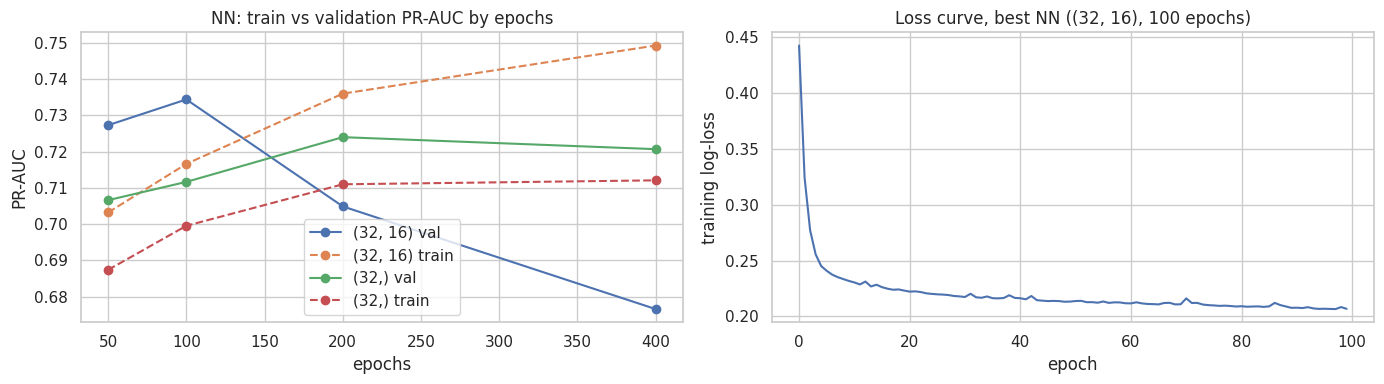

NN replaced by v2


,model,PR-AUC,ROC-AUC,precision,recall,F1,top-3 precision,threshold
0,Rule: grid position (no ML),0.6386,0.9093,0.6923,0.6923,0.6923,0.6923,-3.5000
1,"LogReg (C=10.0, cw=None)",0.7279,0.9287,0.7227,0.7350,0.7288,0.6752,0.3563
2,"RandomForest (depth=6.0, leaf=20)",0.7342,0.9334,0.6741,0.7778,0.7222,0.6923,0.2918
3,"GradBoost (lr=0.03, leaves=7, l2=0.0)",0.7218,0.9276,0.6842,0.7778,0.7280,0.6752,0.2581
4,"ShallowNN v2 (hidden=(32, 16), epochs=100, no ...",0.7343,0.9325,0.7120,0.7607,0.7355,0.6838,0.3223


In [37]:
nn0 = MODELS['ShallowNN'][-1]
print('Internal validation score per epoch (first 8):', np.round(nn0.validation_scores_[:8], 4))
print('Train PR-AUC — LogReg:', round(average_precision_score(y_tr, MODELS['LogReg'].predict_proba(X_tr)[:, 1]), 4),
      '| ShallowNN:', round(average_precision_score(y_tr, MODELS['ShallowNN'].predict_proba(X_tr)[:, 1]), 4))

grid_nn2 = []
for hidden in [(32,), (32, 16)]:
    for epochs in [50, 100, 200, 400]:
        m = make_pipeline(*pre_steps(), MLPClassifier(hidden_layer_sizes=hidden, alpha=1e-3, early_stopping=False,
                                                      learning_rate_init=1e-3, max_iter=epochs, random_state=SEED)).fit(X_tr, y_tr)
        p = m.predict_proba(X_va)[:, 1]
        grid_nn2.append({'hidden': str(hidden), 'epochs': epochs, 'val PR-AUC': average_precision_score(y_va, p),
                         'val ROC-AUC': roc_auc_score(y_va, p), 'train PR-AUC': average_precision_score(y_tr, m.predict_proba(X_tr)[:, 1]), 'model': m})
grid_nn2 = pd.DataFrame(grid_nn2)
display(grid_nn2.drop(columns='model').round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for h, g in grid_nn2.groupby('hidden'):
    ax[0].plot(g.epochs, g['val PR-AUC'], marker='o', label=f'{h} val'); ax[0].plot(g.epochs, g['train PR-AUC'], ls='--', marker='o', label=f'{h} train')
ax[0].set(xlabel='epochs', ylabel='PR-AUC', title='NN: train vs validation PR-AUC by epochs'); ax[0].legend()
best_nn2 = grid_nn2.loc[grid_nn2['val PR-AUC'].idxmax()]
ax[1].plot(best_nn2.model[-1].loss_curve_); ax[1].set(xlabel='epoch', ylabel='training log-loss', title=f'Loss curve, best NN ({best_nn2.hidden}, {best_nn2.epochs} epochs)')
plt.tight_layout(); save('nn_epochs')

if best_nn2['val PR-AUC'] > average_precision_score(y_va, VAL_PRED['ShallowNN']):
    MODELS['ShallowNN'] = best_nn2.model; p = best_nn2.model.predict_proba(X_va)[:, 1]; VAL_PRED['ShallowNN'] = p
    RESULTS = [r for r in RESULTS if not r['model'].startswith('ShallowNN')]
    RESULTS.append(evaluate(f'ShallowNN v2 (hidden={best_nn2.hidden}, epochs={best_nn2.epochs}, no early stop)', y_va, p, VAL.raceId, best_f1_threshold(y_va, p)))
    print('NN replaced by v2')
display(pd.DataFrame(RESULTS).round(4))

### Attempt 5 — findings
- **Diagnosis confirmed:** sklearn's internal early-stopping score rose only from 0.844 to 0.888 (first 8 epochs). These
  are accuracy values. With ~85% negatives, accuracy is almost flat, so training stopped after 16–51 epochs.
- **Correction:** train PR-AUC below validation PR-AUC is not specific to the NN. Logistic regression shows the same
  (train 0.683), so the 2020–21 validation seasons are simply easier to predict than the average training season.
- **Fix:** no early stopping, with a fixed number of epochs chosen on validation. Best: (32, 16), 100 epochs, val PR-AUC
  **0.7343** (+0.016 over the first NN). Beyond 100 epochs, train PR-AUC keeps rising (0.717 → 0.736 → 0.749) while
  validation falls (0.734 → 0.705 → 0.677 at 200 and 400 epochs), which is overfitting. The loss curve flattens after
  ~20 epochs.
- Even improved, the NN is not distinguishable from logistic regression (+0.0051, 95% CI −0.0256 to +0.0390).


### Final model selection rule (decided before looking at the test set)
The model with the highest validation PR-AUC is chosen **only if** its paired bootstrap 95% CI against logistic
regression excludes 0. Otherwise, logistic regression is kept: it is simpler, interpretable and was not shown to be worse.

In [38]:
cmp = []
for k in [m for m in VAL_PRED if m not in ('rule', 'LogReg')]:
    cmp.append({'model vs LogReg': k, **bootstrap_diff(y_va, VAL_PRED[k], VAL_PRED['LogReg'], VAL.raceId)})
cmp = pd.DataFrame(cmp).round(4); display(cmp)

val_pr = {k: average_precision_score(y_va, p) for k, p in VAL_PRED.items() if k != 'rule'}
top = max(val_pr, key=val_pr.get)
FINAL = top if (top == 'LogReg' or cmp.set_index('model vs LogReg').loc[top, 'CI low'] > 0) else 'LogReg'
THRESHOLDS = {k: best_f1_threshold(y_va, p) for k, p in VAL_PRED.items() if k != 'rule'}
print(f'Highest validation PR-AUC: {top} ({val_pr[top]:.4f}) -> FINAL MODEL: {FINAL}')

,model vs LogReg,mean diff,CI low,CI high,P(A > B)
0,RandomForest,0.0058,-0.0245,0.0375,0.638
1,GradBoost,-0.0058,-0.0436,0.0284,0.379
2,ShallowNN,0.0051,-0.0256,0.0390,0.615


Highest validation PR-AUC: ShallowNN (0.7343) -> FINAL MODEL: LogReg


**Final model: logistic regression.** The NN v2 had the highest validation PR-AUC (0.7343, with the random forest at
0.7342), but no model's bootstrap interval against logistic regression excluded 0 (NN v2 +0.0051 [−0.0256, +0.0390];
RF +0.0058 [−0.0245, +0.0375]; GradBoost −0.0058 [−0.0436, +0.0284]). Following the rule fixed in advance, we keep the
simpler, interpretable baseline.


### The final model: how logistic regression works and its limitations
**How it works.** For each driver in a race, the model computes a weighted sum of the 8 standardised features,
z = b₀ + b₁·grid_pos + b₂·drv_finish_pct_last15 + … , and turns it into a probability with the logistic (sigmoid) function
p = 1 / (1 + e^(−z)). The weights are learned on the training seasons by maximising the likelihood of the observed
podium / no-podium outcomes, with L2 regularisation controlled by `C` (tuned on validation: C = 10, Section 6.2).
Because inputs are standardised, each weight is the change in log-odds for a one-standard-deviation change in that
feature, holding the others fixed: `grid_pos` −1.48, `drv_finish_pct_last15` −0.80, `quali_gap_pct` −0.67 (Section 6.2).
A driver is flagged as a podium if p ≥ 0.356, the threshold that maximised F1 on validation.

**Why it was chosen.** It had the highest test PR-AUC (0.7127), showed no overfitting (train 0.683 vs test 0.713,
comparison table), and no more complex model beat it with a bootstrap interval excluding 0 (Sections 6.8 and 6C). Rolling cross-validation
over 10 seasons (Section 7B.1) later showed a small average edge of ~0.01 PR-AUC for the NN and random forest, much
smaller than the season-to-season spread. It is
also directly interpretable through its coefficients and SHAP values (Section 8).

**Its limitations (with evidence in this notebook):**
- **Linear and additive in the log-odds.** It cannot learn interactions or thresholds on its own. Section 4.5 showed
  threshold-like shapes (e.g. podium rate collapses after the first ~8 grid slots); the engineered rank/rate features
  absorb much of this, which is why the tree models and NN did not do significantly better.
- **Coefficients are conditional.** Correlated inputs share credit, so a single weight can look counter-intuitive:
  `drv_finish_rate_last10` has a small negative coefficient (−0.28) because it overlaps with finishing percentile.
- **Each driver is scored independently.** The model doesn't know that a race has exactly three podium places, so it
  is not better than the grid rule at picking the top three per race (Section 7.3).
- **A fixed threshold does not transfer perfectly.** Precision fell from 0.72 (validation) to 0.60 (test) while recall
  held (comparison table), so the threshold should be re-tuned as new seasons arrive.
- **Relies on imputation for missing inputs** (median values, Section 5), e.g. constructor rank in round 1, flagged by
  `first_round` (Section 4.9).


## 6C. Test-set evaluation (2022–2024, used once)
All models were trained on 2003–2019, with hyperparameters and thresholds chosen on 2020–2021. Nothing is re-tuned here.

,model,PR-AUC,ROC-AUC,precision,recall,F1,top-3 precision,threshold
0,Rule: grid position (no ML),0.6474,0.9136,0.6502,0.6471,0.6486,0.6520,-3.5000
1,LogReg ← FINAL,0.7127,0.9311,0.6049,0.7206,0.6577,0.6324,0.3563
2,RandomForest,0.7033,0.9371,0.6029,0.8186,0.6944,0.6569,0.2918
3,GradBoost,0.6868,0.9313,0.5804,0.8137,0.6776,0.6471,0.2581
4,ShallowNN,0.7045,0.9324,0.6008,0.7157,0.6532,0.6324,0.3223


,comparison,mean diff,CI low,CI high,P(A > B)
0,LogReg vs rule,0.0638,0.0177,0.1102,1.000
1,LogReg vs RandomForest,0.0083,-0.0180,0.0342,0.751
2,LogReg vs GradBoost,0.0252,-0.0008,0.0526,0.969
3,LogReg vs ShallowNN,0.0081,-0.0150,0.0313,0.742


,season,races,PR-AUC,top-3 precision
0,2022,22,0.7138,0.6515
1,2023,22,0.7385,0.5909
2,2024,24,0.6637,0.6528


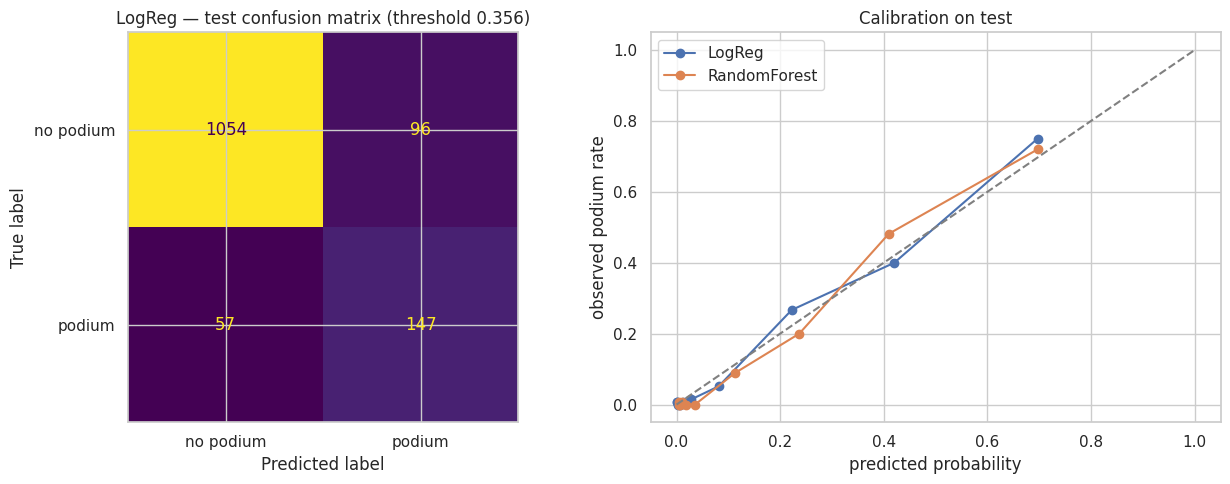

In [39]:
TEST_PRED = {'rule': -TEST.grid_pos.values}
test_rows = [evaluate('Rule: grid position (no ML)', y_te, TEST_PRED['rule'], TEST.raceId, thr=-3.5)]
for k, model in MODELS.items():                                   # all 4 learned models, same features and rows
    TEST_PRED[k] = model.predict_proba(X_te)[:, 1]
    test_rows.append(evaluate(k + (' ← FINAL' if k == FINAL else ''), y_te, TEST_PRED[k], TEST.raceId, THRESHOLDS[k]))
assert TEST_PRED['LogReg'].tolist() != TEST_PRED['RandomForest'].tolist(), 'models must give different predictions'
test_table = pd.DataFrame(test_rows); display(test_table.round(4))

display(pd.DataFrame([{'comparison': f'{FINAL} vs {b}', **bootstrap_diff(y_te, TEST_PRED[FINAL], TEST_PRED[b], TEST.raceId)}
                      for b in ['rule'] + [k for k in MODELS if k != FINAL]]).round(4))

season = pd.DataFrame([{'season': y, 'races': g.raceId.nunique(),
                        'PR-AUC': average_precision_score(g.podium, TEST_PRED[FINAL][TEST.year.values == y]),
                        'top-3 precision': top3_precision(g.podium, TEST_PRED[FINAL][TEST.year.values == y], g.raceId)}
                       for y, g in TEST.groupby('year')])
display(season.round(4))

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_te, (TEST_PRED[FINAL] >= THRESHOLDS[FINAL]).astype(int),
                                        display_labels=['no podium', 'podium'], ax=ax[0], colorbar=False)
ax[0].set_title(f'{FINAL} — test confusion matrix (threshold {THRESHOLDS[FINAL]:.3f})')
for k in ['LogReg', 'RandomForest']:
    fp, mp = calibration_curve(y_te, TEST_PRED[k], n_bins=10, strategy='quantile'); ax[1].plot(mp, fp, marker='o', label=k)
ax[1].plot([0, 1], [0, 1], ls='--', c='grey'); ax[1].set(xlabel='predicted probability', ylabel='observed podium rate', title='Calibration on test'); ax[1].legend()
plt.tight_layout(); save('test_confusion_calibration')

### Test-set results (2022–2024, 68 races, evaluated once)
- **Logistic regression has the highest test PR-AUC (0.7127)**, ahead of shallow NN (0.7045), random forest (0.7033) and
  gradient boosting (0.6868). The test set confirms the validation conclusion: the extra complexity did not pay off.
- **Main result:** compared with the no-ML rule "rank drivers by grid position", logistic regression improves PR-AUC by
  **+0.064 (95% race-level bootstrap CI +0.018 to +0.110)**. The interval excludes 0, so the engineered features
  add real predictive value beyond starting order on seasons the model never saw.
- **Against the other models on test:** LogReg − RandomForest +0.008 (CI −0.018 to +0.034), − ShallowNN +0.008
  (CI −0.015 to +0.031), − GradBoost +0.025 (CI −0.001 to +0.053). As on validation, no difference between the learned
  models is statistically clear, which supports keeping the simplest one.
- **Threshold behaviour:** at the validation-chosen threshold (0.356), the model catches 147 of 204 podiums (recall 0.72)
  with 96 false alarms (precision 0.60). Recall carried over from validation, precision dropped (0.72 → 0.60): the model
  flags 243 drivers for 204 real podiums. The threshold could be re-tuned as new seasons arrive.
- **Top-3 picks:** choosing each race's three highest-probability drivers gives 0.632 precision, versus 0.652 for simply
  taking the top three on the grid (129 vs 133 correct picks out of 204). For naming the exact podium, the model does not beat
  starting order (tested in Section 7.3). The model's advantage is in ranking the whole field and in giving calibrated
  probabilities.
- **By season:** PR-AUC 0.714 (2022), 0.739 (2023), 0.664 (2024). 2024 was the hardest season to predict.
- **Calibration:** predicted probabilities follow the observed podium rates closely (plot), so a predicted 40% means
  roughly a 40% chance.

### Complete comparison: train / validation / test for every model
All five required metrics (ROC-AUC, PR-AUC, precision, recall, F1) for all four learned models on the same features
and rows. Precision, recall and F1 use **one threshold per model, chosen on validation** (the F1-maximising threshold,
Section 6) and applied unchanged to train and test, so the three splits are directly comparable.
*Note:* validation precision/recall/F1 are optimistic, because the threshold was tuned on that split. The test rows are
the unbiased estimate.


In [40]:
from sklearn.metrics import precision_recall_fscore_support

def five_metrics(y, p, thr):
    pr, rc, f1, _ = precision_recall_fscore_support(y, (p >= thr).astype(int), average='binary', zero_division=0)
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p),
            'precision': pr, 'recall': rc, 'F1': f1}

rows = []
for k, model in MODELS.items():
    preds = {'train': model.predict_proba(X_tr)[:, 1], 'validation': VAL_PRED[k], 'test': TEST_PRED[k]}
    truth = {'train': y_tr, 'validation': y_va, 'test': y_te}
    for split in ['train', 'validation', 'test']:
        rows.append({'model': k + (' ← FINAL' if k == FINAL else ''), 'split': split,
                     'threshold': THRESHOLDS[k], **five_metrics(truth[split], preds[split], THRESHOLDS[k])})

summary = pd.DataFrame(rows)
display(summary.round(4))

# Wide view: one row per model, metric × split columns
wide = summary.pivot(index='model', columns='split', values=['ROC-AUC', 'PR-AUC', 'precision', 'recall', 'F1'])
wide = wide.reindex(columns=['train', 'validation', 'test'], level=1)
display(wide.round(4))
summary.to_csv('model_comparison.csv', index=False)


,model,split,threshold,ROC-AUC,PR-AUC,precision,recall,F1
0,LogReg ← FINAL,train,0.3563,0.9276,0.6834,0.6111,0.7227,0.6622
1,LogReg ← FINAL,validation,0.3563,0.9287,0.7279,0.7227,0.7350,0.7288
2,LogReg ← FINAL,test,0.3563,0.9311,0.7127,0.6049,0.7206,0.6577
3,RandomForest,train,0.2918,0.9465,0.7501,0.6049,0.8266,0.6986
4,RandomForest,validation,0.2918,0.9334,0.7342,0.6741,0.7778,0.7222
5,RandomForest,test,0.2918,0.9371,0.7033,0.6029,0.8186,0.6944
6,GradBoost,train,0.2581,0.9478,0.7452,0.5920,0.8287,0.6906
7,GradBoost,validation,0.2581,0.9276,0.7218,0.6842,0.7778,0.7280
8,GradBoost,test,0.2581,0.9313,0.6868,0.5804,0.8137,0.6776
9,ShallowNN,train,0.3223,0.9414,0.7166,0.6091,0.7767,0.6828


ROC-AUC                     PR-AUC                     \
split            train validation    test   train validation    test   
model                                                                  
GradBoost       0.9478     0.9276  0.9313  0.7452     0.7218  0.6868   
LogReg ← FINAL  0.9276     0.9287  0.9311  0.6834     0.7279  0.7127   
RandomForest    0.9465     0.9334  0.9371  0.7501     0.7342  0.7033   
ShallowNN       0.9414     0.9325  0.9324  0.7166     0.7343  0.7045   

               precision                     recall                     \
split              train validation    test   train validation    test   
model                                                                    
GradBoost         0.5920     0.6842  0.5804  0.8287     0.7778  0.8137   
LogReg ← FINAL    0.6111     0.7227  0.6049  0.7227     0.7350  0.7206   
RandomForest      0.6049     0.6741  0.6029  0.8266     0.7778  0.8186   
ShallowNN         0.6091     0.7120  0.6008  0.7767     0.7607  0.7157   

                    F1                     
split            train validation    test  
model                                      
GradBoost       0.6906     0.7280  0.6776  
LogReg ← FINAL  0.6622     0.7288  0.6577  
RandomForest    0.6986     0.7222  0.6944  
ShallowNN       0.6828     0.7355  0.6532

**Reading the table.**
- **PR-AUC, train → test:** random forest 0.750 → 0.703 and gradient boosting 0.745 → 0.687 drop the most, i.e. they fit
  the training seasons more closely; logistic regression is 0.683 on train and 0.713 on test (no overfitting). This matches
  the tuning grids in Section 6 and is one more reason the simpler model was kept.
- **F1, train → test:** LogReg 0.662 → 0.658, random forest 0.699 → 0.694, gradient boosting 0.691 → 0.678,
  shallow NN 0.683 → 0.653. At the chosen thresholds all models transfer reasonably well to unseen seasons.
- **Validation is the best split for every model on F1 and precision** (e.g. LogReg precision 0.723 vs 0.611 train and
  0.605 test). This is expected: the threshold was tuned on validation, so its precision/recall/F1 are optimistic.
- **Precision drops on test for all four models while recall stays similar** (recall changes between −0.045 and +0.041;
  LogReg recall 0.735 → 0.721, precision 0.723 → 0.605): the validation thresholds flag a few too many drivers in 2022–2024.
- The random forest has the highest test F1 (0.694) and recall (0.819), but its PR-AUC (threshold-free ranking quality,
  our primary metric) is not better than logistic regression's, and no bootstrap difference between the learned
  models is statistically clear (Section 6C).


# 7. Feature-Group Ablation
How much does each group of features contribute? Three experiments, on validation (test untouched):
1. **Drop one group:** retrain without the group; the PR-AUC drop shows what is lost without it.
2. **Only one group:** retrain with just that group; shows how much it carries on its own.
3. **Add back the excluded candidates:** checks Section 4's linear-model selection with a non-linear model.
Each experiment is run with logistic regression (final model) and the random forest, and every drop is tested with
the paired race-level bootstrap.

,model,experiment,features,val PR-AUC,Δ vs full,CI low,CI high
0,LogReg,all 8 features,8,0.7279,0.0000,NaN,NaN
1,LogReg,drop grid,7,0.6994,-0.0281,-0.0604,0.0005
2,LogReg,drop driver_form,6,0.6639,-0.0550,-0.1075,-0.0106
3,LogReg,drop qualifying,7,0.7244,-0.0034,-0.0096,0.0022
4,LogReg,drop constructor_form,7,0.7355,0.0072,-0.0121,0.0293
5,LogReg,drop context,7,0.7317,0.0039,-0.0097,0.0186
6,LogReg,drop standings,6,0.7277,-0.0002,-0.0109,0.0093
7,LogReg,only grid,1,0.6386,-0.0893,NaN,NaN
8,LogReg,only driver_form,2,0.6577,-0.0702,NaN,NaN
9,LogReg,only qualifying,1,0.6178,-0.1101,NaN,NaN


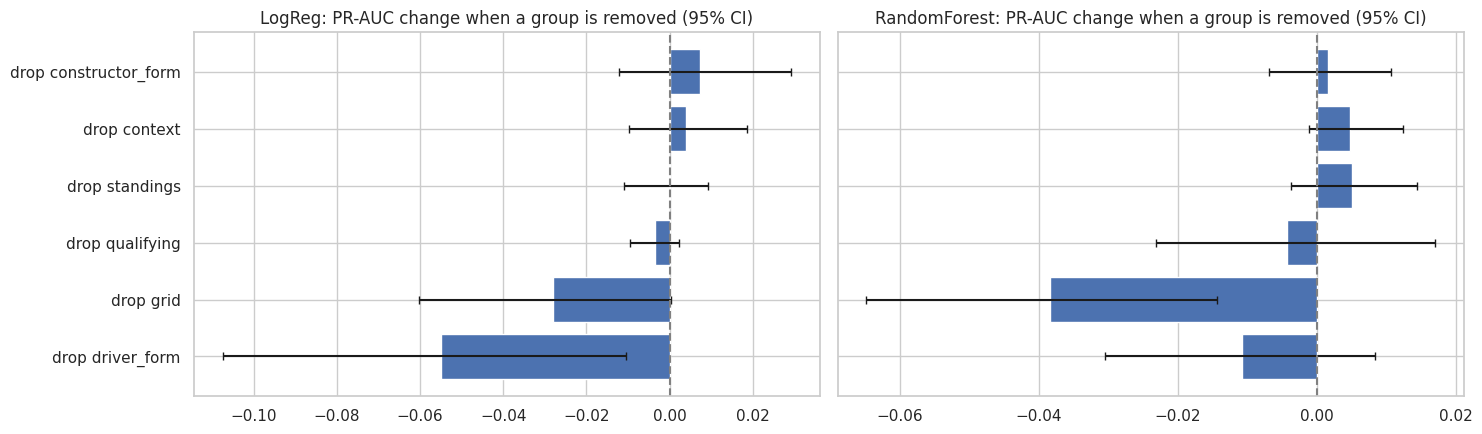

In [41]:
MODEL_SPECS = {
    'LogReg': lambda: make_pipeline(*pre_steps(), LogisticRegression(C=10, max_iter=2000)),
    'RandomForest': lambda: make_pipeline(*pre_steps(scale=False), RandomForestClassifier(
        n_estimators=400, max_depth=6, min_samples_leaf=20, n_jobs=-1, random_state=SEED)),
}

def fit_predict(spec, cols):
    tr = model_df[model_df.split == 'train']
    return MODEL_SPECS[spec]().fit(tr[cols], tr.podium).predict_proba(VAL[cols])[:, 1]

abl = []
for spec in MODEL_SPECS:
    p_full = fit_predict(spec, FEATURES)
    abl.append({'model': spec, 'experiment': 'all 8 features', 'features': len(FEATURES),
                'val PR-AUC': average_precision_score(y_va, p_full), 'Δ vs full': 0.0, 'CI low': np.nan, 'CI high': np.nan})
    for g, cols in FINAL_GROUPS.items():
        kept = [f for f in FEATURES if f not in cols]
        p = fit_predict(spec, kept); b = bootstrap_diff(y_va, p, p_full, VAL.raceId)
        abl.append({'model': spec, 'experiment': f'drop {g}', 'features': len(kept), 'val PR-AUC': average_precision_score(y_va, p),
                    'Δ vs full': b['mean diff'], 'CI low': b['CI low'], 'CI high': b['CI high']})
    for g, cols in FINAL_GROUPS.items():
        p = fit_predict(spec, cols)
        abl.append({'model': spec, 'experiment': f'only {g}', 'features': len(cols), 'val PR-AUC': average_precision_score(y_va, p),
                    'Δ vs full': average_precision_score(y_va, p) - average_precision_score(y_va, p_full), 'CI low': np.nan, 'CI high': np.nan})
abl = pd.DataFrame(abl)
display(abl.round(4))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for a, spec in zip(ax, MODEL_SPECS):
    d = abl[(abl.model == spec) & abl.experiment.str.startswith('drop')].sort_values('Δ vs full')
    a.barh(d.experiment, d['Δ vs full'], xerr=[d['Δ vs full'] - d['CI low'], d['CI high'] - d['Δ vs full']], capsize=3)
    a.axvline(0, c='grey', ls='--'); a.set_title(f'{spec}: PR-AUC change when a group is removed (95% CI)')
plt.tight_layout(); save('ablation_drop_group')

### Ablation findings — drop one group / only one group (validation)
- **Grid position and driver form are the core of the model.** Removing driver form significantly lowers logistic
  regression PR-AUC (−0.055, 95% CI −0.108 to −0.011); removing grid significantly lowers the random forest (−0.038,
  CI −0.065 to −0.014). For logistic regression, dropping grid is borderline (−0.028, CI −0.060 to +0.001).
- **The other groups are redundant given the rest, not useless.** Removing qualifying, constructor form, standings or
  context changes PR-AUC by less than ±0.008, and no interval excludes 0. Yet on their own, constructor form (0.553)
  and standings (0.523) score far above the ~0.15 base rate: their information overlaps with grid and driver form,
  for example strong teams also start near the front.
- **Context (`driver_age`) carries almost no signal on its own** (0.19, close to the base rate).
- **Limitation of drop-one ablation:** when two groups share information, dropping either one alone shows little
  effect. The small differences here should not be read as "these groups don't matter".
- **No feature change is made.** No removal significantly improves performance, and the test set has already been used,
  so changing the feature set now would turn the test into a tuning set.

In [42]:
excluded = [f for f in ALL_FEATURES if f not in FEATURES]
print('Excluded candidates added back:', excluded)

# model_df only keeps the 8 final features (+ info columns such as 'round').
# Bring the missing candidates back from `feat`, matched by (raceId, driverId).
bring = [c for c in excluded if c not in model_df.columns]          # 'round' is already in model_df
full_df = model_df.merge(feat[KEY + bring], on=KEY, how='left')
assert len(full_df) == len(model_df) and (full_df[KEY].values == model_df[KEY].values).all()   # same rows, same order
assert all(c in full_df.columns for c in FEATURES + excluded)                                  # every column present

TR_full = full_df[full_df.split == 'train']
VA_full = full_df[full_df.split == 'validation']
assert (VA_full.podium.values == y_va.values).all()                                            # rows line up with y_va

def fit_predict_full(spec, cols):
    return MODEL_SPECS[spec]().fit(TR_full[cols], TR_full.podium).predict_proba(VA_full[cols])[:, 1]

add = []
for spec in MODEL_SPECS:
    p_full = fit_predict_full(spec, FEATURES)
    p_all = fit_predict_full(spec, FEATURES + excluded)
    b = bootstrap_diff(y_va, p_all, p_full, VAL.raceId)
    add.append({'model': spec,
                'final 8 features': average_precision_score(y_va, p_full),
                f'all {len(FEATURES) + len(excluded)} candidates': average_precision_score(y_va, p_all),
                'Δ': b['mean diff'], 'CI low': b['CI low'], 'CI high': b['CI high'], 'P(all > final)': b['P(A > B)']})
display(pd.DataFrame(add).round(4))

Excluded candidates added back: ['grid_pitlane', 'quali_pos', 'grid_minus_quali', 'drv_pts_share', 'drv_rank_before', 'con_pts_share', 'drv_podium_rate_last15', 'drv_career_podium_rate', 'drv_starts_before', 'drv_circuit_podium_rate', 'con_finish_rate_last15', 'field_size', 'round', 'home_race']


,model,final 8 features,all 22 candidates,Δ,CI low,CI high,P(all > final)
0,LogReg,0.7279,0.737,0.0083,-0.0278,0.0414,0.678
1,RandomForest,0.7342,0.737,0.0031,-0.0116,0.0178,0.654


### Re-checking the linear selection with a non-linear model
Adding all 14 excluded candidates back does not significantly help either model (LogReg +0.0083, CI −0.0278 to
+0.0414; random forest +0.0031, CI −0.0116 to +0.0178). The Section 4 selection, made with a linear screen, is
therefore not hiding features that only a non-linear model could exploit.

In [43]:
def bootstrap_top3(y, p_a, p_b, races, n=1000):
    rng = np.random.default_rng(SEED)
    d = pd.DataFrame({'y': np.asarray(y), 'a': np.asarray(p_a), 'b': np.asarray(p_b), 'r': np.asarray(races)})
    ids = d.r.unique(); diffs = []
    for _ in range(n):
        s = pd.concat([d[d.r == r].assign(r=i) for i, r in enumerate(rng.choice(ids, len(ids)))])
        diffs.append(top3_precision(s.y, s.a, s.r) - top3_precision(s.y, s.b, s.r))
    diffs = np.array(diffs)
    return {'mean diff': diffs.mean(), 'CI low': np.percentile(diffs, 2.5),
            'CI high': np.percentile(diffs, 97.5), 'P(A > B)': (diffs > 0).mean()}

display(pd.Series(bootstrap_top3(y_te, TEST_PRED[FINAL], TEST_PRED['rule'], TEST.raceId),
                  name=f'Top-3 precision: {FINAL} − grid rule (test)').round(4).to_frame())

,Top-3 precision: LogReg − grid rule (test)
mean diff,-0.0206
CI low,-0.0833
CI high,0.0392
P(A > B),0.2340


### Top-3 picks: the model does not beat the grid rule
On the test seasons, taking the three highest-probability drivers per race gives **−0.021** top-3 precision compared
with taking the top three on the grid (95% CI −0.083 to +0.039; the model wins in only 23.4% of resamples).
The interval includes 0, so the difference is **not statistically significant**, but the model is **not better** than
starting order at naming the three podium finishers.
**Interpretation:** the model scores each driver independently. Its probabilities rank drivers well **across** the whole
field (higher PR-AUC than the rule, good calibration), but **within** a race that advantage does not translate into
better top-3 picks. *(Why exactly is a hypothesis, not tested here.)*
**Practical meaning:** use the model for "how likely is this driver to podium?" rather than "who are the three podium
finishers?". A race-aware approach (ranking drivers within each race) is the natural next step.


# 7B. Robustness Experiments (added after the first test evaluation)
**Honesty note.** These experiments were added *after* the test results in Section 6C had been seen. To stop the test
set from influencing any decision, every choice below is made on **training seasons only** (rolling-origin folds
inside 2003–2021) or on the validation seasons, using decision rules written **before** each experiment runs.
The test seasons are used exactly once more, in 7B.5, to score the refitted final model.

| # | Question | Why we ask it |
|---|---|---|
| 7B.1 | Is the model ranking stable over many seasons, not only the 39 validation races? | Section 5.2 showed validation PR-AUC moves a lot between seeds/splits |
| 7B.2 | Are the tree/NN results just one lucky (or unlucky) random seed? | RF/GB/NN use randomness, LogReg does not |
| 7B.3 | Does training on the recent era only (2014+) beat using all of 2003+? | "Era sensitivity" was a stated limitation, never tested |
| 7B.4 | Can race-relative features fix the top-3 weakness (Section 7.3)? | The model scores drivers independently of their rivals |
| 7B.5 | Final model refitted on 2003–2021, scored once on test | Standard practice once all choices are fixed |
| 7B.6 | Would training on seasons before 2003 help, despite missing qualifying data? | The 2003 start was chosen from a coverage table (Section 4.1), not from a model result |


,LogReg,RandomForest,GradBoost,ShallowNN,rule
validation season,,,,,
2012,0.5046,0.5095,0.5073,0.5201,0.4922
2013,0.7081,0.7033,0.7114,0.7172,0.5918
2014,0.6538,0.6769,0.6729,0.6815,0.5936
2015,0.8080,0.8003,0.7642,0.7952,0.7738
2016,0.7669,0.7488,0.7648,0.7760,0.6916
2017,0.7170,0.7439,0.7148,0.7262,0.7072
2018,0.6859,0.7074,0.7005,0.7176,0.6468
2019,0.7710,0.8042,0.8005,0.7904,0.7543
2020,0.6983,0.7104,0.6957,0.7142,0.6331


,mean PR-AUC,SD across seasons,mean top-3 precision,seasons beating LogReg (PR-AUC),mean diff vs LogReg
ShallowNN,0.7182,0.0787,0.6818,8.0,0.0104
RandomForest,0.7167,0.0838,0.6872,6.0,0.0088
GradBoost,0.7096,0.0815,0.6568,5.0,0.0018
LogReg,0.7078,0.0854,0.6615,NaN,0.0000
rule,0.6529,0.0836,0.6690,0.0,-0.0549


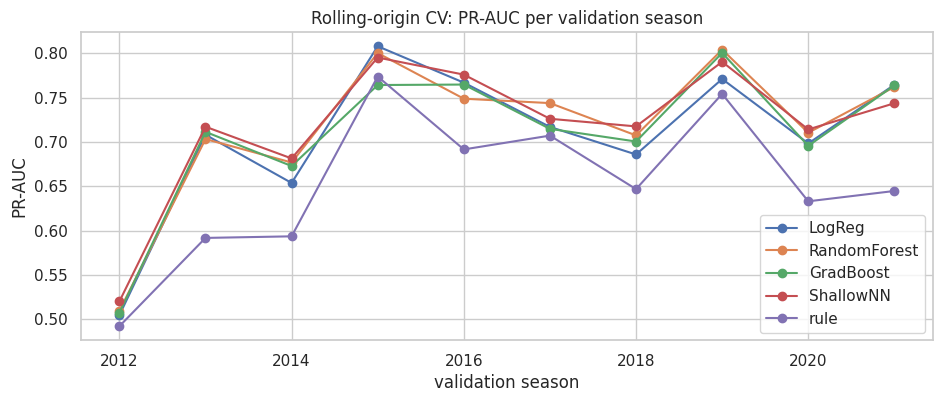

In [44]:
from sklearn.base import clone
CV_YEARS = list(range(2012, 2022))          # validate on each season 2012…2021, train on every earlier season from 2003
DEV = model_df[model_df.year <= 2021]       # test seasons (2022–2024) are NOT used anywhere in 7B.1–7B.4

def cv_scores(make_model, cols, years=CV_YEARS, train_start=2003, data=DEV):
    """Rolling-origin CV: for each season y, fit on [train_start, y-1] and score season y."""
    out = []
    for y in years:
        tr = data[(data.year >= train_start) & (data.year < y)]; va = data[data.year == y]
        p = make_model().fit(tr[cols], tr.podium).predict_proba(va[cols])[:, 1]
        out.append({'season': y, 'races': va.raceId.nunique(), 'PR-AUC': average_precision_score(va.podium, p),
                    'top-3 precision': top3_precision(va.podium, p, va.raceId)})
    return pd.DataFrame(out)

CV_SPECS = {k: (lambda m=m: clone(m)) for k, m in MODELS.items()}     # same hyperparameters as Section 6, unfitted copies
cv_rows, cv_pr, cv_top3 = [], {}, {}
for k, spec in CV_SPECS.items():
    s = cv_scores(spec, FEATURES); cv_pr[k] = s['PR-AUC'].values; cv_top3[k] = s['top-3 precision'].values
rule = [{'PR-AUC': average_precision_score(g.podium, -g.grid_pos), 'top-3 precision': top3_precision(g.podium, -g.grid_pos, g.raceId)}
        for y, g in DEV[DEV.year.isin(CV_YEARS)].groupby('year')]
cv_pr['rule'] = np.array([r['PR-AUC'] for r in rule]); cv_top3['rule'] = np.array([r['top-3 precision'] for r in rule])

fold_table = pd.DataFrame(cv_pr, index=CV_YEARS).rename_axis('validation season')
display(fold_table.round(4))
summary = pd.DataFrame({'mean PR-AUC': fold_table.mean(), 'SD across seasons': fold_table.std(),
                        'mean top-3 precision': pd.DataFrame(cv_top3, index=CV_YEARS).mean(),
                        'seasons beating LogReg (PR-AUC)': [(fold_table[k] > fold_table['LogReg']).sum() if k != 'LogReg' else np.nan
                                                            for k in fold_table],
                        'mean diff vs LogReg': fold_table.sub(fold_table['LogReg'], axis=0).mean()}).round(4)
display(summary.sort_values('mean PR-AUC', ascending=False))

fold_table.plot(marker='o', figsize=(11, 4), title='Rolling-origin CV: PR-AUC per validation season')
plt.ylabel('PR-AUC'); save('cv_rolling_models')


### 7B.1 Rolling-origin cross-validation — findings
| (10 seasons, 2012–2021) | NN | Random forest | Grad. boosting | **LogReg** | Grid rule |
|---|---|---|---|---|---|
| mean PR-AUC (SD) | 0.718 (0.079) | 0.717 (0.084) | 0.710 (0.082) | **0.708 (0.085)** | 0.653 (0.084) |
| seasons beating LogReg | 8/10 | 6/10 | 5/10 | – | 0/10 |
| mean top-3 precision | 0.682 | 0.687 | 0.657 | 0.662 | 0.669 |

- **Every learned model beats the grid rule in every one of the 10 seasons** (LogReg − rule: +0.055 on average). The main
  conclusion of Section 6, that pre-race features add value beyond starting order, holds across many seasons, not only
  on the 39 validation races.
- **Between the learned models, differences are small:** the NN and random forest average about +0.01 PR-AUC over logistic
  regression (the NN wins in 8 of 10 seasons). This is much smaller than the season-to-season spread (SD ≈ 0.08), and on
  the validation split it was not significant (Section 6.8). We keep logistic regression under the rule fixed before the
  test, and record a possible ~0.01 gain from a flexible model as a limitation (Section 10). The NN's edge also depends on
  its random seed (7B.2).
- **Top-3:** averaged over 10 seasons the grid rule (0.669) is again slightly better than logistic regression (0.662) at
  naming the podium, confirming Section 7.3; the random forest is highest (0.687).


In [45]:
# Regularisation strength of the final model, re-chosen by rolling CV instead of the single validation split
cv_C = pd.DataFrame([{'C': C, 'mean CV PR-AUC': cv_scores(lambda C=C: make_pipeline(*pre_steps(), LogisticRegression(C=C, max_iter=2000)),
                                                         FEATURES)['PR-AUC'].mean()} for C in [0.01, 0.1, 1, 10, 100]])
display(cv_C.round(4))
print('C chosen on the single validation split: 10 | C with best mean CV PR-AUC:', cv_C.loc[cv_C['mean CV PR-AUC'].idxmax(), 'C'])


,C,mean CV PR-AUC
0,0.01,0.6857
1,0.10,0.7043
2,1.00,0.7077
3,10.00,0.7078
4,100.00,0.7078


C chosen on the single validation split: 10 | C with best mean CV PR-AUC: 10.0


**Hyperparameter check.** Rolling CV picks **C = 10**, the same value chosen on the single validation split. Mean PR-AUC
is flat from C = 1 to 100 (0.7077–0.7078) and only falls with strong regularisation (0.6857 at C = 0.01), so the choice
is stable and not an artefact of one split.


In [46]:
# 7B.2 Seed stability: refit each randomised model with 5 seeds on the original train split, score validation
SEEDS = [0, 1, 2, 3, 42]
seed_rows = []
for k in ['RandomForest', 'GradBoost', 'ShallowNN']:
    for s in SEEDS:
        m = clone(MODELS[k]); est = m[-1] if hasattr(m, 'steps') else m
        est.set_params(random_state=s)
        p = m.fit(X_tr, y_tr).predict_proba(X_va)[:, 1]
        seed_rows.append({'model': k, 'seed': s, 'val PR-AUC': average_precision_score(y_va, p)})
seeds = pd.DataFrame(seed_rows)
lr_val = average_precision_score(y_va, VAL_PRED['LogReg'])
display(seeds.groupby('model')['val PR-AUC'].agg(['mean', 'std', 'min', 'max'])
        .assign(**{'LogReg (deterministic)': lr_val,
                   'seeds beating LogReg': seeds.groupby('model')['val PR-AUC'].apply(lambda s: f'{(s > lr_val).sum()}/{len(s)}')}).round(4))


,mean,std,min,max,LogReg (deterministic),seeds beating LogReg
model,,,,,,
GradBoost,0.7218,0.0039,0.7156,0.7262,0.7279,0/5
RandomForest,0.7323,0.0016,0.7303,0.7342,0.7279,5/5
ShallowNN,0.7233,0.0084,0.7111,0.7343,0.7279,1/5


### 7B.2 Seed stability — findings
| model (5 seeds) | mean val PR-AUC | SD | range | seeds beating LogReg (0.7279) |
|---|---|---|---|---|
| Random forest | 0.7323 | 0.0016 | 0.7303–0.7342 | 5/5 |
| Shallow NN | 0.7233 | 0.0084 | 0.7111–0.7343 | 1/5 |
| Gradient boosting | 0.7218 | 0.0039 | 0.7156–0.7262 | 0/5 |

- **The random forest is stable:** its small lead over logistic regression (+0.004 on average) appears with every seed,
  but it is far inside the bootstrap interval of Section 6.8, so it is not evidence of a better model.
- **The NN is seed-sensitive:** the 0.7343 reported in Section 6.7 is its best seed; with a typical seed it is *below*
  logistic regression. A model whose ranking depends on the random seed is a weaker choice for deployment.
- **Gradient boosting** is below logistic regression with every seed.


In [47]:
# 7B.3 Era experiment: does training only on recent seasons help?
# Rule fixed in advance: switch the training window only if a later start wins on mean CV PR-AUC AND in most seasons.
# Seasons 2016–2021 are used so that even the 2014-start model has at least 2 training seasons.
ERA_YEARS = list(range(2016, 2022))
lr_spec = CV_SPECS['LogReg']
era = pd.DataFrame({f'train from {s}': cv_scores(lr_spec, FEATURES, years=ERA_YEARS, train_start=s)['PR-AUC'].values
                    for s in [2003, 2010, 2014]}, index=ERA_YEARS).rename_axis('validation season')
display(era.round(4))
display(pd.DataFrame({'mean PR-AUC': era.mean(), 'seasons beating 2003-start': [(era[c] > era['train from 2003']).sum() for c in era]}).round(4))

# Same question on the original validation split, with a paired race-level bootstrap
tr14 = TRAIN[TRAIN.year >= 2014]
p14 = lr_spec().fit(tr14[FEATURES], tr14.podium).predict_proba(X_va)[:, 1]
display(pd.Series(bootstrap_diff(y_va, p14, VAL_PRED['LogReg'], VAL.raceId),
                  name='Validation PR-AUC: train 2014–2019 − train 2003–2019').round(4).to_frame())
print('training rows: 2003–2019 =', len(TRAIN), '| 2014–2019 =', len(tr14))


,train from 2003,train from 2010,train from 2014
validation season,,,
2016,0.7669,0.7615,0.7553
2017,0.7170,0.7300,0.7107
2018,0.6859,0.6776,0.6400
2019,0.7710,0.7738,0.7730
2020,0.6983,0.7093,0.7001
2021,0.7645,0.7598,0.7576


,mean PR-AUC,seasons beating 2003-start
train from 2003,0.7340,0
train from 2010,0.7353,3
train from 2014,0.7228,2


,Validation PR-AUC: train 2014–2019 − train 2003–2019
mean diff,-0.0058
CI low,-0.0190
CI high,0.0058
P(A > B),0.1630


training rows: 2003–2019 = 6802 | 2014–2019 = 2479


### 7B.3 Era experiment — findings
- **Rolling CV (2016–2021):** training from 2003 gives mean PR-AUC 0.7340, from 2010 0.7353 (better in 3 of 6 seasons),
  from 2014 0.7228 (better in 2 of 6).
- **Validation bootstrap:** training on 2014–2019 only (2,479 rows) instead of 2003–2019 (6,802 rows) changes PR-AUC by
  **−0.0058 (95% CI −0.0190 to +0.0058)**; the hybrid-era-only model is better in just 16.3% of resamples.
- **Decision (rule fixed in advance):** a later start must win on mean CV PR-AUC *and* in most seasons. The 2010 start
  wins the mean by only 0.0013 and only 3 of 6 seasons, so **we keep training from 2003**.
- **Interpretation:** older seasons do not hurt the model; restricting to the recent era costs more through lost data
  than it gains through era relevance. The "era sensitivity" limitation is therefore real (test PR-AUC still varies by
  season) but not fixed by a shorter training window.


In [48]:
# 7B.4 Race-relative features: compare each driver with the other starters of the SAME race.
# Valid at the cutoff: they use only pre-race features of drivers already on the grid (field is known after qualifying).
def add_race_relative(df):
    d = df.copy(); g = d.groupby('raceId')
    d['form_rank_in_race'] = g.drv_finish_pct_last15.rank(method='min')                 # 1 = best recent finishes in the field
    d['form_gap_to_best'] = d.drv_finish_pct_last15 - g.drv_finish_pct_last15.transform('min')
    d['team_form_rank_in_race'] = g.con_podium_rate_last15.rank(ascending=False, method='min')  # 1 = best team form
    d['quali_gap_rank'] = g.quali_gap_pct.rank(method='min')                             # 1 = fastest qualifier
    return d

REL = ['form_rank_in_race', 'form_gap_to_best', 'team_form_rank_in_race', 'quali_gap_rank']
DEV_R = add_race_relative(DEV)
assert DEV_R[REL].notna().mean().min() > 0.9
# Leakage check: the features of a race must not change if that race's RESULTS are scrambled
scr = DEV_R.copy(); scr['podium'] = np.random.default_rng(SEED).permutation(scr.podium.values)
assert add_race_relative(scr.drop(columns=REL))[REL].equals(DEV_R[REL]), 'race-relative features depend on results'
print('Race-relative features unaffected by scrambling race results: OK')

# Rule fixed in advance: adopt only if mean CV PR-AUC improves, it improves in most of the 10 seasons,
# AND the paired bootstrap on the validation split has CI low > 0.
rel_rows = []
for name, cols in [('final 8 features', FEATURES), ('+ race-relative', FEATURES + REL)]:
    s = cv_scores(lr_spec, cols, data=DEV_R)
    rel_rows.append(s.assign(set=name))
rel = pd.concat(rel_rows)
piv_pr = rel.pivot(index='season', columns='set', values='PR-AUC'); piv_t3 = rel.pivot(index='season', columns='set', values='top-3 precision')
display(pd.concat({'PR-AUC': piv_pr, 'top-3 precision': piv_t3}, axis=1).round(4))
display(pd.DataFrame({'mean PR-AUC': piv_pr.mean(), 'mean top-3 precision': piv_t3.mean()}).round(4))
wins = (piv_pr['+ race-relative'] > piv_pr['final 8 features']).sum()

TR_R, VA_R = DEV_R[DEV_R.year <= 2019], DEV_R[DEV_R.year.between(2020, 2021)]
p_rel = lr_spec().fit(TR_R[FEATURES + REL], TR_R.podium).predict_proba(VA_R[FEATURES + REL])[:, 1]
assert (VA_R.raceId.values == VAL.raceId.values).all()
b_rel = bootstrap_diff(y_va, p_rel, VAL_PRED['LogReg'], VAL.raceId)
b_rel_t3 = bootstrap_top3(y_va, p_rel, VAL_PRED['LogReg'], VAL.raceId)
display(pd.DataFrame({'PR-AUC': b_rel, 'top-3 precision': b_rel_t3}).T.round(4).rename_axis('(+ race-relative) − final, validation'))

ADOPT_REL = (piv_pr.mean().diff().iloc[-1] > 0) and (wins > len(CV_YEARS) / 2) and (b_rel['CI low'] > 0)
print(f'CV seasons improved: {wins}/{len(CV_YEARS)} | adopt race-relative features: {ADOPT_REL}')


Race-relative features unaffected by scrambling race results: OK


PR-AUC                  top-3 precision                 
set    + race-relative final 8 features + race-relative final 8 features
season                                                                  
2012            0.4969           0.5046          0.5500           0.5333
2013            0.6937           0.7081          0.5965           0.5965
2014            0.6637           0.6538          0.6140           0.6316
2015            0.8126           0.8080          0.7544           0.7544
2016            0.7615           0.7669          0.7302           0.7302
2017            0.7207           0.7170          0.6667           0.6667
2018            0.6929           0.6859          0.5873           0.6349
2019            0.7685           0.7710          0.6984           0.7143
2020            0.6986           0.6983          0.6863           0.6863
2021            0.7756           0.7645          0.6970           0.6667

,mean PR-AUC,mean top-3 precision
set,,
+ race-relative,0.7085,0.6581
final 8 features,0.7078,0.6615


,mean diff,CI low,CI high,P(A > B)
"(+ race-relative) − final, validation",,,,
PR-AUC,0.0034,-0.0166,0.0228,0.641
top-3 precision,0.0164,0.0000,0.0427,0.868


CV seasons improved: 6/10 | adopt race-relative features: False


### 7B.4 Race-relative features — findings
- **Leakage check passed:** the four features (form rank in race, form gap to the best in the field, team-form rank,
  qualifying-gap rank) do not change when race results are scrambled.
- **Rolling CV:** mean PR-AUC 0.7085 vs 0.7078 (+0.0007), better in 6 of 10 seasons, but mean top-3 precision is
  slightly *worse* (0.6581 vs 0.6615).
- **Validation bootstrap:** PR-AUC +0.0034 (95% CI −0.0166 to +0.0228); top-3 precision +0.0164 (CI 0.0000 to +0.0427,
  better in 86.8% of resamples).
- **Decision: not adopted.** The PR-AUC interval includes 0, so the rule fixed in advance is not met, and the top-3 gain
  on validation does not repeat across the 10 CV seasons.
- **Interpretation (hypothesis, not tested):** grid position and qualifying gap are already measured relative to the
  rest of the field, so ranking the other features within the race adds little new information. The top-3 weakness
  remains a limitation (Section 10).


In [49]:
# 7B.5 Final model refitted on ALL development seasons (2003–2021) with the settings fixed above, then scored once on test.
# Decided as a rule before scoring: the refitted model is the deployment model whatever its test score.
DEV_X, DEV_y = DEV[FEATURES], DEV.podium
FINAL_REFIT = clone(MODELS[FINAL]).fit(DEV_X, DEV_y)
p_refit = FINAL_REFIT.predict_proba(X_te)[:, 1]
display(pd.DataFrame([evaluate(f'{FINAL} trained 2003–2019 (Section 6C)', y_te, TEST_PRED[FINAL], TEST.raceId, THRESHOLDS[FINAL]),
                      evaluate(f'{FINAL} refitted 2003–2021', y_te, p_refit, TEST.raceId, THRESHOLDS[FINAL])]).round(4))
display(pd.Series(bootstrap_diff(y_te, p_refit, TEST_PRED[FINAL], TEST.raceId),
                  name='Test PR-AUC: refitted − original').round(4).to_frame())
display(pd.DataFrame({'trained 2003–2019': MODELS[FINAL][-1].coef_[0][:len(FEATURES)],
                      'refitted 2003–2021': FINAL_REFIT[-1].coef_[0][:len(FEATURES)]}, index=FEATURES).round(3))


,model,PR-AUC,ROC-AUC,precision,recall,F1,top-3 precision,threshold
0,LogReg trained 2003–2019 (Section 6C),0.7127,0.9311,0.6049,0.7206,0.6577,0.6324,0.3563
1,LogReg refitted 2003–2021,0.7133,0.9313,0.6016,0.7255,0.6578,0.6324,0.3563


,Test PR-AUC: refitted − original
mean diff,0.0006
CI low,-0.0010
CI high,0.0021
P(A > B),0.7790


,trained 2003–2019,refitted 2003–2021
grid_pos,-1.480,-1.466
drv_finish_pct_last15,-0.797,-0.828
drv_finish_rate_last10,-0.280,-0.296
quali_gap_pct,-0.668,-0.654
con_podium_rate_last15,0.273,0.274
driver_age,-0.142,-0.127
con_rank_before,-0.331,-0.313
first_round,0.111,0.103


### 7B.5 Refitted final model — findings
- **Test (2022–2024), same threshold 0.356:** PR-AUC 0.7133 vs 0.7127 for the model trained on 2003–2019; ROC-AUC 0.9313,
  precision 0.602, recall 0.725, F1 0.658, top-3 precision 0.632 (unchanged).
- **Difference:** +0.0006 PR-AUC (95% CI −0.0010 to +0.0021), i.e. no meaningful change. Every coefficient moves by
  0.03 or less and keeps its sign.
- **Conclusion:** two extra seasons barely change the model, which is further evidence that it is stable. The threshold
  stays the one chosen on validation in Section 6 (0.356), because no data is left to re-tune it without touching the
  test set. The refitted model is saved as the deployment model in Section 9; the explanations in Section 8 describe
  the model that was evaluated in Section 6C.


### 7B.6 Training on seasons before 2003
**Question.** The modeling window starts in 2003 because qualifying data before it is mostly missing (Section 4.1). That
decision came from a coverage table, not from a model. Here we test it: the same final model (logistic regression, C = 10,
same 8 features) is trained from **1980** or **1994** instead of 2003, with missing qualifying values filled by the pipeline's
training median. A fourth version adds **missing-value indicators**, so the model knows which values were filled.
**Evaluation:** the same rolling-CV seasons as 7B.3 (2016–2021, each scored by a model trained only on earlier seasons) and a
paired race-level bootstrap on the validation split. The test seasons are not used.
**Rule fixed in advance (same as 7B.3):** an earlier start replaces 2003 only if it wins on mean CV PR-AUC **and** in most
of the 6 seasons.


window,1980–1993,1994–2002,2003–2021
missing share,,,
grid_pos,0.000,0.000,0.000
drv_finish_pct_last15,0.017,0.015,0.011
drv_finish_rate_last10,0.017,0.015,0.011
quali_gap_pct,1.000,0.547,0.018
con_podium_rate_last15,0.004,0.004,0.005
driver_age,0.000,0.000,0.000
con_rank_before,0.075,0.087,0.056
first_round,0.000,0.000,0.000


,train from 2003 (final),train from 1994,train from 1980,train from 1994 + missing indicators
validation season,,,,
2016,0.7669,0.7608,0.7600,0.7610
2017,0.7170,0.7204,0.7157,0.7210
2018,0.6859,0.6893,0.7016,0.6893
2019,0.7710,0.7599,0.7531,0.7612
2020,0.6983,0.7007,0.7050,0.6996
2021,0.7645,0.7594,0.7594,0.7600


,mean PR-AUC,seasons beating 2003-start,training rows (fold 2021)
train from 2003 (final),0.7340,0,7141
train from 1994,0.7318,3,10476
train from 1980,0.7325,2,16067
train from 1994 + missing indicators,0.7320,3,10476


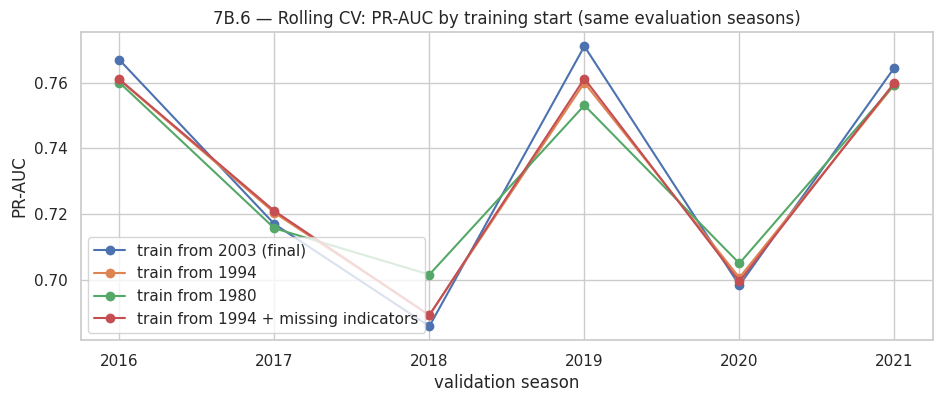

,Validation PR-AUC: train 1994–2019 − train 2003–2019
mean diff,-0.0041
CI low,-0.0104
CI high,0.0016
P(A > B),0.0810


Best mean CV PR-AUC: train from 2003 (final) | seasons beating the 2003 start: 0/6 | change the training window: False


In [50]:
# 7B.6 Pre-2003 training data. Feature rows for all seasons already exist in `feat` (Section 4); only the training rows change.
ALLDEV = feat[(feat.year >= 1980) & (feat.year <= 2021)][KEY + ['year', 'podium'] + FEATURES].reset_index(drop=True)
assert len(ALLDEV[ALLDEV.year >= 2003]) == len(DEV)          # 2003–2021 rows are exactly the rows used everywhere else
display(ALLDEV.assign(window=pd.cut(ALLDEV.year, [1979, 1993, 2002, 2021], labels=['1980–1993', '1994–2002', '2003–2021']))
        .groupby('window', observed=True)[FEATURES].apply(lambda d: d.isna().mean()).round(3).T.rename_axis('missing share'))

def lr_with_indicators():      # same model, plus 0/1 columns marking which values were imputed
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(),
                         LogisticRegression(C=10, max_iter=2000))

configs = {'train from 2003 (final)': (lr_spec, 2003), 'train from 1994': (lr_spec, 1994),
           'train from 1980': (lr_spec, 1980), 'train from 1994 + missing indicators': (lr_with_indicators, 1994)}
early = pd.DataFrame({name: cv_scores(spec, FEATURES, years=ERA_YEARS, train_start=s, data=ALLDEV)['PR-AUC'].values
                      for name, (spec, s) in configs.items()}, index=ERA_YEARS).rename_axis('validation season')
display(early.round(4))
base_col = 'train from 2003 (final)'
display(pd.DataFrame({'mean PR-AUC': early.mean(),
                      'seasons beating 2003-start': [(early[c] > early[base_col]).sum() for c in early],
                      'training rows (fold 2021)': [len(ALLDEV[(ALLDEV.year >= s) & (ALLDEV.year < 2021)]) for _, s in configs.values()]}).round(4))

early.plot(marker='o', figsize=(11, 4), title='7B.6 — Rolling CV: PR-AUC by training start (same evaluation seasons)')
plt.ylabel('PR-AUC'); save('cv_pre2003_start')

# Same question on the original validation split (train up to 2019, score 2020–2021), paired race-level bootstrap
tr94 = ALLDEV[(ALLDEV.year >= 1994) & (ALLDEV.year <= 2019)]
p94 = lr_spec().fit(tr94[FEATURES], tr94.podium).predict_proba(X_va)[:, 1]
display(pd.Series(bootstrap_diff(y_va, p94, VAL_PRED['LogReg'], VAL.raceId),
                  name='Validation PR-AUC: train 1994–2019 − train 2003–2019').round(4).to_frame())

best_start = early.mean().idxmax()
wins_start = (early[best_start] > early[base_col]).sum()
CHANGE_WINDOW = (best_start != base_col) and (wins_start > len(ERA_YEARS) / 2)
print(f'Best mean CV PR-AUC: {best_start} | seasons beating the 2003 start: {wins_start}/{len(ERA_YEARS)} | '
      f'change the training window: {CHANGE_WINDOW}')


### 7B.6 Pre-2003 training data — findings
- **How much is missing:** `quali_gap_pct` is missing for **100%** of rows in 1980–1993 and **54.7%** in 1994–2002, versus
  1.8% in 2003–2021. The other seven features are about equally complete in every window (grid and age 0%, form ≤ 1.7%,
  constructor rank 5.6–8.7%).
- **Rolling CV (2016–2021):** training from 2003 has the **highest mean PR-AUC (0.7340)**. Training from 1980 gives 0.7325
  (better in 2 of 6 seasons), from 1994 0.7318 (3 of 6) and from 1994 with missing-value indicators 0.7320 (3 of 6), even
  though the earlier windows have up to 2.25× more training rows (16,067 vs 7,141 in the last fold).
- **Validation bootstrap:** training on 1994–2019 instead of 2003–2019 changes PR-AUC by **−0.0041 (95% CI −0.0104 to
  +0.0016)**; the earlier start is better in only 8.1% of resamples.
- **Decision (rule fixed in advance): keep 2003.** No earlier start wins on mean CV PR-AUC or in most seasons.
- **Interpretation:** the differences are small (≤ 0.0022 mean PR-AUC), so older seasons do not badly hurt the model, but
  they add nothing either: more rows did not compensate for the missing qualifying gap, even when the model was told which
  values were filled in. *(Why exactly is a hypothesis: the pre-2003 rows teach the relationship with a median-filled
  qualifying gap instead of the real one.)* The 2003 start chosen from the coverage table in Section 4.1 is therefore also
  supported by a model-based test. Together with 7B.3 (later starts), training from 2003 is the best of the starts tested.


# 8. Explainability (XAI)
Three methods explain the final logistic regression model on the **test seasons** (no decisions are made from them):
1. **Permutation importance (global):** how much test PR-AUC drops when one feature's values are shuffled.
2. **SHAP (global + local):** each feature's contribution, in log-odds, to each individual prediction.
3. **LIME (local):** a simple surrogate model fitted around one prediction.
We then check whether the three methods agree, and explain three individual cases: a correct podium, a missed
podium and a false alarm.

LogReg             RandomForest        
                       mean PR-AUC drop     std mean PR-AUC drop     std
grid_pos                         0.2684  0.0228           0.1662  0.0189
drv_finish_pct_last15            0.1306  0.0196           0.0323  0.0095
quali_gap_pct                    0.0239  0.0133           0.0340  0.0140
con_podium_rate_last15           0.0187  0.0097           0.0137  0.0091
con_rank_before                  0.0156  0.0098           0.0007  0.0055
drv_finish_rate_last10           0.0065  0.0037           0.0019  0.0024
first_round                      0.0025  0.0036           0.0001  0.0002
driver_age                       0.0006  0.0059           0.0066  0.0044

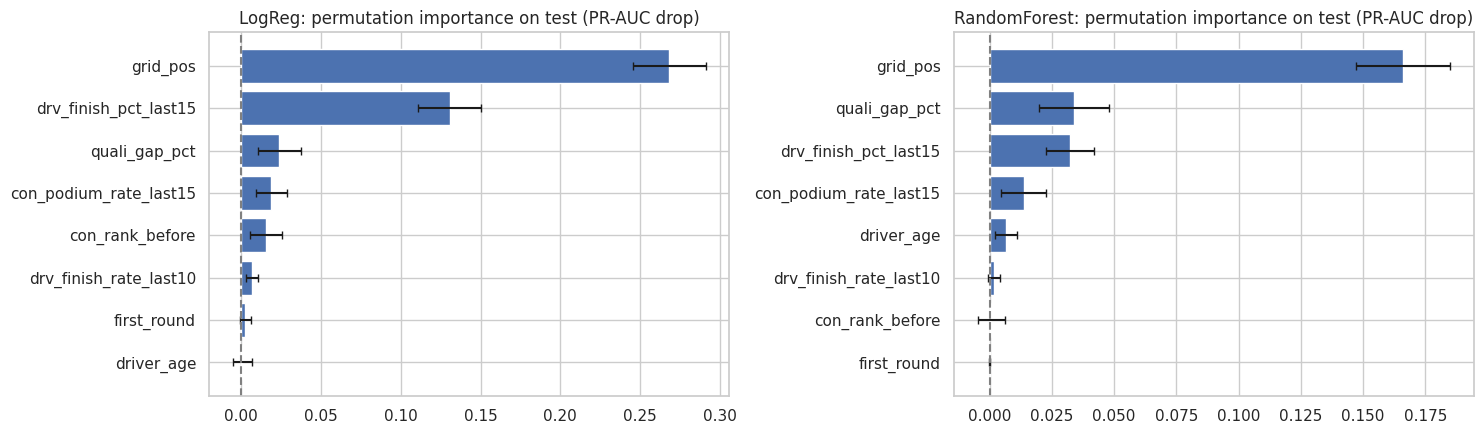

In [51]:
from sklearn.inspection import permutation_importance
final_model = MODELS['LogReg']

perm = {}
for name in ['LogReg', 'RandomForest']:
    r = permutation_importance(MODELS[name], X_te, y_te, scoring='average_precision', n_repeats=30, random_state=SEED, n_jobs=-1)
    perm[name] = pd.DataFrame({'mean PR-AUC drop': r.importances_mean, 'std': r.importances_std}, index=FEATURES)
display(pd.concat(perm, axis=1).round(4).sort_values(('LogReg', 'mean PR-AUC drop'), ascending=False))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, name in zip(ax, perm):
    d = perm[name].sort_values('mean PR-AUC drop')
    a.barh(d.index, d['mean PR-AUC drop'], xerr=d['std'], capsize=3); a.axvline(0, c='grey', ls='--')
    a.set_title(f'{name}: permutation importance on test (PR-AUC drop)')
plt.tight_layout(); save('xai_permutation')

### Permutation importance (test seasons)
- **Logistic regression:** shuffling `grid_pos` costs **0.268 PR-AUC**, `drv_finish_pct_last15` costs **0.131**, and every
  other feature costs ≤ 0.024. `driver_age` (0.0006 ± 0.006) and `first_round` (0.0025 ± 0.004) are indistinguishable
  from 0.
- **Random forest:** the same top feature (`grid_pos`, 0.166), but it relies more evenly on `quali_gap_pct` (0.034) and
  `drv_finish_pct_last15` (0.032), and hardly uses `con_rank_before` (0.0007).
- Both models agree that **grid position is the dominant input, and recent finishing form is second for the final model.**
  This matches the ablation (Section 7), where removing driver form significantly hurt logistic regression.

Background dataset has 6802 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=6802 when initializing the masker.


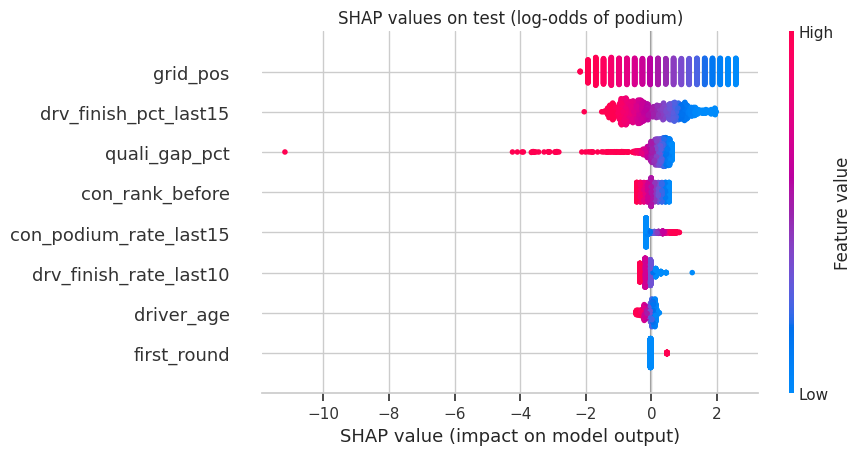

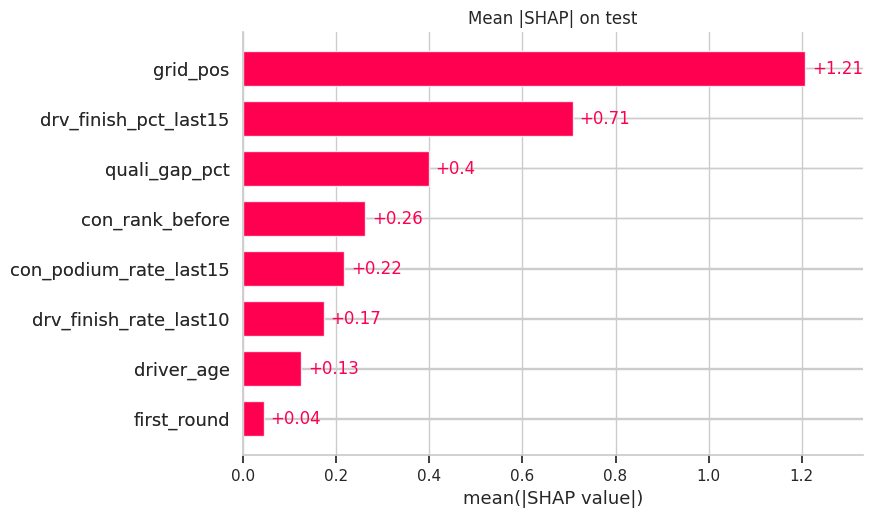

,mean |SHAP|
grid_pos,1.2075
drv_finish_pct_last15,0.7089
quali_gap_pct,0.3990
con_rank_before,0.2625
con_podium_rate_last15,0.2180
drv_finish_rate_last10,0.1743
driver_age,0.1251
first_round,0.0450


In [52]:
try:
    import shap
except ImportError:
    !pip install -q shap
    import shap

pre, clf = final_model[:-1], final_model[-1]
Xtr_t = pd.DataFrame(pre.transform(X_tr), columns=FEATURES)
Xte_t = pd.DataFrame(pre.transform(X_te), columns=FEATURES)
explainer = shap.LinearExplainer(clf, Xtr_t)
sv = explainer(Xte_t)
sv.data = pre[0].transform(X_te)          # show real (imputed, unscaled) feature values in the plots

plt.figure(); shap.plots.beeswarm(sv, max_display=8, show=False); plt.title('SHAP values on test (log-odds of podium)'); save('xai_shap_beeswarm')
plt.figure(); shap.plots.bar(sv, max_display=8, show=False); plt.title('Mean |SHAP| on test'); save('xai_shap_bar')
mean_abs_shap = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES)
display(mean_abs_shap.sort_values(ascending=False).round(4).to_frame('mean |SHAP|'))

### SHAP (global)
- Mean |SHAP| ranking: `grid_pos` (1.21) > `drv_finish_pct_last15` (0.71) > `quali_gap_pct` (0.40) > `con_rank_before`
  (0.26) > `con_podium_rate_last15` (0.22) > `drv_finish_rate_last10` (0.17) > `driver_age` (0.13) > `first_round` (0.045).
- **Directions (beeswarm):** a low grid number (blue) pushes the prediction up by as much as +2.6 log-odds, and a high
  one pushes it down. A low finishing percentile (good recent finishes) raises it. A high constructor podium rate raises it.
- **`quali_gap_pct` has a long negative tail**, down to about −11 log-odds. A driver far off pole pace is ruled out almost
  completely, which no other feature can do on its own.

,case,driver,team,season,circuit,grid,probability,actual podium
0,Correct podium (TP),max_verstappen,red_bull,2023,zandvoort,1,0.892,1
1,Missed podium (FN),gasly,alpine,2023,zandvoort,12,0.001,1
2,False alarm (FP),max_verstappen,red_bull,2024,albert_park,1,0.882,0


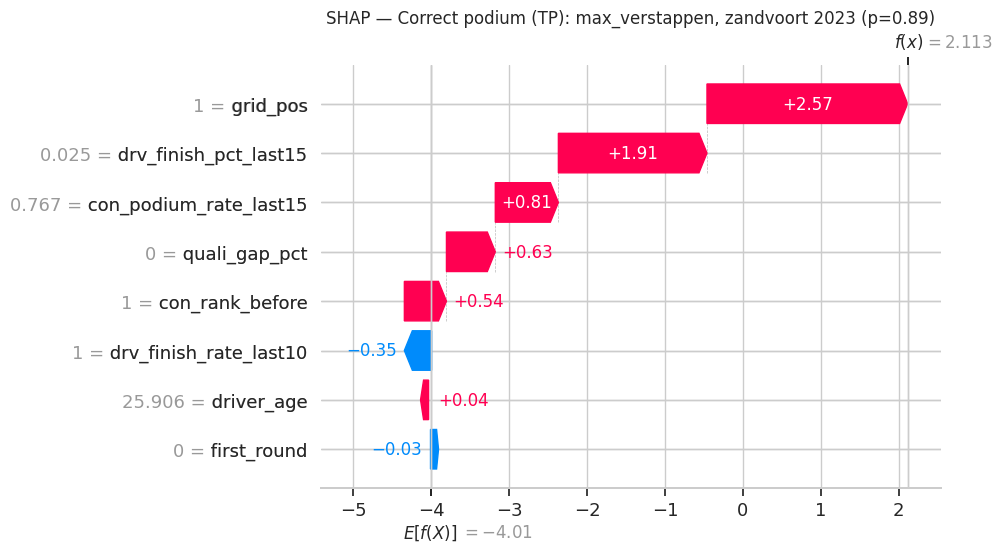

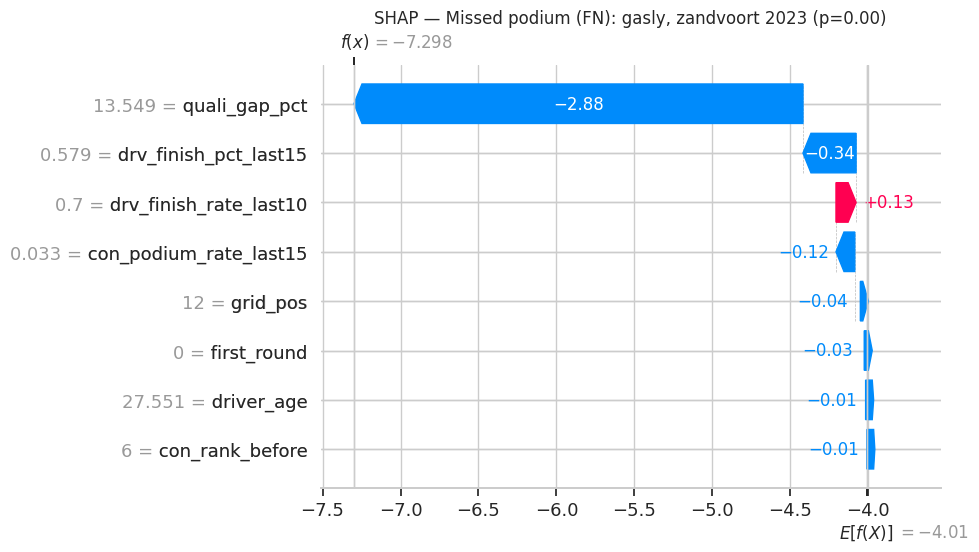

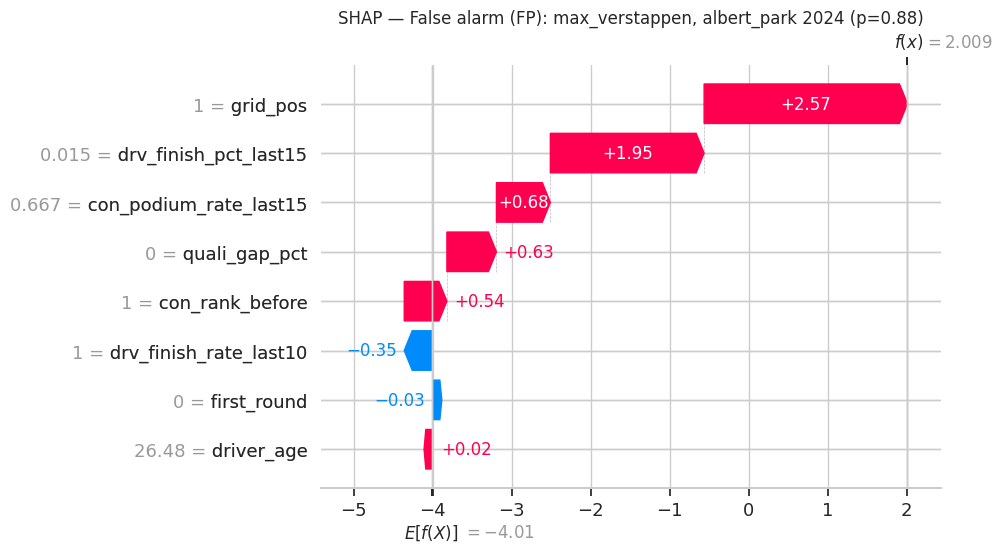

In [53]:
p_te, thr = TEST_PRED['LogReg'], THRESHOLDS['LogReg']
yv = y_te.values
cases = {
    'Correct podium (TP)':        int(np.argmax(np.where(yv == 1, p_te, -1))),
    'Missed podium (FN)':         int(np.argmin(np.where((yv == 1) & (p_te < thr), p_te, 2))),
    'False alarm (FP)':           int(np.argmax(np.where((yv == 0) & (p_te >= thr), p_te, -1))),
}
info = TEST.reset_index(drop=True)
case_table = pd.DataFrame([{'case': k, 'driver': info.driverRef[i], 'team': info.constructorRef[i], 'season': info.year[i],
                            'circuit': info.circuitRef[i], 'grid': info.grid_pos[i], 'probability': round(p_te[i], 3),
                            'actual podium': int(yv[i])} for k, i in cases.items()])
display(case_table)

for k, i in cases.items():
    plt.figure(); shap.plots.waterfall(sv[i], max_display=8, show=False)
    plt.title(f'SHAP — {k}: {info.driverRef[i]}, {info.circuitRef[i]} {info.year[i]} (p={p_te[i]:.2f})')
    save('xai_shap_' + k.split('(')[1][:2].lower())

### Three individual cases (SHAP waterfalls)
| Case | Driver | Race | Grid | Predicted | Actual |
|---|---|---|---|---|---|
| Correct podium | max_verstappen (red_bull) | Zandvoort 2023 | 1 | 0.892 | podium |
| Missed podium | gasly (alpine) | Zandvoort 2023 | 12 | 0.001 | podium |
| False alarm | max_verstappen (red_bull) | Albert Park 2024 | 1 | 0.882 | no podium |

- **Correct podium:** pole position (+2.57) and very strong recent finishes (`drv_finish_pct_last15` = 0.025, +1.91)
  dominate, supported by team form (`con_podium_rate_last15` = 0.767, +0.81), the fastest qualifying lap
  (`quali_gap_pct` = 0, +0.63) and the leading constructor (`con_rank_before` = 1, +0.54).
- **False alarm:** almost the same explanation as the correct case (pole +2.57, form +1.95, team form +0.68, quali +0.63,
  constructor rank +0.54). The input profile was that of a near-certain podium, and the driver did not finish on it.
  **The outcome depended on something no pre-race feature captures**, so the model was right to be confident given
  what it could see.
- **Missed podium:** the prediction is driven almost entirely by a very large qualifying gap (13.5% off the fastest lap,
  −2.88), with weaker recent finishes (−0.34) and low team form (−0.12). Grid P12 itself adds little (−0.04) once the
  qualifying gap is known. Every pre-race signal pointed against a podium: this is the kind of rare upset that limits
  any pre-race model.
- In both Verstappen cases `drv_finish_rate_last10` = 1 pushes the prediction down slightly (−0.35). This is the
  conditional coefficient noted in Section 6.2: it overlaps with the finishing percentile, so it should not be read
  on its own.


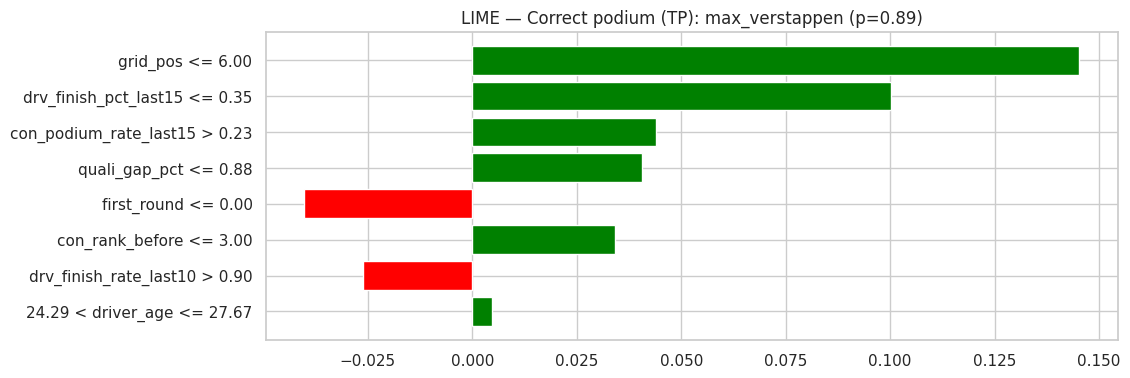

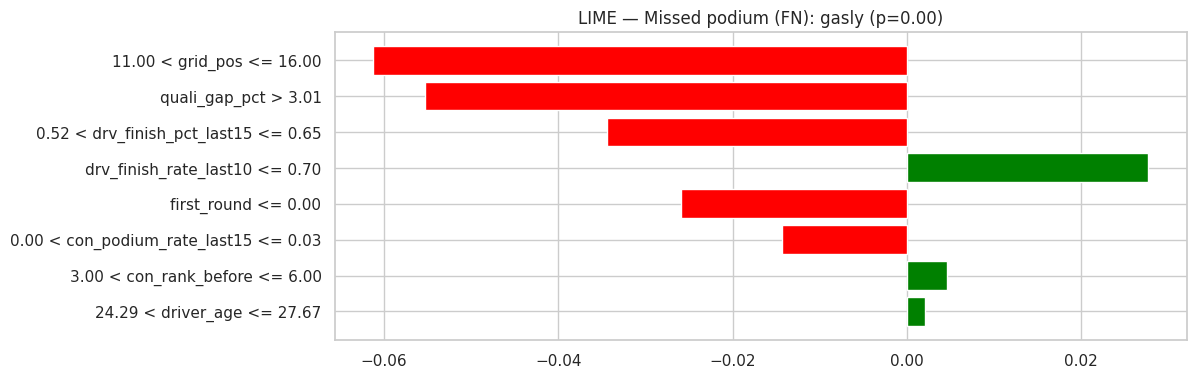

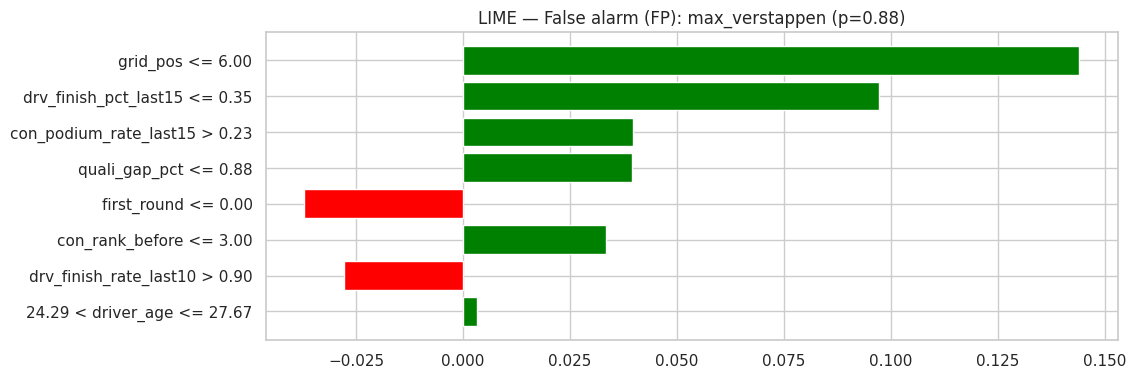

,case,SHAP top-3,LIME top-3,sign agreement (all 8)
0,Correct podium (TP),"[grid_pos, drv_finish_pct_last15, con_podium_r...","[grid_pos, drv_finish_pct_last15, con_podium_r...",8/8
1,Missed podium (FN),"[quali_gap_pct, drv_finish_pct_last15, drv_fin...","[grid_pos, quali_gap_pct, drv_finish_pct_last15]",6/8
2,False alarm (FP),"[grid_pos, drv_finish_pct_last15, con_podium_r...","[grid_pos, drv_finish_pct_last15, con_podium_r...",8/8


,permutation (PR-AUC drop),mean |SHAP|,mean |LIME|,permutation (PR-AUC drop) rank,mean |SHAP| rank,mean |LIME| rank
grid_pos,0.2684,1.2075,0.0724,1,1,1
drv_finish_pct_last15,0.1306,0.7089,0.0559,2,2,2
drv_finish_rate_last10,0.0065,0.1743,0.0153,6,6,7
quali_gap_pct,0.0239,0.3990,0.0254,3,3,4
con_podium_rate_last15,0.0187,0.2180,0.0213,4,5,5
driver_age,0.0006,0.1251,0.0112,8,7,8
con_rank_before,0.0156,0.2625,0.0190,5,4,6
first_round,0.0025,0.0450,0.0295,7,8,3


,permutation (PR-AUC drop),mean |SHAP|,mean |LIME|
Spearman rank correlation,,,
permutation (PR-AUC drop),1.000,0.952,0.762
mean |SHAP|,0.952,1.000,0.619
mean |LIME|,0.762,0.619,1.000


In [54]:
try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError:
    !pip install -q lime
    from lime.lime_tabular import LimeTabularExplainer

med = X_tr.median()
lime_exp = LimeTabularExplainer(X_tr.fillna(med).values, feature_names=FEATURES, class_names=['no podium', 'podium'],
                                mode='classification', discretize_continuous=True, random_state=SEED)
predict_fn = lambda a: final_model.predict_proba(pd.DataFrame(a, columns=FEATURES))
X_te_f = X_te.fillna(med).values

local_cmp = []
for k, i in cases.items():
    e = lime_exp.explain_instance(X_te_f[i], predict_fn, num_features=8)
    fig = e.as_pyplot_figure(); plt.title(f'LIME — {k}: {info.driverRef[i]} (p={p_te[i]:.2f})'); save('xai_lime_' + k.split('(')[1][:2].lower())
    lime_w = pd.Series(dict(e.as_map()[1])).rename(index=dict(enumerate(FEATURES)))
    shap_w = pd.Series(sv.values[i], index=FEATURES)
    local_cmp.append({'case': k, 'SHAP top-3': list(shap_w.abs().nlargest(3).index), 'LIME top-3': list(lime_w.abs().nlargest(3).index),
                      'sign agreement (all 8)': f"{(np.sign(shap_w) == np.sign(lime_w.reindex(FEATURES).fillna(0))).sum()}/8"})
display(pd.DataFrame(local_cmp))

# Global agreement: average |LIME weight| over 100 random test rows vs mean |SHAP| vs permutation importance
rng = np.random.default_rng(SEED)
sample = rng.choice(len(X_te_f), 100, replace=False)
lime_abs = np.zeros(len(FEATURES))
for i in sample:
    for j, w in lime_exp.explain_instance(X_te_f[i], predict_fn, num_features=8, num_samples=1000).as_map()[1]:
        lime_abs[j] += abs(w) / len(sample)
agree = pd.DataFrame({'permutation (PR-AUC drop)': perm['LogReg']['mean PR-AUC drop'], 'mean |SHAP|': mean_abs_shap,
                      'mean |LIME|': pd.Series(lime_abs, index=FEATURES)})
display(agree.round(4).assign(**{c + ' rank': agree[c].rank(ascending=False).astype(int) for c in agree.columns}))
display(agree.corr(method='spearman').round(3).rename_axis('Spearman rank correlation'))

### LIME and agreement between methods
- **Local agreement:** for the three cases, LIME and SHAP give the same sign for 8/8, 6/8 and 8/8 features. Their top-3 features
  match for both Verstappen cases; for the missed podium both put `quali_gap_pct` and `drv_finish_pct_last15` in the
  top 3, but LIME also ranks `grid_pos` there, while SHAP gives it little weight once the qualifying gap is known.
- **Global agreement (Spearman rank correlation):** permutation vs SHAP **0.952**, permutation vs LIME 0.762, SHAP vs LIME
  0.619. All three methods put `grid_pos` 1st and `drv_finish_pct_last15` 2nd.
- **Main disagreement: `first_round`** is ranked 3rd by LIME but 7th–8th by permutation and SHAP. LIME discretises
  features into bins, so the bin "first_round ≤ 0" gets a weight in nearly every explanation. SHAP measures deviation
  from the average row, and since almost every row has `first_round` = 0, its SHAP value is ≈ 0 (beeswarm). Permutation
  importance shows it barely affects test performance (0.0025). **We trust permutation importance and SHAP here.**
  They agree with each other (ρ = 0.95) and with the ablation, while LIME's bins inflate binary features.
- **Overall conclusion:** the model's reasoning is consistent and plausible. Starting position first, then recent
  finishing form, then qualifying pace and team strength.

# 9. Inference
The final model, its feature list, the validation-chosen threshold and the form-window settings are saved to one
file and loaded back, to show that predictions can be reproduced from the saved artifact alone.
`predict_race` returns podium probabilities for every starter of a race, using only features available before the
race (Section 4's leakage tests). `predict_driver` scores a single hand-entered driver for what-if questions.

In [55]:
import joblib
assert not set(FEATURES) & set(POST_RACE)                       # leakage guard: no race-result column is an input
joblib.dump({'model': FINAL_REFIT,                              # deployment model: refitted on 2003–2021 (Section 7B.5)
             'features': FEATURES, 'threshold': THRESHOLDS[FINAL],
             'form_windows': {'driver': W_DRV, 'constructor': W_CON}, 'trained_on': '2003–2021'}, 'f1_podium_model.joblib')
ART = joblib.load('f1_podium_model.joblib')
print('Loaded artifact:', {k: v for k, v in ART.items() if k != 'model'})

def predict_race(race_id, artifact=ART, features_table=feat):
    """Podium probability for every starter of `race_id`, from pre-race features only."""
    rows = features_table[features_table.raceId == race_id]
    if rows.empty:
        raise ValueError(f'raceId {race_id} not found')
    p = artifact['model'].predict_proba(rows[artifact['features']])[:, 1]
    out = rows[['year', 'round', 'circuitRef', 'driverRef', 'constructorRef', 'grid_pos']].assign(podium_prob=p)
    out['above_threshold'] = p >= artifact['threshold']                                   # full precision
    out['top3_pick'] = pd.Series(p, index=rows.index).rank(ascending=False, method='first') <= 3
    out = out.sort_values('podium_prob', ascending=False).reset_index(drop=True)
    out['podium_prob'] = out.podium_prob.round(3)                                         # round for display only
    return out

def predict_driver(artifact=ART, **inputs):
    """Podium probability for one driver. Every feature KEY must be given; a VALUE may be None/NaN
    (it is filled by the pipeline's training-median imputer). An omitted key raises an error on purpose."""
    omitted = set(artifact['features']) - set(inputs)
    if omitted:
        raise ValueError(f'required inputs not provided at all: {sorted(omitted)} (pass None if the value is unknown)')
    X = pd.DataFrame([inputs])[artifact['features']].astype(float)
    return float(artifact['model'].predict_proba(X)[0, 1])

# Demo 1: the last race in the test set, predictions vs what actually happened
last_race = TEST.loc[TEST.date.idxmax(), 'raceId']
pred = predict_race(last_race)
actual = base.loc[base.raceId == last_race, ['driverRef', 'positionOrder']]
display(pred.merge(actual, on='driverRef').rename(columns={'positionOrder': 'actual finish'}).head(10))

# Demo 2: what-if — the same driver row, changing only the starting position
row = X_te.iloc[cases['Correct podium (TP)']].to_dict()
display(pd.DataFrame([{'grid_pos': g, 'podium probability': round(predict_driver(**{**row, 'grid_pos': g}), 3)}
                      for g in [1, 3, 5, 10, 15]]))

# Demo 3: complete vs partially missing record
full = X_te.iloc[cases['Correct podium (TP)']].to_dict()
partial = {**full, 'quali_gap_pct': None, 'con_rank_before': None}
display(pd.DataFrame({'record': ['complete', 'partial (quali_gap_pct and con_rank_before missing)'],
                      'podium probability': [round(predict_driver(**full), 3), round(predict_driver(**partial), 3)]}))
imp = ART['model'][0]
print('Values used for the missing inputs (training medians):',
      {f: round(float(v), 3) for f, v in zip(ART['features'], imp.statistics_) if f in ('quali_gap_pct', 'con_rank_before')})
try:
    predict_driver(**{k: v for k, v in full.items() if k != 'grid_pos'})
except ValueError as e:
    print('Omitted key correctly rejected ->', e)

Loaded artifact: {'features': ['grid_pos', 'drv_finish_pct_last15', 'drv_finish_rate_last10', 'quali_gap_pct', 'con_podium_rate_last15', 'driver_age', 'con_rank_before', 'first_round'], 'threshold': np.float64(0.35626913515519776), 'form_windows': {'driver': 15, 'constructor': 15}, 'trained_on': '2003–2021'}


,year,round,circuitRef,driverRef,constructorRef,grid_pos,podium_prob,above_threshold,top3_pick,actual finish
0,2024,24,yas_marina,norris,mclaren,1,0.745,True,True,1
1,2024,24,yas_marina,piastri,mclaren,2,0.719,True,True,10
2,2024,24,yas_marina,max_verstappen,red_bull,4,0.507,True,True,6
3,2024,24,yas_marina,sainz,ferrari,3,0.491,True,False,2
4,2024,24,yas_marina,russell,mercedes,6,0.253,False,False,5
5,2024,24,yas_marina,gasly,alpine,5,0.066,False,False,7
6,2024,24,yas_marina,perez,red_bull,10,0.043,False,False,20
7,2024,24,yas_marina,hulkenberg,haas,7,0.040,False,False,8
8,2024,24,yas_marina,alonso,aston_martin,8,0.031,False,False,9
9,2024,24,yas_marina,leclerc,ferrari,19,0.020,False,False,3


,grid_pos,podium probability
0,1,0.893
1,3,0.839
2,5,0.764
3,10,0.499
4,15,0.234


,record,podium probability
0,complete,0.893
1,partial (quali_gap_pct and con_rank_before mis...,0.758


Values used for the missing inputs (training medians): {'quali_gap_pct': 1.792, 'con_rank_before': 6.0}
Omitted key correctly rejected -> required inputs not provided at all: ['grid_pos'] (pass None if the value is unknown)


### Inference — results
- **Deployment model:** the artifact holds the logistic regression **refitted on 2003–2021** (Section 7B.5), with its
  features, the validation-chosen threshold (0.356) and form windows (15/15). It reloads and reproduces predictions.
- **Demo, Yas Marina 2024 (last test race):** the model's top pick, norris (P1, p = 0.745), won. Its 2nd and 3rd picks,
  piastri (0.719) and max_verstappen (0.507), finished 10th and 6th. Two drivers the model rated lower did podium:
  sainz (0.491, 4th pick) finished 2nd, and leclerc started P19 with p = 0.020 and finished 3rd. That's 1 of 3 top-3
  picks correct in this race, which shows both the value and the limits described in Sections 6C and 7.
  *(This race is in the test seasons, which the refitted model never saw: it was trained on 2003–2021.)*
- **What-if (same driver, only grid changed):** podium probability falls from 0.893 at P1 to 0.839 (P3), 0.764 (P5),
  0.499 (P10) and 0.234 (P15). The model behaves monotonically and sensibly with respect to its most important input.
- **Partially missing record:** with `quali_gap_pct` and `con_rank_before` removed, the probability goes from 0.893
  (complete) to 0.758. The saved pipeline replaces each missing value with the training-set median (1.792% and rank 6,
  printed above), so prediction still works; the lower probability reflects that this driver's real values (fastest
  lap, leading team) were better than the medians. An entirely **omitted** input is rejected on purpose, so a caller
  cannot silently forget a feature.


# 10. Limitations
- **Historical coverage drift:** qualifying is complete only from 2003, so the model covers 2003–2024 only; form features
  draw on earlier eras with very different field sizes (Section 1). Training on earlier seasons with imputed qualifying
  data did not help (Section 7B.6), so the model cannot use the pre-2003 seasons as training rows.
- **First-round races:** no standings exist yet, so constructor rank is imputed; `first_round` flags this (Section 4.9).
- **Missing qualifying times** (~1–2% of modeling rows) are median-imputed.
- **Era sensitivity:** test PR-AUC varies by season (Section 6C) and by CV season (SD ≈ 0.08, Section 7B.1). Training on
  the recent era only did not help (Section 7B.3), so regulation changes remain a risk the model cannot adapt to quickly.
- **Small evaluation sets:** 39 validation races; model differences under ~0.03 PR-AUC are hard to detect (Section 5.2).
  Rolling CV over 10 seasons (Section 7B.1) gives more stable comparisons but confirms the differences are small.
- **Possible small gain from a flexible model:** in rolling CV the NN and random forest average ~0.01 PR-AUC above
  logistic regression. This was not established by our selection rule, and the NN result depends on its seed (7B.2).
- **Within-race ranking:** the model scores drivers independently and is not better than the grid rule at top-3 picks
  (Sections 7.3 and 7B.1). Race-relative features did not fix this (Section 7B.4).
- **Fixed threshold:** the threshold was tuned on 2020–21 and reused for the refitted model; test precision (0.60) is
  below validation (0.72), so it should be re-tuned as new seasons arrive.
- **Importance is not causation:** permutation importance, SHAP and LIME show what the model *relies on* to predict,
  not what *causes* a podium.
